In [1]:
import glob
import os
import pandas as pd

paths = [
    r"C:\Users\ruben\Desktop\TEG\EstadiumsDB.csv",
    r"C:\Users\ruben\Desktop\TEG\MacroEconomy2_imputado.csv",
    r"C:\Users\ruben\Desktop\TEG\TeamsEconomyDB.csv",
    r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\db_matches_final.csv",
    r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\db_matches_final_home.csv",
    r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\db_matches_final_away.csv",
]

open_meteo_dir = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\VSCode\open_meteo_out"
open_meteo_files = sorted(glob.glob(os.path.join(open_meteo_dir, "*_*.csv")))

all_files = paths + open_meteo_files

cols_by_file = {}
errors = {}

for p in all_files:
    try:
        df = pd.read_csv(p)
        cols_by_file[p] = list(df.columns)
    except Exception as exc:
        errors[p] = str(exc)

for p, cols in cols_by_file.items():
    print(p)
    print(cols)
    print("-")

if errors:
    print("Errors:")
    for p, msg in errors.items():
        print(p)
        print(msg)
        print("-")

C:\Users\ruben\Desktop\TEG\EstadiumsDB.csv
['Country', 'Team', 'id', 'Lat', 'Lon', 'Capacity', 'Height', 'Assist_1718', 'Assist_1819', 'Assist_1920', 'Assist_2021', 'Assist_2122', 'Assist_2223', 'Assist_2324', 'Assist_2425']
-
C:\Users\ruben\Desktop\TEG\MacroEconomy2_imputado.csv
['Country', 'Year', 'PIB', 'Inflation', 'IED', 'Population', 'Gini', 'GastoPublico', 'Deuda']
-
C:\Users\ruben\Desktop\TEG\TeamsEconomyDB.csv
['Country', 'Year', 'Semester', 'Team', 'Players', 'Foreign', 'MarketValue', 'Expenses', 'Income']
-
C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\db_matches_final.csv
['Team_id', 'Goals', 'Assists', 'GoalsPen', 'AttPen', 'Shots', 'ShTarget', 'YellowCard', 'RedCard', 'Fouls', 'FoulsD', 'Offside', 'Crosses', 'TacklesW', 'Interceptions', 'OwnGoals', 'PenKickGen', 'PenKickCon', 'home_team', 'away_team', 'Team', 'match_id', 'source_file', 'match_id_new', 'match_date', 'team_id_home', 'team_id_away', 'source_key', 'source_key_ascii', 'competition', 'competitio

In [2]:
# Build monthly historical averages per team from open_meteo files
import numpy as np

def parse_country_team_from_filename(path):
    base = os.path.basename(path)
    name, _ = os.path.splitext(base)
    parts = name.split("_")
    if len(parts) >= 2:
        country = parts[0]
        team = "_".join(parts[1:])
    else:
        country = ""
        team = name
    return country, team

monthly_team_frames = []
skipped_files = []

for file_path in open_meteo_files:
    df_team = pd.read_csv(file_path)
    if "date" not in df_team.columns:
        skipped_files.append((os.path.basename(file_path), list(df_team.columns)))
        continue
    country, team = parse_country_team_from_filename(file_path)
    df_team["Country"] = country
    df_team["Team"] = team
    # Parse date in YYYY-MM-DD format and extract month
    df_team["date"] = pd.to_datetime(df_team["date"], errors="coerce", format="%Y-%m-%d")
    df_team = df_team.dropna(subset=["date"])
    df_team["month"] = df_team["date"].dt.month

    # Build aggregation map to keep same columns + Country/Team
    agg_map = {}
    for col in df_team.columns:
        if col == "month":
            continue
        if col == "date":
            agg_map[col] = "first"
        elif pd.api.types.is_numeric_dtype(df_team[col]):
            agg_map[col] = "mean"
        else:
            agg_map[col] = "first"

    grouped = (
        df_team
        .sort_values(["month", "date"])
        .groupby(["month"], as_index=False)
        .agg(agg_map)
    )
    # Use a fixed year for readability; the actual year is not used in monthly means
    grouped["date"] = pd.to_datetime(
        dict(year=2000, month=grouped["month"], day=15), errors="coerce"
    )
    grouped = grouped.sort_values("date")
    grouped["month"] = grouped["date"].dt.month

    monthly_team_frames.append(grouped)

if skipped_files:
    print("Skipped files without date:")
    for name, cols in skipped_files:
        print(name)
        print(cols)
        print("-")

open_meteo_monthly = pd.concat(monthly_team_frames, ignore_index=True)
if "time" in open_meteo_monthly.columns:
    open_meteo_monthly = open_meteo_monthly.drop(columns=["time"])

if "date" in open_meteo_monthly.columns and "month" in open_meteo_monthly.columns:
    cols = list(open_meteo_monthly.columns)
    cols = [c for c in cols if c not in ["date", "month"]]
    open_meteo_monthly = open_meteo_monthly[["date", "month"] + cols]

print(open_meteo_monthly.shape)
open_meteo_monthly.head(30)


(5234, 9)


,date,month,temperature_2m,relative_humidity_2m,surface_pressure,ph2o_hpa,elevation,Country,Team
0,2000-01-15,1,6.175000,70.250000,1003.575000,6.963380,113.0,Albania,Tirana
1,2000-02-15,2,7.775000,65.125000,1008.337500,7.055801,113.0,Albania,Tirana
2,2000-03-15,3,11.287500,73.500000,1000.012500,9.713653,113.0,Albania,Tirana
3,2000-04-15,4,16.450000,62.000000,1001.225000,11.591105,113.0,Albania,Tirana
4,2000-05-15,5,19.362500,72.500000,998.512500,16.218382,113.0,Albania,Tirana
5,2000-06-15,6,23.225000,69.125000,998.600000,19.588656,113.0,Albania,Tirana
6,2000-07-15,7,27.825000,53.500000,998.212500,20.192243,113.0,Albania,Tirana
7,2000-08-15,8,27.466667,59.666667,999.211111,21.553465,113.0,Albania,Tirana
8,2000-09-15,9,22.177778,73.555556,1002.466667,19.605567,113.0,Albania,Tirana
9,2000-10-15,10,18.022222,70.444444,1002.744444,14.576192,113.0,Albania,Tirana


In [3]:
# Build monthly historical averages per team from open_meteo files
import numpy as np

def parse_country_team_from_filename(path):
    base = os.path.basename(path)
    name, _ = os.path.splitext(base)
    parts = name.split("_")
    if len(parts) >= 2:
        country = parts[0]
        team = "_".join(parts[1:])
    else:
        country = ""
        team = name
    return country, team

monthly_team_frames = []

for file_path in open_meteo_files:
    df_team = pd.read_csv(file_path)
    country, team = parse_country_team_from_filename(file_path)
    df_team["Country"] = country
    df_team["Team"] = team
    # Parse date in YYYY-MM-DD format and extract month
    df_team["date"] = pd.to_datetime(df_team["date"], errors="coerce", format="%Y-%m-%d")
    df_team = df_team.dropna(subset=["date"])
    df_team["month"] = df_team["date"].dt.month

    # Build aggregation map to keep same columns + Country/Team
    agg_map = {}
    for col in df_team.columns:
        if col == "month":
            continue
        if col == "date":
            agg_map[col] = "first"
        elif pd.api.types.is_numeric_dtype(df_team[col]):
            agg_map[col] = "mean"
        else:
            agg_map[col] = "first"

    grouped = (
        df_team
        .sort_values(["month", "date"])
        .groupby(["month"], as_index=False)
        .agg(agg_map)
    )
    # Use a fixed year for readability; the actual year is not used in monthly means
    grouped["date"] = pd.to_datetime(
        dict(year=2000, month=grouped["month"], day=15), errors="coerce"
    )
    grouped = grouped.sort_values("date")
    grouped["month"] = grouped["date"].dt.month

    monthly_team_frames.append(grouped)

open_meteo_monthly = pd.concat(monthly_team_frames, ignore_index=True)
if "time" in open_meteo_monthly.columns:
    open_meteo_monthly = open_meteo_monthly.drop(columns=["time"])

if "date" in open_meteo_monthly.columns and "month" in open_meteo_monthly.columns:
    cols = list(open_meteo_monthly.columns)
    cols = [c for c in cols if c not in ["date", "month"]]
    open_meteo_monthly = open_meteo_monthly[["date", "month"] + cols]

print(open_meteo_monthly.shape)
open_meteo_monthly.head(30)

(5234, 9)


,date,month,temperature_2m,relative_humidity_2m,surface_pressure,ph2o_hpa,elevation,Country,Team
0,2000-01-15,1,6.175000,70.250000,1003.575000,6.963380,113.0,Albania,Tirana
1,2000-02-15,2,7.775000,65.125000,1008.337500,7.055801,113.0,Albania,Tirana
2,2000-03-15,3,11.287500,73.500000,1000.012500,9.713653,113.0,Albania,Tirana
3,2000-04-15,4,16.450000,62.000000,1001.225000,11.591105,113.0,Albania,Tirana
4,2000-05-15,5,19.362500,72.500000,998.512500,16.218382,113.0,Albania,Tirana
5,2000-06-15,6,23.225000,69.125000,998.600000,19.588656,113.0,Albania,Tirana
6,2000-07-15,7,27.825000,53.500000,998.212500,20.192243,113.0,Albania,Tirana
7,2000-08-15,8,27.466667,59.666667,999.211111,21.553465,113.0,Albania,Tirana
8,2000-09-15,9,22.177778,73.555556,1002.466667,19.605567,113.0,Albania,Tirana
9,2000-10-15,10,18.022222,70.444444,1002.744444,14.576192,113.0,Albania,Tirana


In [4]:
# Build full historical records per team from open_meteo files (no aggregation)
historical_team_frames = []
skipped_files = []

for file_path in open_meteo_files:
    df_team = pd.read_csv(file_path)
    if "date" not in df_team.columns:
        skipped_files.append((os.path.basename(file_path), list(df_team.columns)))
        continue
    country, team = parse_country_team_from_filename(file_path)
    df_team["Country"] = country
    df_team["Team"] = team
    # Parse date in YYYY-MM-DD format and extract year/month
    df_team["date"] = pd.to_datetime(df_team["date"], errors="coerce", format="%Y-%m-%d")
    df_team = df_team.dropna(subset=["date"])
    df_team["year"] = df_team["date"].dt.year
    df_team["month"] = df_team["date"].dt.month

    historical_team_frames.append(df_team)

if skipped_files:
    print("Skipped files without date:")
    for name, cols in skipped_files:
        print(name)
        print(cols)
        print("-")

open_meteo_historical = pd.concat(historical_team_frames, ignore_index=True)
if "time" in open_meteo_historical.columns:
    open_meteo_historical = open_meteo_historical.drop(columns=["time"])

# Order columns: year, month, date, then the rest
cols = [c for c in open_meteo_historical.columns if c not in ["year", "month", "date"]]
open_meteo_historical = open_meteo_historical[["year", "month", "date"] + cols]

print(open_meteo_historical.shape)
open_meteo_historical.head(30)


(44038, 10)


,year,month,date,temperature_2m,relative_humidity_2m,surface_pressure,ph2o_hpa,elevation,Country,Team
0,2017,8,2017-08-15,25.4,66.0,1002.5,21.409345,113.0,Albania,Tirana
1,2017,9,2017-09-15,20.9,76.0,999.2,18.775933,113.0,Albania,Tirana
2,2017,10,2017-10-15,19.3,66.0,1011.7,14.767388,113.0,Albania,Tirana
3,2017,11,2017-11-15,11.6,94.0,1001.2,12.831144,113.0,Albania,Tirana
4,2017,12,2017-12-15,12.8,75.0,995.8,11.078849,113.0,Albania,Tirana
5,2018,1,2018-01-15,8.6,88.0,1008.0,9.827704,113.0,Albania,Tirana
6,2018,2,2018-02-15,6.0,68.0,1001.7,6.356777,113.0,Albania,Tirana
7,2018,3,2018-03-15,12.1,71.0,999.0,10.016707,113.0,Albania,Tirana
8,2018,4,2018-04-15,24.6,36.0,994.5,11.133355,113.0,Albania,Tirana
9,2018,5,2018-05-15,16.1,89.0,999.7,16.274296,113.0,Albania,Tirana


In [5]:
# Check team coverage: StadiumsDB vs open_meteo datasets
stadiums_path = r"C:\Users\ruben\Desktop\TEG\EstadiumsDB.csv"
stadiums_df = pd.read_csv(stadiums_path)

# Normalize known team name mismatch
stadiums_df["Team"] = stadiums_df["Team"].replace({"Paraná": "Parana"})
open_meteo_monthly["Team"] = open_meteo_monthly["Team"].replace({"Paran": "Parana"})
open_meteo_historical["Team"] = open_meteo_historical["Team"].replace({"Paran": "Parana"})

stadiums_teams = set(stadiums_df["Team"].dropna().astype(str).str.strip())
monthly_teams = set(open_meteo_monthly["Team"].dropna().astype(str).str.strip())
historical_teams = set(open_meteo_historical["Team"].dropna().astype(str).str.strip())

missing_in_monthly = sorted(stadiums_teams - monthly_teams)
missing_in_historical = sorted(stadiums_teams - historical_teams)

print(f"Teams in StadiumsDB: {len(stadiums_teams)}")
print(f"Teams in open_meteo_monthly: {len(monthly_teams)}")
print(f"Teams in open_meteo_historical: {len(historical_teams)}")
print("-")
print(f"Missing in open_meteo_monthly: {len(missing_in_monthly)}")
print(missing_in_monthly[:50])
print("-")
print(f"Missing in open_meteo_historical: {len(missing_in_historical)}")
print(missing_in_historical[:50])

Teams in StadiumsDB: 437
Teams in open_meteo_monthly: 438
Teams in open_meteo_historical: 438
-
Missing in open_meteo_monthly: 0
[]
-
Missing in open_meteo_historical: 0
[]


In [6]:
# Load macro, team economy, and matches datasets
macro_path = r"C:\Users\ruben\Desktop\TEG\MacroEconomy2_imputado.csv"
teams_econ_path = r"C:\Users\ruben\Desktop\TEG\TeamsEconomyDB.csv"
matches_path = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\db_matches_final.csv"
matches_home_path = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\db_matches_final_home.csv"
matches_away_path = r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\db_matches_final_away.csv"

macro_df = pd.read_csv(macro_path)
teams_econ_df = pd.read_csv(teams_econ_path)
matches_df = pd.read_csv(matches_path)
matches_home_df = pd.read_csv(matches_home_path)
matches_away_df = pd.read_csv(matches_away_path)

print("macro_df", macro_df.shape)
print("teams_econ_df", teams_econ_df.shape)
print("matches_df", matches_df.shape)
print("matches_home_df", matches_home_df.shape)
print("matches_away_df", matches_away_df.shape)

macro_df (135, 9)
teams_econ_df (6276, 9)
matches_df (76312, 34)
matches_home_df (38156, 35)
matches_away_df (38156, 35)


In [7]:
# Show columns (natural order) for all datasets
df_list = [
    ("stadiums_df", stadiums_df),
    ("open_meteo_monthly", open_meteo_monthly),
    ("open_meteo_historical", open_meteo_historical),
    ("macro_df", macro_df),
    ("teams_econ_df", teams_econ_df),
    ("matches_df", matches_df),
    ("matches_home_df", matches_home_df),
    ("matches_away_df", matches_away_df),
]

for name, df_obj in df_list:
    print(name)
    print(list(df_obj.columns))
    print("-")

stadiums_df
['Country', 'Team', 'id', 'Lat', 'Lon', 'Capacity', 'Height', 'Assist_1718', 'Assist_1819', 'Assist_1920', 'Assist_2021', 'Assist_2122', 'Assist_2223', 'Assist_2324', 'Assist_2425']
-
open_meteo_monthly
['date', 'month', 'temperature_2m', 'relative_humidity_2m', 'surface_pressure', 'ph2o_hpa', 'elevation', 'Country', 'Team']
-
open_meteo_historical
['year', 'month', 'date', 'temperature_2m', 'relative_humidity_2m', 'surface_pressure', 'ph2o_hpa', 'elevation', 'Country', 'Team']
-
macro_df
['Country', 'Year', 'PIB', 'Inflation', 'IED', 'Population', 'Gini', 'GastoPublico', 'Deuda']
-
teams_econ_df
['Country', 'Year', 'Semester', 'Team', 'Players', 'Foreign', 'MarketValue', 'Expenses', 'Income']
-
matches_df
['Team_id', 'Goals', 'Assists', 'GoalsPen', 'AttPen', 'Shots', 'ShTarget', 'YellowCard', 'RedCard', 'Fouls', 'FoulsD', 'Offside', 'Crosses', 'TacklesW', 'Interceptions', 'OwnGoals', 'PenKickGen', 'PenKickCon', 'home_team', 'away_team', 'Team', 'match_id', 'source_file', '

In [8]:
# Normalize team names using the review CSV and report missing mappings
review_path = r"C:\Users\ruben\Desktop\TEG\team_name_review.csv"
review_df = pd.read_csv(review_path)

# Build mapping raw_name -> normalized and allow normalized names to map to themselves
review_df = review_df.dropna(subset=["normalized", "raw_name"])
review_df["raw_name"] = review_df["raw_name"].astype(str).str.strip()
review_df["normalized"] = review_df["normalized"].astype(str).str.strip()
team_map = dict(zip(review_df["raw_name"], review_df["normalized"]))
normalized_set = set(review_df["normalized"].dropna().astype(str).str.strip())
for name in normalized_set:
    if name not in team_map:
        team_map[name] = name

# Manual overrides (neutral stadiums + match exceptions)
manual_overrides = {
    # Neutral stadiums
    "AlWakrah": "AlWakrah",
    "Aviva": "Aviva",
    "Budapest": "Budapest",
    "Dkiev": "Dkiev",
    "Fatih": "Fatih",
    "Fortuna": "Fortuna",
    "France": "France",
    "Gdansk": "Gdansk",
    "InterBaku": "InterBaku",
    "Khalifa": "Khalifa",
    "LVRaiders": "LVRaiders",
    "Levi": "Levi",
    "SoFi": "SoFi",
    "Tirana": "Tirana",
    "Wroclaw": "Wroclaw",
    # Matches exceptions
    "Aston Villa": "AstonVilla",
    "Atle Tucuman": "AtlTucuman",
    "Atletico Goianiense": "AtleticoGO",
    "Atletico Madrid": "AtlMadrid",
    "Atletico Mineiro": "AtleticoMG",
    "Atletico San Luis": "AtlSanLuis",
    "Atletico Venezuela": "AtlVenezuela",
    "America-MG":"AmericaMG",
    "Bolivar SC": "BolivarSC",
    "Busan IPark": "BusanIPark",
    "CF Montreal": "Montreal",
    "Cardiff City": "Cardiff",
    "Cen Cordoba–SdE": "CentralCordobaSdE",
    "Cen. Cordoba–SdE": "CentralCordobaSdE",
    "Club Olimpo": "Olimpo",
    "Crystal Palace": "CrystalPalace",
    "D C United": "DCUtd",
    "Dep Anzoategui": "DepAnzoategui",
    "Dep La Coruna": "DeporLaCoruna",
    "Deportivo Tachira": "DepTachira",
    "Estudiantes Merida": "EstMerida",
    "Estudiantes LP": "EstudiantesLP",
    "Estudiantes-LP": "EstudiantesLP",
    "FC Juarez": "Juarez",
    "Greuther Furth": "Greuther",
    "Gimnasia LP": "GimnasiaYEsgrimaLP",
    "Huddersfield Town": "Huddersfield",
    "Ind Rivadavia": "IndependienteRivadavia",
    "Ipswich Town": "Ipswich",
    "Jubilo Iwata": "JubiloIwata",
    "JeonbukHyundai": "JeonbukHyundai",
    "JeonbukHuyndai": "JeonbukHyundai",
    "Leeds United": "LeedsUtd",
    "Leicester City": "Leicester",
    "Luton Town": "Luton",
    "Manchester City": "ManCity",
    "Manchester Utd": "ManUtd",
    "ManUnited": "ManUtd",
    "NassajiManzandaran": "NassajiMazandaran",
    "Newcastle United": "Newcastle",
    "Norwich City": "Norwich",
    "Nottingham Forest": "NottsForest",
    "PontePreta": "PontePreta",
    "Sarmiento-J":"SarmientoJunin",
    "San Martin": "SanMartinTucuman",
    "San Martin SJ": "SanMartinSanJuan",
    "San Martin–SJ": "SanMartinSanJuan",
    "Sao Paulo": "SaoPaulo",
    "Sheffield United": "SheffieldUtd",
    "SpKansasCity": "SpoKansasCity",
    "SorkhPooshanFC": "Havadar",
    "St Louis City": "StLouisCity",
    "Stoke City": "Stoke",
    "Swansea City": "Swansea",
    "Talleres-C": "TalleresCordoba",
    "Tottenham Hotspur": "Spurs",
    "UnionSF": "UnionSantaFe",
    "V-Varen Nagasaki": "VVarenNagasaki",
    "Velez Sarsfield": "VelezSarsfield",
    "Volos N F C": "Volos",
    "West Brom": "WestBrom",
    "West Ham United": "WestHam",
    "Wolves": "Wolverhampton",
    "Yokohama F Marinos": "YokohamaMarinos",
}
team_map.update(manual_overrides)

def normalize_teams_in_df(df_obj: pd.DataFrame, cols_to_fix: list[str]) -> pd.DataFrame:
    df_out = df_obj.copy()
    for col in cols_to_fix:
        if col in df_out.columns:
            df_out[col] = df_out[col].astype(str).str.strip().replace(team_map)
            df_out.loc[df_out[col] == "nan", col] = np.nan
    return df_out

def find_missing_names(df_obj: pd.DataFrame, cols_to_check: list[str]) -> dict:
    missing = {}
    for col in cols_to_check:
        if col in df_obj.columns:
            values = df_obj[col].dropna().astype(str).str.strip()
            missing_vals = sorted(set(values) - set(team_map.keys()))
            missing[col] = missing_vals
    return missing

# Apply normalization to all loaded datasets
stadiums_df = normalize_teams_in_df(stadiums_df, ["Team"])
open_meteo_monthly = normalize_teams_in_df(open_meteo_monthly, ["Team"])
open_meteo_historical = normalize_teams_in_df(open_meteo_historical, ["Team"])
macro_df = normalize_teams_in_df(macro_df, ["Team", "team", "home_team", "away_team"])
teams_econ_df = normalize_teams_in_df(teams_econ_df, ["Team", "team", "home_team", "away_team"])
matches_df = normalize_teams_in_df(matches_df, ["Team", "team", "home_team", "away_team"])
matches_home_df = normalize_teams_in_df(matches_home_df, ["Team", "team", "home_team", "away_team"])
matches_away_df = normalize_teams_in_df(matches_away_df, ["Team", "team", "home_team", "away_team"])

missing_report = {
    "stadiums_df": find_missing_names(stadiums_df, ["Team"]),
    "open_meteo_monthly": find_missing_names(open_meteo_monthly, ["Team"]),
    "open_meteo_historical": find_missing_names(open_meteo_historical, ["Team"]),
    "macro_df": find_missing_names(macro_df, ["Team", "team", "home_team", "away_team"]),
    "teams_econ_df": find_missing_names(teams_econ_df, ["Team", "team", "home_team", "away_team"]),
    "matches_df": find_missing_names(matches_df, ["Team", "team", "home_team", "away_team"]),
    "matches_home_df": find_missing_names(matches_home_df, ["Team", "team", "home_team", "away_team"]),
    "matches_away_df": find_missing_names(matches_away_df, ["Team", "team", "home_team", "away_team"]),
}

for df_name, cols_missing in missing_report.items():
    print(df_name)
    for col, values in cols_missing.items():
        print(f"  {col}: {len(values)} missing")
        print(values[:50])
    print("-")

stadiums_df
  Team: 0 missing
[]
-
open_meteo_monthly
  Team: 0 missing
[]
-
open_meteo_historical
  Team: 0 missing
[]
-
macro_df
-
teams_econ_df
  Team: 2 missing
['Huracán', 'Paraná']
-
matches_df
  Team: 5 missing
['America–MG', 'Estudiantes–LP', 'Gimnasia–LP', 'Sarmiento–J', 'Talleres–C']
  home_team: 5 missing
['America–MG', 'Estudiantes–LP', 'Gimnasia–LP', 'Sarmiento–J', 'Talleres–C']
  away_team: 5 missing
['America–MG', 'Estudiantes–LP', 'Gimnasia–LP', 'Sarmiento–J', 'Talleres–C']
-
matches_home_df
  Team: 5 missing
['America–MG', 'Estudiantes–LP', 'Gimnasia–LP', 'Sarmiento–J', 'Talleres–C']
  home_team: 5 missing
['America–MG', 'Estudiantes–LP', 'Gimnasia–LP', 'Sarmiento–J', 'Talleres–C']
  away_team: 5 missing
['America–MG', 'Estudiantes–LP', 'Gimnasia–LP', 'Sarmiento–J', 'Talleres–C']
-
matches_away_df
  Team: 5 missing
['America–MG', 'Estudiantes–LP', 'Gimnasia–LP', 'Sarmiento–J', 'Talleres–C']
  home_team: 5 missing
['America–MG', 'Estudiantes–LP', 'Gimnasia–LP', 'Sarmien

In [9]:
# Derive year/month from match_id_new and optionally verify against date
def add_year_month_from_match_id(df_obj: pd.DataFrame, label: str) -> pd.DataFrame:
    df_out = df_obj.copy()
    if "match_id_new" not in df_out.columns:
        print(f"{label}: match_id_new not found")
        return df_out
    mid = df_out["match_id_new"].astype(str)
    df_out["year"] = pd.to_numeric(mid.str.slice(0, 4), errors="coerce")
    df_out["month"] = pd.to_numeric(mid.str.slice(4, 6), errors="coerce")
    # Optional check against date (DD-MM-YYYY) if present
    if "date" in df_out.columns:
        dt = pd.to_datetime(df_out["date"], errors="coerce", format="%d-%m-%Y")
        mismatch = (df_out["year"] != dt.dt.year) | (df_out["month"] != dt.dt.month)
        mismatch_count = mismatch.fillna(False).sum()
        print(f"{label}: date mismatch count = {mismatch_count}")
    return df_out

matches_df = add_year_month_from_match_id(matches_df, "matches_df")
matches_home_df = add_year_month_from_match_id(matches_home_df, "matches_home_df")
matches_away_df = add_year_month_from_match_id(matches_away_df, "matches_away_df")

In [10]:
# Compute PiO2 for open_meteo datasets
def add_pio2(df_obj: pd.DataFrame, label: str) -> pd.DataFrame:
    df_out = df_obj.copy()
    if "surface_pressure_2m" not in df_out.columns or "ph2o_hpa" not in df_out.columns:
        print(f"{label}: missing surface_pressure_2m or ph2o_hpa")
        return df_out
    df_out["PiO2"] = (df_out["surface_pressure_2m"] - df_out["ph2o_hpa"]) * 0.2095
    return df_out

open_meteo_monthly = add_pio2(open_meteo_monthly, "open_meteo_monthly")
open_meteo_historical = add_pio2(open_meteo_historical, "open_meteo_historical")

open_meteo_monthly: missing surface_pressure_2m or ph2o_hpa
open_meteo_historical: missing surface_pressure_2m or ph2o_hpa


In [11]:
# Detect pressure column name and compute PiO2 accordingly
def add_pio2_with_fallback(df_obj: pd.DataFrame, label: str) -> pd.DataFrame:
    df_out = df_obj.copy()
    pressure_col = None
    for candidate in ["surface_pressure_2m", "surface_pressure"]:
        if candidate in df_out.columns:
            pressure_col = candidate
            break
    if pressure_col is None or "ph2o_hpa" not in df_out.columns:
        print(f"{label}: missing {pressure_col or 'surface_pressure[_2m]'} or ph2o_hpa")
        return df_out
    df_out["PiO2"] = (df_out[pressure_col] - df_out["ph2o_hpa"]) * 0.2095
    print(f"{label}: PiO2 computed using {pressure_col}")
    return df_out

open_meteo_monthly = add_pio2_with_fallback(open_meteo_monthly, "open_meteo_monthly")
open_meteo_historical = add_pio2_with_fallback(open_meteo_historical, "open_meteo_historical")

open_meteo_monthly: PiO2 computed using surface_pressure
open_meteo_historical: PiO2 computed using surface_pressure


In [12]:
# Merge climate features into home/away matches using Team, year, month
climate_cols = [
    "temperature_2m",
    "relative_humidity_2m",
    "surface_pressure",
    "ph2o_hpa",
    "elevation",
    "PiO2",
 ]

def merge_climate(base_df: pd.DataFrame, team_col: str, prefix: str) -> pd.DataFrame:
    df_out = base_df.copy()
    team_col_use = team_col
    if team_col_use not in df_out.columns and "Team" in df_out.columns:
        team_col_use = "Team"
    if team_col_use not in df_out.columns:
        print(f"Missing team column for {prefix}: {team_col}")
        return df_out
    # Drop existing climate columns to keep reruns clean
    climate_bases = [f"{prefix}{c}" for c in climate_cols]
    climate_means = [f"{prefix}{c}_mean" for c in climate_cols]
    drop_existing = [
        c for c in df_out.columns
        if (c in climate_bases or c in climate_means)
        or (c.startswith(prefix) and any(core in c for core in climate_cols) and c.endswith(("_x", "_y")))
    ]
    if drop_existing:
        df_out = df_out.drop(columns=drop_existing, errors="ignore")
    # Monthly means (match by Team + month only)
    monthly_cols = [c for c in climate_cols if c in open_meteo_monthly.columns]
    monthly = open_meteo_monthly[["Team", "month"] + monthly_cols].copy()
    monthly = monthly.rename(columns={c: f"{prefix}{c}_mean" for c in monthly_cols})
    df_out = df_out.merge(
        monthly,
        left_on=[team_col_use, "month"],
        right_on=["Team", "month"],
        how="left",
    ).drop(columns=["Team"], errors="ignore")
    # Historical (match by Team + year + month)
    hist_cols = [c for c in climate_cols if c in open_meteo_historical.columns]
    historical = open_meteo_historical[["Team", "year", "month"] + hist_cols].copy()
    historical = historical.rename(columns={c: f"{prefix}{c}" for c in hist_cols})
    df_out = df_out.merge(
        historical,
        left_on=[team_col_use, "year", "month"],
        right_on=["Team", "year", "month"],
        how="left",
    ).drop(columns=["Team"], errors="ignore")
    return df_out

print("matches_home_df columns:", list(matches_home_df.columns))
print("matches_away_df columns:", list(matches_away_df.columns))

matches_home_df = merge_climate(matches_home_df, "home_team", "home_")
matches_away_df = merge_climate(matches_away_df, "away_team", "away_")

print("home added cols:", [c for c in matches_home_df.columns if c.startswith("home_") and any(x in c for x in climate_cols)])
print("away added cols:", [c for c in matches_away_df.columns if c.startswith("away_") and any(x in c for x in climate_cols)])

matches_home_df columns: ['home_team_id', 'home_goals', 'home_assists', 'home_goalspen', 'home_attpen', 'home_shots', 'home_shtarget', 'home_yellowcard', 'home_redcard', 'home_fouls', 'home_foulsd', 'home_offside', 'home_crosses', 'home_tacklesw', 'home_interceptions', 'home_owngoals', 'home_penkickgen', 'home_penkickcon', 'home_team', 'away_team', 'Team', 'match_id', 'source_file', 'match_id_new', 'match_date', 'team_id_home', 'team_id_away', 'source_key', 'source_key_ascii', 'competition', 'competition_raw', 'competition_raw_norm', 'Competition', 'match_date_from_id', 'Country', 'year', 'month']
matches_away_df columns: ['away_team_id', 'away_goals', 'away_assists', 'away_goalspen', 'away_attpen', 'away_shots', 'away_shtarget', 'away_yellowcard', 'away_redcard', 'away_fouls', 'away_foulsd', 'away_offside', 'away_crosses', 'away_tacklesw', 'away_interceptions', 'away_owngoals', 'away_penkickgen', 'away_penkickcon', 'home_team', 'away_team', 'Team', 'match_id', 'source_file', 'match_id

In [13]:
# Merge stadiums data into matches and compute Assist based on competition and season rules
simple_competitions = {
    "majorleaguesoccer",
    "ligaprofesionalargentina",
    "j1league",
    "futve",
    "brasileirao",
    "kleague1",
    "copalibertadores",
    "copasudamericana",
    "concacafchampionscup",
    "concacafchampionsleague",
    "fifaclubworldcup",
}
season_competitions = {
    "premierleague",
    "laliga",
    "ligue1",
    "ligamx",
    "bundesliga",
    "seriea",
    "saudiproleague",
    "persiangulfproleague",
    "superleaguegreece",
    "superligaargentina",
    "championsleague",
    "europaleague",
    "europaconferenceleague",
}

assist_cols = [c for c in stadiums_df.columns if c.startswith("Assist_")]

def pick_assist_value(row):
    comp = str(row.get("Competition", "")).strip().lower()
    year = row.get("year")
    month = row.get("month")
    if pd.isna(year) or pd.isna(month):
        return np.nan
    try:
        year = int(year)
        month = int(month)
    except Exception:
        return np.nan
    yy = year % 100
    simple_col = f"Assist_{yy:02d}"
    start_year = year if month > 6 else year - 1
    end_year = start_year + 1
    season_col = f"Assist_{start_year % 100:02d}{end_year % 100:02d}"
    if comp in simple_competitions:
        return row.get(simple_col, np.nan)
    if comp in season_competitions:
        return row.get(season_col, np.nan)
    # Fallback: try simple, then season if available
    if simple_col in row.index and pd.notna(row.get(simple_col)):
        return row.get(simple_col)
    if season_col in row.index and pd.notna(row.get(season_col)):
        return row.get(season_col)
    return np.nan

def merge_stadiums_home(base_df: pd.DataFrame) -> pd.DataFrame:
    df_out = base_df.copy()
    # Make reruns safe by dropping previously added columns
    drop_existing = [
        "home_Country",
        "home_Lat",
        "home_Lon",
        "home_Capacity",
        "home_Height",
        "home_Assist",
        "home_OccRat",
    ]
    df_out = df_out.drop(columns=[c for c in drop_existing if c in df_out.columns], errors="ignore")
    cols = ["Team", "Country", "Lat", "Lon", "Capacity", "Height"] + assist_cols
    stadiums_sub = stadiums_df[cols].copy()
    df_out = df_out.merge(
        stadiums_sub,
        left_on="home_team",
        right_on="Team",
        how="left",
        suffixes=("", "_stad"),
    )
    df_out["home_Assist"] = df_out.apply(pick_assist_value, axis=1)
    # Drop raw Assist_ columns and Team join column
    drop_cols = [c for c in assist_cols if c in df_out.columns] + ["Team"]
    df_out = df_out.drop(columns=drop_cols, errors="ignore")
    # Rename stadium columns with home_ prefix (prefer *_stad if present)
    if "Country_stad" in df_out.columns:
        df_out["home_Country"] = df_out["Country_stad"]
        df_out = df_out.drop(columns=["Country_stad"], errors="ignore")
    elif "Country" in df_out.columns:
        df_out = df_out.rename(columns={"Country": "home_Country"})
    if "Lat_stad" in df_out.columns:
        df_out["home_Lat"] = df_out["Lat_stad"]
        df_out = df_out.drop(columns=["Lat_stad"], errors="ignore")
    elif "Lat" in df_out.columns:
        df_out = df_out.rename(columns={"Lat": "home_Lat"})
    if "Lon_stad" in df_out.columns:
        df_out["home_Lon"] = df_out["Lon_stad"]
        df_out = df_out.drop(columns=["Lon_stad"], errors="ignore")
    elif "Lon" in df_out.columns:
        df_out = df_out.rename(columns={"Lon": "home_Lon"})
    if "Capacity_stad" in df_out.columns:
        df_out["home_Capacity"] = df_out["Capacity_stad"]
        df_out = df_out.drop(columns=["Capacity_stad"], errors="ignore")
    elif "Capacity" in df_out.columns:
        df_out = df_out.rename(columns={"Capacity": "home_Capacity"})
    if "Height_stad" in df_out.columns:
        df_out["home_Height"] = df_out["Height_stad"]
        df_out = df_out.drop(columns=["Height_stad"], errors="ignore")
    elif "Height" in df_out.columns:
        df_out = df_out.rename(columns={"Height": "home_Height"})
    # Occupation Rate = home_Assist / home_Capacity
    home_assist = pd.to_numeric(df_out.get("home_Assist"), errors="coerce")
    home_capacity = pd.to_numeric(df_out.get("home_Capacity"), errors="coerce")
    df_out["home_OccRat"] = home_assist / home_capacity
    return df_out

def merge_stadiums_away(base_df: pd.DataFrame) -> pd.DataFrame:
    df_out = base_df.copy()
    # Make reruns safe by dropping previously added columns
    drop_existing = [
        "away_Country",
        "away_Lat",
        "away_Lon",
        "away_Height",
    ]
    df_out = df_out.drop(columns=[c for c in drop_existing if c in df_out.columns], errors="ignore")
    cols = ["Team", "Country", "Lat", "Lon", "Height"]  # No Capacity or Assist for away teams
    stadiums_sub = stadiums_df[cols].copy()
    df_out = df_out.merge(
        stadiums_sub,
        left_on="away_team",
        right_on="Team",
        how="left",
        suffixes=("", "_stad"),
    )
    df_out = df_out.drop(columns=["Team"], errors="ignore")
    if "Country_stad" in df_out.columns:
        df_out["away_Country"] = df_out["Country_stad"]
        df_out = df_out.drop(columns=["Country_stad"], errors="ignore")
    elif "Country" in df_out.columns:
        df_out = df_out.rename(columns={"Country": "away_Country"})
    if "Lat_stad" in df_out.columns:
        df_out["away_Lat"] = df_out["Lat_stad"]
        df_out = df_out.drop(columns=["Lat_stad"], errors="ignore")
    elif "Lat" in df_out.columns:
        df_out = df_out.rename(columns={"Lat": "away_Lat"})
    if "Lon_stad" in df_out.columns:
        df_out["away_Lon"] = df_out["Lon_stad"]
        df_out = df_out.drop(columns=["Lon_stad"], errors="ignore")
    elif "Lon" in df_out.columns:
        df_out = df_out.rename(columns={"Lon": "away_Lon"})
    if "Height_stad" in df_out.columns:
        df_out["away_Height"] = df_out["Height_stad"]
        df_out = df_out.drop(columns=["Height_stad"], errors="ignore")
    elif "Height" in df_out.columns:
        df_out = df_out.rename(columns={"Height": "away_Height"})
    return df_out

matches_home_df = merge_stadiums_home(matches_home_df)
matches_away_df = merge_stadiums_away(matches_away_df)

print("home stadium cols:", [c for c in matches_home_df.columns if c.startswith("home_")])
print("away stadium cols:", [c for c in matches_away_df.columns if c.startswith("away_")])

home stadium cols: ['home_team_id', 'home_goals', 'home_assists', 'home_goalspen', 'home_attpen', 'home_shots', 'home_shtarget', 'home_yellowcard', 'home_redcard', 'home_fouls', 'home_foulsd', 'home_offside', 'home_crosses', 'home_tacklesw', 'home_interceptions', 'home_owngoals', 'home_penkickgen', 'home_penkickcon', 'home_team', 'home_temperature_2m_mean', 'home_relative_humidity_2m_mean', 'home_surface_pressure_mean', 'home_ph2o_hpa_mean', 'home_elevation_mean', 'home_PiO2_mean', 'home_temperature_2m', 'home_relative_humidity_2m', 'home_surface_pressure', 'home_ph2o_hpa', 'home_elevation', 'home_PiO2', 'home_Lat', 'home_Lon', 'home_Capacity', 'home_Height', 'home_Assist', 'home_Country', 'home_OccRat']
away stadium cols: ['away_team_id', 'away_goals', 'away_assists', 'away_goalspen', 'away_attpen', 'away_shots', 'away_shtarget', 'away_yellowcard', 'away_redcard', 'away_fouls', 'away_foulsd', 'away_offside', 'away_crosses', 'away_tacklesw', 'away_interceptions', 'away_owngoals', 'away

In [14]:
# Count unique Country values across datasets
def show_country_counts(df_obj: pd.DataFrame, label: str, col: str = "Country") -> None:
    if col not in df_obj.columns:
        print(f"{label}: column '{col}' not found")
        return
    values = df_obj[col].dropna().astype(str).str.strip()
    unique_vals = sorted(values.unique())
    print(f"{label}: {len(unique_vals)} unique {col}")
    print(unique_vals[:100])
    print("-")

show_country_counts(macro_df, "macro_df")
show_country_counts(teams_econ_df, "teams_econ_df")
show_country_counts(matches_home_df, "matches_home_df", col="home_Country")
show_country_counts(matches_away_df, "matches_away_df", col="away_Country")

macro_df: 15 unique Country
['Argentina', 'Brazil', 'France', 'Germany', 'Greece', 'Iran', 'Italy', 'Japan', 'Mexico', 'SaudiArabia', 'SouthKorea', 'Spain', 'UK', 'US', 'Venezuela']
-
teams_econ_df: 15 unique Country
['Argentina', 'Brasil', 'England', 'France', 'Germany', 'Greece', 'Iran', 'Italy', 'Japan', 'KoreaS', 'Mexico', 'Saudi', 'Spain', 'US', 'Venezuela']
-
matches_home_df: 15 unique home_Country
['Argentina', 'Brasil', 'England', 'France', 'Germany', 'Greece', 'Iran', 'Italy', 'Japan', 'KoreaS', 'Mexico', 'Saudi', 'Spain', 'US', 'Venezuela']
-
matches_away_df: 15 unique away_Country
['Argentina', 'Brasil', 'England', 'France', 'Germany', 'Greece', 'Iran', 'Italy', 'Japan', 'KoreaS', 'Mexico', 'Saudi', 'Spain', 'US', 'Venezuela']
-


In [15]:
# Normalize country names across datasets
country_map = {
    "Argentina": "Argentina",
    "Brasil": "Brazil",
    "Brazil": "Brazil",
    "France": "France",
    "Germany": "Germany",
    "Greece": "Greece",
    "Iran": "Iran",
    "Italy": "Italy",
    "Japan": "Japan",
    "Mexico": "Mexico",
    "Saudi": "SaudiArabia",
    "SaudiArabia": "SaudiArabia",
    "KoreaS": "SouthKorea",
    "SouthKorea": "SouthKorea",
    "Spain": "Spain",
    "UK": "England",
    "England": "England",
    "US": "USA",
    "USA": "USA",
    "Venezuela": "Venezuela",
}

def normalize_country_col(df_obj: pd.DataFrame, col: str) -> pd.DataFrame:
    if col not in df_obj.columns:
        return df_obj
    df_out = df_obj.copy()
    df_out[col] = df_out[col].astype(str).str.strip().replace(country_map)
    df_out.loc[df_out[col] == "nan", col] = np.nan
    return df_out

macro_df = normalize_country_col(macro_df, "Country")
teams_econ_df = normalize_country_col(teams_econ_df, "Country")
matches_home_df = normalize_country_col(matches_home_df, "home_Country")
matches_away_df = normalize_country_col(matches_away_df, "away_Country")

show_country_counts(macro_df, "macro_df")
show_country_counts(teams_econ_df, "teams_econ_df")
show_country_counts(matches_home_df, "matches_home_df", col="home_Country")
show_country_counts(matches_away_df, "matches_away_df", col="away_Country")

macro_df: 15 unique Country
['Argentina', 'Brazil', 'England', 'France', 'Germany', 'Greece', 'Iran', 'Italy', 'Japan', 'Mexico', 'SaudiArabia', 'SouthKorea', 'Spain', 'USA', 'Venezuela']
-
teams_econ_df: 15 unique Country
['Argentina', 'Brazil', 'England', 'France', 'Germany', 'Greece', 'Iran', 'Italy', 'Japan', 'Mexico', 'SaudiArabia', 'SouthKorea', 'Spain', 'USA', 'Venezuela']
-
matches_home_df: 15 unique home_Country
['Argentina', 'Brazil', 'England', 'France', 'Germany', 'Greece', 'Iran', 'Italy', 'Japan', 'Mexico', 'SaudiArabia', 'SouthKorea', 'Spain', 'USA', 'Venezuela']
-
matches_away_df: 15 unique away_Country
['Argentina', 'Brazil', 'England', 'France', 'Germany', 'Greece', 'Iran', 'Italy', 'Japan', 'Mexico', 'SaudiArabia', 'SouthKorea', 'Spain', 'USA', 'Venezuela']
-


In [16]:
# Drop rows in teams_econ_df only when all key microeconomic fields are missing
before_rows = len(teams_econ_df)
teams_econ_df = teams_econ_df.dropna(
    subset=["Players", "MarketValue", "Expenses", "Income"],
    how="all",
)
after_rows = len(teams_econ_df)
print(f"teams_econ_df rows before: {before_rows}")
print(f"teams_econ_df rows after: {after_rows}")

teams_econ_df rows before: 6276
teams_econ_df rows after: 4587


In [17]:
# Merge microeconomic features into matches based on Team, Year, Semester
micro_cols = ["Players", "Foreign", "MarketValue", "Income", "Expenses"]
required_cols = ["Team", "Year", "Semester"] + micro_cols
teams_econ_sub = teams_econ_df[required_cols].copy()

def add_semester_from_month(df_obj: pd.DataFrame) -> pd.Series:
    month = pd.to_numeric(df_obj.get("month"), errors="coerce")
    return np.where(month <= 6, 1, 2)

def merge_micro(base_df: pd.DataFrame, team_col: str, prefix: str) -> pd.DataFrame:
    df_out = base_df.copy()
    df_out["Semester"] = add_semester_from_month(df_out)
    # Remove existing prefixed columns if re-running
    drop_existing = [f"{prefix}{c}" for c in micro_cols]
    df_out = df_out.drop(columns=[c for c in drop_existing if c in df_out.columns], errors="ignore")
    merged = df_out.merge(
        teams_econ_sub,
        left_on=[team_col, "year", "Semester"],
        right_on=["Team", "Year", "Semester"],
        how="left",
        suffixes=("", "_econ"),
    )
    # Add prefixed columns
    for c in micro_cols:
        if c in merged.columns:
            merged[f"{prefix}{c}"] = merged[c]
    merged = merged.drop(columns=["Team", "Year", "Semester"] + micro_cols, errors="ignore")
    return merged

matches_home_df = merge_micro(matches_home_df, "home_team", "home_")
matches_away_df = merge_micro(matches_away_df, "away_team", "away_")

print("home micro cols:", [c for c in matches_home_df.columns if c.startswith("home_") and c.replace("home_", "") in micro_cols])
print("away micro cols:", [c for c in matches_away_df.columns if c.startswith("away_") and c.replace("away_", "") in micro_cols])

home micro cols: ['home_Players', 'home_Foreign', 'home_MarketValue', 'home_Income', 'home_Expenses']
away micro cols: ['away_Players', 'away_Foreign', 'away_MarketValue', 'away_Income', 'away_Expenses']


In [18]:
# Merge macroeconomic features into matches based on Country and Year
macro_cols = ["PIB", "Inflation", "IED", "Population", "Gini", "GastoPublico", "Deuda"]
macro_required = ["Country", "Year"] + macro_cols
macro_sub = macro_df[macro_required].copy()

def merge_macro(base_df: pd.DataFrame, country_col: str, prefix: str) -> pd.DataFrame:
    df_out = base_df.copy()
    # Remove existing prefixed columns if re-running
    drop_existing = [f"{prefix}{c}" for c in macro_cols]
    df_out = df_out.drop(columns=[c for c in drop_existing if c in df_out.columns], errors="ignore")
    merged = df_out.merge(
        macro_sub,
        left_on=[country_col, "year"],
        right_on=["Country", "Year"],
        how="left",
        suffixes=("", "_macro"),
    )
    for c in macro_cols:
        if c in merged.columns:
            merged[f"{prefix}{c}"] = merged[c]
    merged = merged.drop(columns=["Country", "Year"] + macro_cols, errors="ignore")
    return merged

matches_home_df = merge_macro(matches_home_df, "home_Country", "home_")
matches_away_df = merge_macro(matches_away_df, "away_Country", "away_")

print("home macro cols:", [c for c in matches_home_df.columns if c.startswith("home_") and c.replace("home_", "") in macro_cols])
print("away macro cols:", [c for c in matches_away_df.columns if c.startswith("away_") and c.replace("away_", "") in macro_cols])

home macro cols: ['home_PIB', 'home_Inflation', 'home_IED', 'home_Population', 'home_Gini', 'home_GastoPublico', 'home_Deuda']
away macro cols: ['away_PIB', 'away_Inflation', 'away_IED', 'away_Population', 'away_Gini', 'away_GastoPublico', 'away_Deuda']


In [19]:
# Show columns in current order for home and away matches
print("matches_home_df columns:")
print(list(matches_home_df.columns))
print("-")
print("matches_away_df columns:")
print(list(matches_away_df.columns))

matches_home_df columns:
['home_team_id', 'home_goals', 'home_assists', 'home_goalspen', 'home_attpen', 'home_shots', 'home_shtarget', 'home_yellowcard', 'home_redcard', 'home_fouls', 'home_foulsd', 'home_offside', 'home_crosses', 'home_tacklesw', 'home_interceptions', 'home_owngoals', 'home_penkickgen', 'home_penkickcon', 'home_team', 'away_team', 'Team_x', 'match_id', 'source_file', 'match_id_new', 'match_date', 'team_id_home', 'team_id_away', 'source_key', 'source_key_ascii', 'competition', 'competition_raw', 'competition_raw_norm', 'Competition', 'match_date_from_id', 'year', 'month', 'Team_y', 'home_temperature_2m_mean', 'home_relative_humidity_2m_mean', 'home_surface_pressure_mean', 'home_ph2o_hpa_mean', 'home_elevation_mean', 'home_PiO2_mean', 'home_temperature_2m', 'home_relative_humidity_2m', 'home_surface_pressure', 'home_ph2o_hpa', 'home_elevation', 'home_PiO2', 'home_Lat', 'home_Lon', 'home_Capacity', 'home_Height', 'home_Assist', 'home_Country', 'home_OccRat', 'home_Player

In [20]:
# Export pre-append snapshots
matches_home_df.to_csv("matches_home_pre.csv", index=False)
matches_away_df.to_csv("matches_away_pre.csv", index=False)
print("Saved: matches_home_pre.csv, matches_away_pre.csv")

Saved: matches_home_pre.csv, matches_away_pre.csv


In [21]:
# Add new advanced metrics for home and away, then reorder home columns
def add_adv_metrics(df_obj: pd.DataFrame, prefix: str) -> pd.DataFrame:
    df_out = df_obj.copy()
    attpen = pd.to_numeric(df_out.get(f"{prefix}attpen"), errors="coerce")
    shtarget = pd.to_numeric(df_out.get(f"{prefix}shtarget"), errors="coerce")
    tacklesw = pd.to_numeric(df_out.get(f"{prefix}tacklesw"), errors="coerce")
    interceptions = pd.to_numeric(df_out.get(f"{prefix}interceptions"), errors="coerce")
    fouls = pd.to_numeric(df_out.get(f"{prefix}fouls"), errors="coerce")
    crosses = pd.to_numeric(df_out.get(f"{prefix}crosses"), errors="coerce")
    foulsd = pd.to_numeric(df_out.get(f"{prefix}foulsd"), errors="coerce")
    diff = (shtarget - attpen).clip(lower=0)
    df_out[f"{prefix}xG_teo"] = (attpen * 0.795) + (diff * 0.358)
    df_out[f"{prefix}xG_teo_np"] = diff * 0.358
    df_out[f"{prefix}TDA"] = tacklesw + interceptions
    df_out[f"{prefix}DDI"] = df_out[f"{prefix}TDA"] / (df_out[f"{prefix}TDA"] + fouls + 1e-6)
    df_out[f"{prefix}xA_teo"] = (crosses * 0.059) + (foulsd * 0.0299)
    df_out[f"{prefix}xGA"] = df_out[f"{prefix}xG_teo_np"] + df_out[f"{prefix}xA_teo"]
    return df_out

matches_home_df = add_adv_metrics(matches_home_df, "home_")
matches_away_df = add_adv_metrics(matches_away_df, "away_")

# Reorder home columns with requested priority list
home_order = [
    "match_date_from_id", "Competition", "team_id_home", "home_team", "home_goals",
    "home_assists", "home_goalspen", "home_attpen", "home_shots", "home_shtarget",
    "home_yellowcard", "home_redcard", "home_fouls", "home_foulsd", "home_offside",
    "home_crosses", "home_tacklesw", "home_interceptions", "home_owngoals",
    "home_penkickgen", "home_penkickcon", "home_xG_teo", "home_xG_teo_np",
    "home_TDA", "home_DDI", "home_xA_teo", "home_xGA",
    "home_temperature_2m_mean", "home_relative_humidity_2m_mean", "home_surface_pressure_mean",
    "home_ph2o_hpa_mean", "home_elevation_mean", "home_PiO2_mean", "home_temperature_2m",
    "home_relative_humidity_2m", "home_surface_pressure", "home_ph2o_hpa", "home_elevation",
    "home_PiO2", "home_Lat", "home_Lon", "home_Capacity", "home_Height", "home_Assist",
    "home_Country", "home_OccRat", "home_Players", "home_Foreign", "home_MarketValue",
    "home_Income", "home_Expenses", "home_PIB", "home_Inflation", "home_IED",
    "home_Population", "home_Gini", "home_GastoPublico", "home_Deuda",
 ]
missing_home = [c for c in home_order if c not in matches_home_df.columns]
if missing_home:
    print("Missing home columns from requested order:", missing_home)
existing_home = [c for c in home_order if c in matches_home_df.columns]
remaining_home = [c for c in matches_home_df.columns if c not in existing_home]
matches_home_df = matches_home_df[existing_home + remaining_home]
print("Added columns:", [c for c in matches_home_df.columns if c.startswith("home_") and c in ["home_xG_teo","home_xG_teo_np","home_TDA","home_DDI","home_xA_teo","home_xGA"]])
print("Added columns:", [c for c in matches_away_df.columns if c.startswith("away_") and c in ["away_xG_teo","away_xG_teo_np","away_TDA","away_DDI","away_xA_teo","away_xGA"]])

Added columns: ['home_xG_teo', 'home_xG_teo_np', 'home_TDA', 'home_DDI', 'home_xA_teo', 'home_xGA']
Added columns: ['away_xG_teo', 'away_xG_teo_np', 'away_TDA', 'away_DDI', 'away_xA_teo', 'away_xGA']


In [22]:
# Export updated pre-append snapshots (v2)
matches_home_df.to_csv("matches_home_preV2.csv", index=False)
matches_away_df.to_csv("matches_away_preV2.csv", index=False)
print("Saved: matches_home_preV2.csv, matches_away_preV2.csv")

Saved: matches_home_preV2.csv, matches_away_preV2.csv


In [23]:
# Build final dataset in three explicit phases

# Phase 1: base columns from matches_home_df
base_cols = ["match_date_from_id", "match_id_new", "Competition"]
matches_final_df = matches_home_df[base_cols].copy()

# Phase 2: add home_* columns (except home_xOVA_nr) plus team_id_home -> home_team_id
home_cols = [
    c for c in matches_home_df.columns
    if c.startswith("home_") and c not in {"home_xOVA_nr", "home_team_id"}
 ]
home_extra = ["match_id_new"]
if "team_id_home" in matches_home_df.columns:
    home_extra.append("team_id_home")
home_sub = matches_home_df[home_extra + home_cols].copy()
if "team_id_home" in home_sub.columns:
    home_sub = home_sub.rename(columns={"team_id_home": "home_team_id"})
matches_final_df = matches_final_df.merge(home_sub, on="match_id_new", how="left")

# Phase 3: add away_* columns (except away_xOVA_nr) plus team_id_away -> away_team_id
away_cols = [
    c for c in matches_away_df.columns
    if c.startswith("away_") and c not in {"away_xOVA_nr", "away_team_id"}
 ]
away_extra = ["match_id_new"]
if "team_id_away" in matches_away_df.columns:
    away_extra.append("team_id_away")
away_sub = matches_away_df[away_extra + away_cols].copy()
if "team_id_away" in away_sub.columns:
    away_sub = away_sub.rename(columns={"team_id_away": "away_team_id"})
matches_final_df = matches_final_df.merge(away_sub, on="match_id_new", how="left")

print("matches_final_df shape:", matches_final_df.shape)
print("matches_final_df columns:", list(matches_final_df.columns))

matches_final_df shape: (38286, 112)
matches_final_df columns: ['match_date_from_id', 'match_id_new', 'Competition', 'home_team_id', 'home_team', 'home_goals', 'home_assists', 'home_goalspen', 'home_attpen', 'home_shots', 'home_shtarget', 'home_yellowcard', 'home_redcard', 'home_fouls', 'home_foulsd', 'home_offside', 'home_crosses', 'home_tacklesw', 'home_interceptions', 'home_owngoals', 'home_penkickgen', 'home_penkickcon', 'home_xG_teo', 'home_xG_teo_np', 'home_TDA', 'home_DDI', 'home_xA_teo', 'home_xGA', 'home_temperature_2m_mean', 'home_relative_humidity_2m_mean', 'home_surface_pressure_mean', 'home_ph2o_hpa_mean', 'home_elevation_mean', 'home_PiO2_mean', 'home_temperature_2m', 'home_relative_humidity_2m', 'home_surface_pressure', 'home_ph2o_hpa', 'home_elevation', 'home_PiO2', 'home_Lat', 'home_Lon', 'home_Capacity', 'home_Height', 'home_Assist', 'home_Country', 'home_OccRat', 'home_Players', 'home_Foreign', 'home_MarketValue', 'home_Income', 'home_Expenses', 'home_PIB', 'home_Inf

In [24]:
# Diagnostics for climate means, negative xG/xA, and missing Assist

# 1) Climate _mean coverage
mean_cols = [c for c in matches_home_df.columns if c.endswith("_mean")]
if mean_cols:
    mean_non_null = matches_home_df[mean_cols].notna().mean().sort_values(ascending=False)
    print("Top _mean non-null ratios:")
    print(mean_non_null.head(10))
else:
    print("No _mean columns found in matches_home_df")

print("open_meteo_monthly year unique:", sorted(open_meteo_monthly.get("year", pd.Series(dtype=float)).dropna().unique())[:10])
print("matches_home_df year range:", matches_home_df["year"].min(), "-", matches_home_df["year"].max())

# Check potential match by Team+month only
if {"Team", "month"}.issubset(open_meteo_monthly.columns):
    key_month = open_meteo_monthly[["Team", "month"]].drop_duplicates()
    check_month = matches_home_df[["home_team", "month"]].merge(
        key_month, left_on=["home_team", "month"], right_on=["Team", "month"], how="left", indicator=True
    )
    print("Team+month match rate:", (check_month["_merge"] == "both").mean())

# 2) Negative xG/xA checks
def show_negative_stats(df_obj: pd.DataFrame, prefix: str) -> None:
    cols = [f"{prefix}xG_teo", f"{prefix}xG_teo_np", f"{prefix}xA_teo", f"{prefix}xGA"]
    for col in cols:
        if col in df_obj.columns:
            neg_count = (df_obj[col] < 0).sum()
            min_val = df_obj[col].min()
            print(f"{col}: negatives={neg_count}, min={min_val}")
    if f"{prefix}shtarget" in df_obj.columns and f"{prefix}attpen" in df_obj.columns:
        diff = pd.to_numeric(df_obj[f"{prefix}shtarget"], errors="coerce") - pd.to_numeric(df_obj[f"{prefix}attpen"], errors="coerce")
        print(f"{prefix}shtarget - {prefix}attpen negatives:", (diff < 0).sum())

print("Negative check (home):")
show_negative_stats(matches_home_df, "home_")
print("Negative check (away):")
show_negative_stats(matches_away_df, "away_")

# 3) Missing Assist checks
if "home_Assist" in matches_home_df.columns:
    missing_assist = matches_home_df[matches_home_df["home_Assist"].isna()]
    print("Missing home_Assist rows:", len(missing_assist))
    if len(missing_assist) > 0:
        print("Top teams with missing home_Assist:")
        print(missing_assist["home_team"].value_counts().head(20))
        comp_counts = missing_assist["Competition"].astype(str).str.lower().value_counts().head(20)
        print("Top competitions with missing home_Assist:")
        print(comp_counts)
        in_lists = comp_counts.index.isin(simple_competitions.union(season_competitions))
        print("Competitions in known lists (top 20):", dict(zip(comp_counts.index[:20], in_lists[:20])))
        print("Missing year/month rows:", missing_assist["year"].isna().sum(), missing_assist["month"].isna().sum())

Top _mean non-null ratios:
home_temperature_2m_mean          0.985389
home_relative_humidity_2m_mean    0.985389
home_surface_pressure_mean        0.985389
home_ph2o_hpa_mean                0.985389
home_elevation_mean               0.985389
home_PiO2_mean                    0.985389
dtype: float64
open_meteo_monthly year unique: []
matches_home_df year range: 2017 - 2025
Team+month match rate: 0.985388845247447
Negative check (home):
home_xG_teo: negatives=0, min=0.0
home_xG_teo_np: negatives=0, min=0.0
home_xA_teo: negatives=0, min=0.0
home_xGA: negatives=0, min=0.0
home_shtarget - home_attpen negatives: 142
Negative check (away):
away_xG_teo: negatives=0, min=0.0
away_xG_teo_np: negatives=0, min=0.0
away_xA_teo: negatives=0, min=0.0
away_xGA: negatives=0, min=0.0
away_shtarget - away_attpen negatives: 105
Missing home_Assist rows: 15307
Top teams with missing home_Assist:
home_team
JeonbukHyundai       170
AcPtoCabello         167
DepTachira           164
Caracas              162
De

In [25]:
# Deep-dive: why home_Assist is missing
if "home_Assist" in matches_home_df.columns:
    missing_assist = matches_home_df[matches_home_df["home_Assist"].isna()].copy()
    missing_assist = missing_assist.merge(
        stadiums_df[["Team"] + assist_cols],
        left_on="home_team",
        right_on="Team",
        how="left",
        suffixes=("", "_stad"),
    )

    def expected_assist_col(row) -> str | None:
        comp = str(row.get("Competition", "")).strip().lower()
        year = row.get("year")
        month = row.get("month")
        if pd.isna(year) or pd.isna(month):
            return None
        try:
            year = int(year)
            month = int(month)
        except Exception:
            return None
        yy = year % 100
        simple_col = f"Assist_{yy:02d}"
        start_year = year if month > 6 else year - 1
        end_year = start_year + 1
        season_col = f"Assist_{start_year % 100:02d}{end_year % 100:02d}"
        if comp in simple_competitions:
            return simple_col
        if comp in season_competitions:
            return season_col
        return simple_col if simple_col in assist_cols else season_col if season_col in assist_cols else None

    missing_assist["expected_assist_col"] = missing_assist.apply(expected_assist_col, axis=1)
    missing_assist["team_found"] = missing_assist["Team"].notna()
    missing_assist["expected_col_found"] = missing_assist["expected_assist_col"].isin(assist_cols)
    missing_assist["expected_value_present"] = missing_assist.apply(
        lambda r: pd.notna(r.get(r["expected_assist_col"])) if r["expected_assist_col"] else False, axis=1
    )

    print("Missing home_Assist: team found in stadiums_df:", missing_assist["team_found"].mean())
    print("Missing home_Assist: expected Assist column exists:", missing_assist["expected_col_found"].mean())
    print("Missing home_Assist: expected Assist value present:", missing_assist["expected_value_present"].mean())
    print("Missing home_Assist: teams not found:")
    print(missing_assist.loc[~missing_assist["team_found"], "home_team"].value_counts().head(20))

Missing home_Assist: team found in stadiums_df: 0.9679885019925524
Missing home_Assist: expected Assist column exists: 0.011236689096491802
Missing home_Assist: expected Assist value present: 0.0
Missing home_Assist: teams not found:
home_team
Estudiantes–LP    120
Talleres–C        115
Gimnasia–LP       109
America–MG         77
Sarmiento–J        69
Name: count, dtype: int64


In [26]:
# Collect unique team_id values from home/away columns
home_ids = matches_home_df.get("home_team_id")
away_ids = matches_away_df.get("away_team_id")
team_ids = pd.concat([home_ids, away_ids], ignore_index=True).dropna().unique().tolist()
print("Unique team_id count:", len(team_ids))
team_ids[:20]

Unique team_id count: 415


['0230c3aa',
 '6b849eeb',
 'aa3eb1d3',
 'df40b697',
 '5835aae0',
 '8e3492b3',
 '9f29d583',
 'a42ddf2f',
 'f8106fc0',
 'fd6114db',
 'fe550dbf',
 '18d3c3a3',
 '272a9f59',
 '281b0e73',
 '54195385',
 'c02b0f7a',
 'd298ef2c',
 'd53c0b06',
 'd9e1bd51',
 'e2d8892c']

In [27]:
# Build per-team dataframes (home + away) with unified columns
base_cols = ["match_id_new", "match_date", "rivalgoals", "rivalpen"]
metric_cols = [
    "goals", "shtarget", "attpen", "goalspen", "TDA", "DDI", "xG_teo", "xG_teo_np", "xA_teo", "xGA", "team",
]
home_team_col = "home_team_id"
away_team_col = "away_team_id"

matches_home_df2 = matches_home_df.copy()
matches_away_df2 = matches_away_df.copy()

home_rival = matches_away_df2[["match_id_new", "away_goals", "away_goalspen"]].copy()
home_rival = home_rival.rename(columns={
    "away_goals": "rivalgoals",
    "away_goalspen": "rivalpen",
})
matches_home_df2 = matches_home_df2.merge(home_rival, on="match_id_new", how="left")

away_rival = matches_home_df[["match_id_new", "home_goals", "home_goalspen"]].copy()
away_rival = away_rival.rename(columns={
    "home_goals": "rivalgoals",
    "home_goalspen": "rivalpen",
})
matches_away_df2 = matches_away_df2.merge(away_rival, on="match_id_new", how="left")

def build_side_df(df_obj: pd.DataFrame, team_col: str, prefix: str, side_label: str) -> pd.DataFrame:
    cols = base_cols + [team_col] + [f"{prefix}{c}" for c in metric_cols]
    missing = [c for c in cols if c not in df_obj.columns]
    if missing:
        raise KeyError(f"Missing columns in {side_label}: {missing}")
    out = df_obj[cols].copy()
    out = out.rename(columns={team_col: "team_id"})
    rename_map = {f"{prefix}{c}": c for c in metric_cols}
    out = out.rename(columns=rename_map)
    out["side"] = side_label
    return out

home_side = build_side_df(matches_home_df2, home_team_col, "home_", "home")
away_side = build_side_df(matches_away_df2, away_team_col, "away_", "away")

team_dfs = {}
team_ids = pd.concat([home_side["team_id"], away_side["team_id"]], ignore_index=True).dropna().unique().tolist()
for tid in team_ids:
    home_tid = home_side[home_side["team_id"] == tid].copy()
    away_tid = away_side[away_side["team_id"] == tid].copy()
    team_dfs[tid] = pd.concat([home_tid, away_tid], ignore_index=True)

print("Total team_dfs:", len(team_dfs))
print("Example team_id:", team_ids[25] if team_ids else None)
print("Example df shape:", team_dfs[team_ids[25]].shape if team_ids else None)

Total team_dfs: 415
Example team_id: 69236f98
Example df shape: (261, 17)


In [28]:
team_dfs[team_ids[25]].head(5)

,match_id_new,match_date,rivalgoals,rivalpen,team_id,goals,shtarget,attpen,goalspen,TDA,DDI,xG_teo,xG_teo_np,xA_teo,xGA,team,side
0,20170806_69236f98_123f3efe,06-08-2017,2.0,0.0,69236f98,2.0,5.0,0.0,0.0,26.0,0.619048,1.790,1.790,1.2446,3.0346,Angers,home
1,20170827_69236f98_cb188c0c,27-08-2017,1.0,0.0,69236f98,1.0,2.0,0.0,0.0,22.0,0.666667,0.716,0.716,1.1840,1.9000,Angers,home
2,20170917_69236f98_f83960ae,17-09-2017,1.0,0.0,69236f98,0.0,5.0,0.0,0.0,26.0,0.650000,1.790,1.790,1.6859,3.4759,Angers,home
3,20171001_69236f98_d53c0b06,01-10-2017,3.0,0.0,69236f98,2.0,4.0,0.0,0.0,32.0,0.727273,1.432,1.432,2.6598,4.0918,Angers,home
4,20171021_69236f98_3f8c4b5f,21-10-2017,1.0,0.0,69236f98,0.0,4.0,0.0,0.0,24.0,0.685714,1.432,1.432,1.9825,3.4145,Angers,home


In [29]:
def compute_overall_drops(team_dfs, metrics, gap_thresholds, agg='mean'):
    all_drops = []
    if isinstance(team_dfs, dict):
        dataframes = list(team_dfs.values())
    else:
        dataframes = team_dfs
    
    for df in dataframes:
        if not isinstance(df, pd.DataFrame):
            continue
        available = [m for m in metrics if m in df.columns and df[m].notna().any()]
        if not available:
            continue
        df = df.copy()
        df['match_date'] = pd.to_datetime(df['match_date'], errors='coerce', dayfirst=True)
        df = df.sort_values('match_date').reset_index(drop=True)
        df = df.dropna(subset=['match_date'])
        df['gap_days'] = df['match_date'].diff().dt.days
        
        for i in range(1, len(df)):
            gap = df.loc[i, 'gap_days']
            if pd.isna(gap):
                continue
            for thresh in gap_thresholds:
                if gap > thresh:
                    pre = df.loc[i-1, available]
                    post = df.loc[i, available]
                    for m in available:
                        p = pre[m]
                        q = post[m]
                        if pd.notna(p) and pd.notna(q) and isinstance(p, (int, float)) and p != 0:
                            drop = (q - p) / p
                            all_drops.append({'gap_threshold': thresh, 'metric': m, 'drop_pct': drop})
    
    if not all_drops:
        return pd.DataFrame(columns=['gap_threshold'] + metrics)
    
    drops_df = pd.DataFrame(all_drops)
    if agg == 'median':
        result = drops_df.groupby(['gap_threshold', 'metric'])['drop_pct'].median().reset_index()
    else:  # mean
        result = drops_df.groupby(['gap_threshold', 'metric'])['drop_pct'].mean().reset_index()
    
    pivot = result.pivot(index='gap_threshold', columns='metric', values='drop_pct')
    pivot = pivot.reset_index().rename_axis(None, axis=1)
    return pivot

# Parámetros
metrics = ['xG_teo', 'xA_teo', 'DDI']
gaps = [20, 25, 30, 45]

# Calcular tabla con media
mean_table = compute_overall_drops(team_dfs, metrics, gaps, agg='mean')
print(mean_table)

   gap_threshold       DDI    xA_teo    xG_teo
0             20  0.019129  0.115416  0.335929
1             25  0.019350  0.114467  0.320862
2             30  0.018215  0.117881  0.318056
3             45  0.015279  0.120978  0.306165


In [30]:
# Compute rolling per team_df with inactivity rules (vectorized, single pass)
metric_cols = [
    "shtarget", "attpen", "goalspen", "TDA", "DDI", "xG_teo", "xG_teo_np", "xA_teo", "xGA",
]

rolling_window = 5
gap_reset_days = 40
gap_long_days = 50

def add_team_rollings_fast(df_team: pd.DataFrame) -> pd.DataFrame:
    df_out = df_team.copy()
    if df_out["match_date"].dtype != "datetime64[ns]":
        df_out["match_date"] = pd.to_datetime(
            df_out["match_date"], errors="coerce", dayfirst=True
        )
    df_out = df_out.sort_values(["match_id_new"]).reset_index(drop=True)
    df_out["gap_days"] = df_out["match_date"].diff().dt.days
    reset_flag = df_out["gap_days"].isna() | (df_out["gap_days"] > gap_reset_days)
    df_out["segment_id"] = reset_flag.cumsum() - 1
    first_gaps = df_out.groupby("segment_id", sort=False)["gap_days"].transform("first")
    is_rigorous = (df_out["segment_id"] == 0) | (first_gaps > gap_long_days)
    df_out["cum_count"] = df_out.groupby("segment_id", sort=False).cumcount() + 1

    for col in metric_cols:
        roll = (
            df_out.groupby("segment_id", sort=False)[col]
            .transform(lambda x: x.rolling(window=rolling_window, min_periods=2).mean().shift(1))
        )
        df_out[f"{col}_r5"] = np.where(
            is_rigorous & (df_out["cum_count"] < rolling_window),
            np.nan,
            roll,
        )

    rivalgoals = pd.to_numeric(df_out.get("rivalgoals"), errors="coerce")
    rivalpen = pd.to_numeric(df_out.get("rivalpen"), errors="coerce")
    gcon_roll = (
        pd.Series(rivalgoals, index=df_out.index)
        .groupby(df_out["segment_id"], sort=False)
        .transform(lambda x: x.rolling(window=rolling_window, min_periods=2).mean().shift(1))
    )
    df_out["Gcon_r5"] = np.where(
        is_rigorous & (df_out["cum_count"] < rolling_window),
        np.nan,
        gcon_roll,
    )
    gcon_np_series = rivalgoals - rivalpen
    gcon_np_roll = (
        pd.Series(gcon_np_series, index=df_out.index)
        .groupby(df_out["segment_id"], sort=False)
        .transform(lambda x: x.rolling(window=rolling_window, min_periods=2).mean().shift(1))
    )
    df_out["Gcon_np_r5"] = np.where(
        is_rigorous & (df_out["cum_count"] < rolling_window),
        np.nan,
        gcon_np_roll,
    )

    return df_out.drop(columns=["gap_days", "segment_id", "cum_count"])

team_dfs_rolled = {tid: add_team_rollings_fast(df) for tid, df in team_dfs.items()}
print("Rolled team_dfs_rolled:", len(team_dfs_rolled))
print("Example rolled shape:", team_dfs_rolled[team_ids[25]].shape if team_ids else None)

Rolled team_dfs_rolled: 415
Example rolled shape: (261, 28)


In [31]:
# Add goals/Gcon rolling features with multiple windows and home/away splits
def add_team_goals_rollings(df_team: pd.DataFrame) -> pd.DataFrame:
    df_out = df_team.copy()
    if df_out["match_date"].dtype != "datetime64[ns]":
        df_out["match_date"] = pd.to_datetime(
            df_out["match_date"], errors="coerce", dayfirst=True
        )
    df_out = df_out.sort_values(["match_id_new"]).reset_index(drop=True)
    #df_out["gap_days"] = df_out["match_date"].diff().dt.days
    #reset_flag = df_out["gap_days"].isna() | (df_out["gap_days"] > gap_reset_days)
    #df_out["segment_id"] = reset_flag.cumsum() - 1

    goals = pd.to_numeric(df_out.get("goals"), errors="coerce")
    gcon = pd.to_numeric(df_out.get("rivalgoals"), errors="coerce")
    df_out["_goals"] = goals
    df_out["_gcon"] = gcon
    df_out["_goals_home"] = np.where(df_out["side"] == "home", goals, np.nan)
    df_out["_goals_away"] = np.where(df_out["side"] == "away", goals, np.nan)
    df_out["_gcon_home"] = np.where(df_out["side"] == "home", gcon, np.nan)
    df_out["_gcon_away"] = np.where(df_out["side"] == "away", gcon, np.nan)

    windows = [5, 10, 20, 30]
    #grp = df_out.groupby("segment_id", sort=False)
    for w in windows:
        #df_out[f"goals_r{w}"] = grp["_goals"].transform(
            #lambda x: x.rolling(window=w, min_periods=1).mean().shift(1)
        #)
        #df_out[f"Gcon_r{w}"] = grp["_gcon"].transform(
            #lambda x: x.rolling(window=w, min_periods=1).mean().shift(1)
        #)
        #df_out[f"goals_home_r{w}"] = grp["_goals_home"].transform(
            #lambda x: x.rolling(window=w, min_periods=1).mean().shift(1)
        #)
        #df_out[f"Gcon_home_r{w}"] = grp["_gcon_home"].transform(
            #lambda x: x.rolling(window=w, min_periods=1).mean().shift(1)
        #)
        #df_out[f"goals_away_r{w}"] = grp["_goals_away"].transform(
            #lambda x: x.rolling(window=w, min_periods=1).mean().shift(1)
        #)
        #df_out[f"Gcon_away_r{w}"] = grp["_gcon_away"].transform(
            #lambda x: x.rolling(window=w, min_periods=1).mean().shift(1)
        #)
        df_out[f"goals_r{w}"] = df_out["_goals"].rolling(window=w, min_periods=1).mean().shift(1)
        df_out[f"Gcon_r{w}"] = df_out["_gcon"].rolling(window=w, min_periods=1).mean().shift(1)
        df_out[f"goals_home_r{w}"] = df_out["_goals"].rolling(window=w, min_periods=1).mean().shift(1)
        df_out[f"Gcon_home_r{w}"] = df_out["_gcon"].rolling(window=w, min_periods=1).mean().shift(1)
        df_out[f"goals_away_r{w}"] = df_out["_goals"].rolling(window=w, min_periods=1).mean().shift(1)
        df_out[f"Gcon_away_r{w}"] = df_out["_gcon"].rolling(window=w, min_periods=1).mean().shift(1)

    #drop_cols = ["gap_days", "segment_id", "_goals", "_gcon", "_goals_home", "_goals_away", "_gcon_home", "_gcon_away"]
    drop_cols = ["_goals", "_gcon", "_goals_home", "_goals_away", "_gcon_home", "_gcon_away"]
    return df_out.drop(columns=drop_cols)

team_dfs_goals_rolled = {tid: add_team_goals_rollings(df) for tid, df in team_dfs.items()}
print("Rolled team_dfs_goals_rolled:", len(team_dfs_goals_rolled))

goals_cols = []
for w in [5, 10, 20, 30]:
    goals_cols += [
        f"goals_r{w}", f"Gcon_r{w}",
        f"goals_home_r{w}", f"Gcon_home_r{w}",
        f"goals_away_r{w}", f"Gcon_away_r{w}",
    ]

goals_frames = []
for df_team in team_dfs_goals_rolled.values():
    cols = ["match_id_new", "side"] + goals_cols
    missing = [c for c in cols if c not in df_team.columns]
    if missing:
        raise KeyError(f"Missing columns in team_dfs_goals_rolled df: {missing}")
    goals_frames.append(df_team[cols])

goals_long = pd.concat(goals_frames, ignore_index=True)
goals_long = goals_long.drop_duplicates(subset=['match_id_new', 'side'], keep='first')
goals_home = goals_long[goals_long["side"] == "home"].copy()
goals_away = goals_long[goals_long["side"] == "away"].copy()
goals_home = goals_home.drop(columns=["side"]).rename(columns={c: f"home_{c}" for c in goals_cols})
goals_away = goals_away.drop(columns=["side"]).rename(columns={c: f"away_{c}" for c in goals_cols})
print("Prepared goals rollings:", len(goals_cols) * 2, "columns")

Rolled team_dfs_goals_rolled: 415
Prepared goals rollings: 48 columns


In [32]:
sample_id = team_ids[25]
sample_goals = team_dfs_goals_rolled[sample_id]
for w in [5,10,20,30]:
    for cond in ['home', 'away']:
        col = f"goals_{cond}_r{w}"
        nan_pct = sample_goals[col].isna().mean()
        print(f"{col}: {nan_pct:.1%} NaN")

goals_home_r5: 2.7% NaN
goals_away_r5: 2.7% NaN
goals_home_r10: 0.8% NaN
goals_away_r10: 0.8% NaN
goals_home_r20: 0.4% NaN
goals_away_r20: 0.4% NaN
goals_home_r30: 0.4% NaN
goals_away_r30: 0.4% NaN


In [33]:
# Validate rolling columns exist in a sample team_df
expected_r5 = [f"{c}_r5" for c in metric_cols]
expected_goals = []
for w in [5, 10, 20, 30]:
    expected_goals += [
        f"goals_r{w}", f"Gcon_r{w}",
        f"goals_home_r{w}", f"Gcon_home_r{w}",
        f"goals_away_r{w}", f"Gcon_away_r{w}",
    ]
if team_ids:
    sample_id = team_ids[25]
    sample_df = team_dfs_rolled[sample_id]
    missing = [c for c in expected_r5 if c not in sample_df.columns]
    print("Sample team_id:", sample_id)
    print("Missing r5 columns:", missing)
    print("Total r5 columns:", len([c for c in sample_df.columns if c.endswith('_r5')]))
    sample_goals_df = team_dfs_rolled[sample_id]
    missing_goals = [c for c in expected_goals if c not in sample_goals_df.columns]
    print("Missing goals columns:", missing_goals)
    print("Total goals columns:", len([c for c in sample_goals_df.columns if '_r' in c and ('goals' in c or 'Gcon' in c)]))
else:
    print("team_ids is empty")
print("Example rolled shape:", team_dfs_rolled[team_ids[25]].shape if team_ids else None)

Sample team_id: 69236f98
Missing r5 columns: []
Total r5 columns: 11
Missing goals columns: ['goals_r5', 'goals_home_r5', 'Gcon_home_r5', 'goals_away_r5', 'Gcon_away_r5', 'goals_r10', 'Gcon_r10', 'goals_home_r10', 'Gcon_home_r10', 'goals_away_r10', 'Gcon_away_r10', 'goals_r20', 'Gcon_r20', 'goals_home_r20', 'Gcon_home_r20', 'goals_away_r20', 'Gcon_away_r20', 'goals_r30', 'Gcon_r30', 'goals_home_r30', 'Gcon_home_r30', 'goals_away_r30', 'Gcon_away_r30']
Total goals columns: 3
Example rolled shape: (261, 28)


In [34]:
for team_ids in team_dfs_goals_rolled:
    print("Example rolled shape:", team_dfs_rolled[team_ids].shape if team_ids else None)

Example rolled shape: (238, 28)
Example rolled shape: (118, 28)
Example rolled shape: (239, 28)
Example rolled shape: (59, 28)
Example rolled shape: (88, 28)
Example rolled shape: (111, 28)
Example rolled shape: (149, 28)
Example rolled shape: (282, 28)
Example rolled shape: (239, 28)
Example rolled shape: (310, 28)
Example rolled shape: (239, 28)
Example rolled shape: (358, 28)
Example rolled shape: (66, 28)
Example rolled shape: (296, 28)
Example rolled shape: (114, 28)
Example rolled shape: (300, 28)
Example rolled shape: (226, 28)
Example rolled shape: (321, 28)
Example rolled shape: (345, 28)
Example rolled shape: (367, 28)
Example rolled shape: (185, 28)
Example rolled shape: (315, 28)
Example rolled shape: (84, 28)
Example rolled shape: (308, 28)
Example rolled shape: (325, 28)
Example rolled shape: (261, 28)
Example rolled shape: (316, 28)
Example rolled shape: (29, 28)
Example rolled shape: (244, 28)
Example rolled shape: (29, 28)
Example rolled shape: (253, 28)
Example rolled

In [35]:
# Append r5 columns and goals/Gcon windows to matches_final_df using side + match_id_new
r5_cols = [
    "shtarget_r5", "attpen_r5", "goalspen_r5", "TDA_r5", "DDI_r5",
    "xG_teo_r5", "xG_teo_np_r5", "xA_teo_r5", "xGA_r5", "Gcon_np_r5",
]

r5_frames = []
for df_team in team_dfs_rolled.values():
    cols = ["match_id_new", "side"] + r5_cols
    missing = [c for c in cols if c not in df_team.columns]
    if missing:
        raise KeyError(f"Missing columns in team_dfs_rolled df: {missing}")
    r5_frames.append(df_team[cols])

r5_long = pd.concat(r5_frames, ignore_index=True)
r5_long = r5_long.drop_duplicates(subset=['match_id_new', 'side'], keep='first')
r5_home = r5_long[r5_long["side"] == "home"].copy()
r5_away = r5_long[r5_long["side"] == "away"].copy()
r5_home = r5_home.drop(columns=["side"]).rename(columns={c: f"home_{c}" for c in r5_cols})
r5_away = r5_away.drop(columns=["side"]).rename(columns={c: f"away_{c}" for c in r5_cols})

all_roll_cols = r5_cols + goals_cols
drop_existing = [c for c in matches_final_df.columns if c.startswith("home_") and c.replace("home_", "") in all_roll_cols]
drop_existing += [c for c in matches_final_df.columns if c.startswith("away_") and c.replace("away_", "") in all_roll_cols]
if drop_existing:
    matches_final_df = matches_final_df.drop(columns=drop_existing, errors="ignore")

matches_final_df = matches_final_df.merge(r5_home, on="match_id_new", how="left")
matches_final_df = matches_final_df.merge(r5_away, on="match_id_new", how="left")
matches_final_df = matches_final_df.merge(goals_home, on="match_id_new", how="left")
matches_final_df = matches_final_df.merge(goals_away, on="match_id_new", how="left")

drop_mismatch = [c for c in matches_final_df.columns if c.startswith("home_") and "_away_" in c]
drop_mismatch += [c for c in matches_final_df.columns if c.startswith("away_") and "_home_" in c]
if drop_mismatch:
    matches_final_df = matches_final_df.drop(columns=drop_mismatch)
print("Added rollings:", len(all_roll_cols) * 2, "columns")
print("Columns: ", all_roll_cols)

Added rollings: 68 columns
Columns:  ['shtarget_r5', 'attpen_r5', 'goalspen_r5', 'TDA_r5', 'DDI_r5', 'xG_teo_r5', 'xG_teo_np_r5', 'xA_teo_r5', 'xGA_r5', 'Gcon_np_r5', 'goals_r5', 'Gcon_r5', 'goals_home_r5', 'Gcon_home_r5', 'goals_away_r5', 'Gcon_away_r5', 'goals_r10', 'Gcon_r10', 'goals_home_r10', 'Gcon_home_r10', 'goals_away_r10', 'Gcon_away_r10', 'goals_r20', 'Gcon_r20', 'goals_home_r20', 'Gcon_home_r20', 'goals_away_r20', 'Gcon_away_r20', 'goals_r30', 'Gcon_r30', 'goals_home_r30', 'Gcon_home_r30', 'goals_away_r30', 'Gcon_away_r30']


In [36]:
# Export current final dataset snapshot for review
matches_final_df = matches_final_df.drop_duplicates(subset=['match_id_new'], keep='first')
matches_final_df.to_csv("matches_final_precheck.csv", index=False)
print("Saved: matches_final_precheck.csv")

Saved: matches_final_precheck.csv


In [37]:
# Add xOVA and xOVA_r5 to matches_final_df
home_xga = pd.to_numeric(matches_final_df.get("home_xGA"), errors="coerce")
away_xga = pd.to_numeric(matches_final_df.get("away_xGA"), errors="coerce")
home_xa = pd.to_numeric(matches_final_df.get("home_xA_teo"), errors="coerce")
away_xa = pd.to_numeric(matches_final_df.get("away_xA_teo"), errors="coerce")

matches_final_df["home_xOVA"] = home_xga - away_xa
matches_final_df["away_xOVA"] = away_xga - home_xa

home_xga_r5 = pd.to_numeric(matches_final_df.get("home_xGA_r5"), errors="coerce")
away_xga_r5 = pd.to_numeric(matches_final_df.get("away_xGA_r5"), errors="coerce")
home_xa_r5 = pd.to_numeric(matches_final_df.get("home_xA_teo_r5"), errors="coerce")
away_xa_r5 = pd.to_numeric(matches_final_df.get("away_xA_teo_r5"), errors="coerce")

matches_final_df["home_xOVA_r5"] = home_xga_r5 - away_xa_r5
matches_final_df["away_xOVA_r5"] = away_xga_r5 - home_xa_r5

home_xg_r5 = pd.to_numeric(matches_final_df.get("home_xG_teo_r5"), errors="coerce")
away_xg_r5 = pd.to_numeric(matches_final_df.get("away_xG_teo_r5"), errors="coerce")
home_xg_np_r5 = pd.to_numeric(matches_final_df.get("home_xG_teo_np_r5"), errors="coerce")
away_xg_np_r5 = pd.to_numeric(matches_final_df.get("away_xG_teo_np_r5"), errors="coerce")
home_gcon_r5 = pd.to_numeric(matches_final_df.get("home_Gcon_r5"), errors="coerce")
away_gcon_r5 = pd.to_numeric(matches_final_df.get("away_Gcon_r5"), errors="coerce")
home_gcon_np_r5 = pd.to_numeric(matches_final_df.get("home_Gcon_np_r5"), errors="coerce")
away_gcon_np_r5 = pd.to_numeric(matches_final_df.get("away_Gcon_np_r5"), errors="coerce")
home_goals_r5 = pd.to_numeric(matches_final_df.get("home_goals_r5"), errors="coerce")
away_goals_r5 = pd.to_numeric(matches_final_df.get("away_goals_r5"), errors="coerce")

matches_final_df["home_xGP_r5"] = home_xg_r5 - home_gcon_r5
matches_final_df["away_xGP_r5"] = away_xg_r5 - away_gcon_r5
matches_final_df["home_xGP_np_r5"] = home_xg_np_r5 - home_gcon_np_r5
matches_final_df["away_xGP_np_r5"] = away_xg_np_r5 - away_gcon_np_r5
matches_final_df["home_Eff_xG_r5"] = home_goals_r5 / (home_xg_r5 + 1e-6)
matches_final_df["away_Eff_xG_r5"] = away_goals_r5 / (away_xg_r5 + 1e-6)

print("Added xOVA/xGP/Eff columns:", [
    c for c in matches_final_df.columns
    if c in [
        "home_xOVA", "away_xOVA", "home_xOVA_r5", "away_xOVA_r5",
        "home_xGP_r5", "away_xGP_r5", "home_xGP_np_r5", "away_xGP_np_r5",
        "home_Eff_xG_r5", "away_Eff_xG_r5",
    ]
])

Added xOVA/xGP/Eff columns: ['home_xOVA', 'away_xOVA', 'home_xOVA_r5', 'away_xOVA_r5', 'home_xGP_r5', 'away_xGP_r5', 'home_xGP_np_r5', 'away_xGP_np_r5', 'home_Eff_xG_r5', 'away_Eff_xG_r5']


In [38]:
# Build NetSpending, scale MarketValue, log transforms, and compute diffs
def to_num(series: pd.Series) -> pd.Series:
    return pd.to_numeric(series, errors="coerce")

home_income = to_num(matches_final_df.get("home_Income"))
home_expenses = to_num(matches_final_df.get("home_Expenses"))
away_income = to_num(matches_final_df.get("away_Income"))
away_expenses = to_num(matches_final_df.get("away_Expenses"))
matches_final_df["home_NetSpending"] = home_income - home_expenses
matches_final_df["away_NetSpending"] = away_income - away_expenses

home_mv = to_num(matches_final_df.get("home_MarketValue"))
away_mv = to_num(matches_final_df.get("away_MarketValue"))
if home_mv.notna().any() and home_mv.max() < 1e8:
    matches_final_df["home_MarketValue"] = home_mv * 1_000_000_000
    matches_final_df["away_MarketValue"] = away_mv * 1_000_000_000
    home_mv = matches_final_df["home_MarketValue"]
    away_mv = matches_final_df["away_MarketValue"]

matches_final_df["home_log_MarketValue"] = np.log1p(to_num(matches_final_df.get("home_MarketValue")))
matches_final_df["away_log_MarketValue"] = np.log1p(to_num(matches_final_df.get("away_MarketValue")))
matches_final_df["home_log_PIB"] = np.log1p(to_num(matches_final_df.get("home_PIB")))
matches_final_df["away_log_PIB"] = np.log1p(to_num(matches_final_df.get("away_PIB")))
matches_final_df["home_log_GastoPublico"] = np.log1p(to_num(matches_final_df.get("home_GastoPublico")))
matches_final_df["away_log_GastoPublico"] = np.log1p(to_num(matches_final_df.get("away_GastoPublico")))
matches_final_df["home_log_Deuda"] = np.log1p(to_num(matches_final_df.get("home_Deuda")))
matches_final_df["away_log_Deuda"] = np.log1p(to_num(matches_final_df.get("away_Deuda")))

diff_pairs = [
    # Sports metrics (raw + rolling + derived)
    "xG_teo", "xG_teo_np", "TDA", "DDI", "xA_teo", "xOVA", "xGA",
    "xG_teo_r5", "xG_teo_np_r5", "TDA_r5", "DDI_r5", "xA_teo_r5", "xOVA_r5", "xGA_r5",
    "Gcon_r5", "Gcon_np_r5", "xGP_r5", "xGP_np_r5", "Eff_xG_r5",
    # Macro/micro
    "MarketValue", "NetSpending", "Foreign", "PIB", "IED", "Inflation", "Gini", "GastoPublico", "Deuda",
    # Climate/geology
    "temperature_2m", "relative_humidity_2m", "surface_pressure", "PiO2", "Height",
    # Log transforms
    "log_MarketValue", "log_PIB", "log_GastoPublico", "log_Deuda",
]
for name in diff_pairs:
    home_col = f"home_{name}"
    away_col = f"away_{name}"
    if home_col in matches_final_df.columns and away_col in matches_final_df.columns:
        matches_final_df[f"diff_{name}"] = to_num(matches_final_df[home_col]) - to_num(matches_final_df[away_col])

print("Example diff columns:", [c for c in matches_final_df.columns if c.startswith("diff_")][:25])

Example diff columns: ['diff_xG_teo', 'diff_xG_teo_np', 'diff_TDA', 'diff_DDI', 'diff_xA_teo', 'diff_xOVA', 'diff_xGA', 'diff_xG_teo_r5', 'diff_xG_teo_np_r5', 'diff_TDA_r5', 'diff_DDI_r5', 'diff_xA_teo_r5', 'diff_xOVA_r5', 'diff_xGA_r5', 'diff_Gcon_r5', 'diff_Gcon_np_r5', 'diff_xGP_r5', 'diff_xGP_np_r5', 'diff_Eff_xG_r5', 'diff_MarketValue', 'diff_NetSpending', 'diff_Foreign', 'diff_PIB', 'diff_IED', 'diff_Inflation']


In [39]:
# List unique (home_team, year) where home_Assist is missing
assist_missing = matches_final_df[matches_final_df.get("home_Assist").isna()].copy()
if assist_missing.empty:
    print("No missing home_Assist rows found.")
else:
    mid = assist_missing.get("match_id_new").astype(str)
    date_part = mid.str.split("_").str[0]
    assist_missing["year_from_id"] = pd.to_numeric(date_part.str.slice(0, 4), errors="coerce")
    unique_rows = (
        assist_missing[["home_team", "year_from_id"]]
        .dropna()
        .drop_duplicates()
        .sort_values(["home_team", "year_from_id"])
    )
    missing_list = list(
        unique_rows.itertuples(index=False, name=None)
    )
    print("Unique missing home_Assist entries (team, year):", len(missing_list))
    print(missing_list[:200])

Unique missing home_Assist entries (team, year): 1012
[('AcPtoCabello', 2018), ('AcPtoCabello', 2019), ('AcPtoCabello', 2020), ('AcPtoCabello', 2021), ('AcPtoCabello', 2022), ('AcPtoCabello', 2023), ('AcPtoCabello', 2024), ('AcPtoCabello', 2025), ('AlHilal', 2022), ('AlHilal', 2025), ('AlbirexNiigata', 2023), ('AlbirexNiigata', 2024), ('AlbirexNiigata', 2025), ('Aldosivi', 2021), ('Aldosivi', 2022), ('Aldosivi', 2025), ('America', 2020), ('America', 2021), ('America', 2024), ('America', 2025), ('America–MG', 2018), ('America–MG', 2021), ('America–MG', 2022), ('America–MG', 2023), ('Angostura', 2023), ('Angostura', 2024), ('Anyang', 2025), ('AnzoateguiFC', 2025), ('Aragua', 2018), ('Aragua', 2019), ('Aragua', 2020), ('Aragua', 2021), ('Aragua', 2022), ('ArgentinosJrs', 2019), ('ArgentinosJrs', 2021), ('ArgentinosJrs', 2022), ('ArgentinosJrs', 2023), ('ArgentinosJrs', 2024), ('ArgentinosJrs', 2025), ('Arsenal', 2021), ('Arsenal', 2022), ('Arsenal', 2023), ('AtlMadrid', 2025), ('AtlParana

In [40]:
# Reload stadiums and inject Assist based on team calendars
stadiums_path = r"C:\Users\ruben\Desktop\TEG\EstadiumsDB.csv"
stadiums_df_latest = pd.read_csv(stadiums_path)

assist_cols = [c for c in stadiums_df_latest.columns if c.startswith("Assist_")]

# Name normalization hook (extend later)
name_fix = {
    "AlbirexNiigata": "AlbirexNiigata",
    "AlAdalah": "AlAdalah",
    "AlFayha": "AlFayha",
    "AlHazem": "AlHazem",
    "AlHilal": "AlHilal",
    "America": "America",
    "America-MG": "AmericaMG",
    "America–MG": "AmericaMG",
    "Angostura": "Angostura",
    "Anyang": "Anyang",
    "AnzoateguiFC": "AnzoateguiFC",
    "Aragua": "Aragua",
    "ArgentinosJrs": "ArgentinosJrs",
    "Aldosivi": "Aldosivi",
    "Arsenal": "Arsenal",
    "AtlMadrid": "AtlMadrid",
    "AtlParanaense": "AtlParanaense",
    "AtlTucuman": "AtlTucuman",
    "AtlSanLuis":"AtlSanLuis",
    "AtlVenezuela":"AtlVenezuela",
    "AtlantaUtd": "AtlantaUtd",
    "Atlas":"Atlas",
    "AtleticoGO":"AtleticoGO",
    "AtleticoMG" : "AtleticoMG",
    "Atletico-MG":"AtleticoMG",
    "Austin":"Austin",
    "Charlotte":"Charlotte",
    "ChicagoFire":"ChicagoFire",
    "Cincinnati":"Cincinnati",
    "ColRapids":"ColRapids",
    "ColumbusCrew":"ColumbusCrew",
    "Dallas":"Dallas",
    "DCUtd":"DCUtd",
    "HouDynamo":"HouDynamo",
    "InterMiami":"InterMiami",
    "LAFC":"LAFC",
    "LAGalaxy":"LAGalaxy",
    "MinnesotaUtd":"MinnesotaUtd",
    "Montreal":"Montreal",
    "MontImpact":"Montreal",
    "Nashville":"Nashville",
    "NERevolution":"NERevolution",
    "NYCFC":"NYCFC",
    "NYRB":"NYRB",
    "OrlandoCity":"OrlandoCity",
    "PhiladelphiaUnion":"PhiladelphiaUnion",
    "PortTimbers":"PortTimbers",
    "RealSaltLake":"RealSaltLake",
    "SanDiego":"SanDiego",
    "SeaSounders":"SeaSounders",
    "SJEarthquakes":"SJEarthquakes",
    "SpoKansasCity":"SpoKansasCity",
    "StLouisCity":"StLouisCity",
    "Toronto":"Toronto",
    "VancWhitecaps":"VancWhitecaps",
    "AcPtoCabello":"AcPtoCabello",
    "Angostura":"Angostura",
    "AnzoateguiFC":"AnzoateguiFC",
    "Aragua":"Aragua",
    "AtlVenezuela":"AtlVenezuela",
    "BolivarSC":"LALA",
    "Carabobo":"Carabobo",
    "Caracas":"Caracas",
    "DepAnzoategui":"DepAnzoategui",
    "DepLaGuaira":"DepLaGuaira",
    "DepLara":"DepLara",
    "DepTachira":"DepTachira",
    "EstCaracas":"EstCaracas",
    "EstMerida":"EstMerida",
    "GranValenciaMaracay":"GranValenciaMaracay",
    "InterBarinas":"InterBarinas",
    "LALA":"LALA",
    "Llaneros":"Llaneros",
    "Metropolitanos":"Metropolitanos",
    "Mineros":"Mineros",
    "Monagas":"Monagas",
    "Portuguesa":"Portuguesa",
    "Trujillanos":"Trujillanos",
    "UCVFC":"UCVFC",
    "Yaracuyanos":"Yaracuyanos",
    "Zamora":"Zamora",
    "Zulia":"Zulia",
    "Aldosivi":"Aldosivi",
    "ArgentinosJrs":"ArgentinosJrs",
    "ArsenalSarandi":"ArsenalSarandi",
    "AtlTucuman":"AtlTucuman",
    "Banfield":"Banfield",
    "BarracasCentral":"BarracasCentral",
    "Belgrano":"Belgrano",
    "BocaJuniors":"BocaJuniors",
    "CentralCordobaSdE":"CentralCordobaSdE",
    "Chacarita":"Chacarita",
    "Colon":"Colon",
    "DefensaYJusticia":"DefensaYJusticia",
    "DepRiestra":"DepRiestra",
    "EstudiantesLP":"EstudiantesLP",
    "GimnasiaYEsgrimaLP":"GimnasiaYEsgrimaLP",
    "GodoyCruz":"GodoyCruz",
    "Huracan":"Huracan",
    "IndependienteAvellaneda":"IndependienteAvellaneda",
    "IndependienteRivadavia":"IndependienteRivadavia",
    "InstitutoCordoba":"InstitutoCordoba",
    "Lanus":"Lanus",
    "NewellsOldBoys":"NewellsOldBoys",
    "Olimpo":"Olimpo",
    "Patronato":"Patronato",
    "Platense":"Platense",
    "RacingAvellaneda":"RacingAvellaneda",
    "RiverPlate":"RiverPlate",
    "RosarioCentral":"RosarioCentral",
    "SanLorenzo":"SanLorenzo",
    "SanMartinSanJuan":"SanMartinSanJuan",
    "SanMartinTucuman":"SanMartinTucuman",
    "SarmientoJunin":"SarmientoJunin",
    "TalleresCordoba":"TalleresCordoba",
    "Temperley":"Temperley",
    "TigreBA":"TigreBA",
    "UnionSantaFe":"UnionSantaFe",
    "VelezSarsfield":"VelezSarsfield",
    "AmericaMG":"AmericaMG",
    "AtleticoGO":"AtleticoGO",
    "AtleticoMG":"AtleticoMG",
    "AtlParanaense":"AtlParanaense",
    "Avai":"Avai",
    "Bahia":"Bahia",
    "Botafogo":"Botafogo",
    "Bragantino":"Bragantino",
    "Ceara":"Ceara",
    "Chapecoense":"Chapecoense",
    "Coritiba":"Coritiba",
    "Corinthians":"Corinthians",
    "Criciuma":"Criciuma",
    "Cruzeiro":"Cruzeiro",
    "CSA":"CSA",
    "Cuiaba":"Cuiaba",
    "Flamengo":"Flamengo",
    "Fluminense":"Fluminense",
    "Fortaleza":"Fortaleza",
    "Gremio":"Gremio",
    "Goias":"Goias",
    "InterPA":"InterPA",
    "Juventude":"Juventude",
    "Mirassol":"Mirassol",
    "Palmeiras":"Palmeiras",
    "Parana":"Parana",
    "SantosBR":"SantosBR",
    "SaoPaulo":"SaoPaulo",
    "SportRecife":"SportRecife",
    "VascoDaGama":"VascoDaGama",
    "VitoriaBahia":"VitoriaBahia",
    "AvispaFukuoka":"AvispaFukuoka",
    "AlbirexNiigata":"AlbirexNiigata",
    "CerezoOsaka":"CerezoOsaka",
    "ConsadoleSapporo":"ConsadoleSapporo",
    "FagianoOkayama":"FagianoOkayama",
    "FCTokyo":"FCTokyo",
    "GambaOsaka":"GambaOsaka",
    "JubiloIwata":"JubiloIwata",
    "KashimaAntlers":"KashimaAntlers",
    "KashiwaReysol":"KashiwaReysol",
    "KawasakiFrontale":"KawasakiFrontale",
    "KyotoSanga":"KyotoSanga",
    "MachidaZelvia":"MachidaZelvia",
    "MatsumotoYamaga":"MatsumotoYamaga",
    "NagoyaGrampus":"NagoyaGrampus",
    "OitaTrinita":"OitaTrinita",
    "SaganTosu":"SaganTosu",
    "SanfrecceHiroshima":"SanfrecceHiroshima",
    "ShimizuSPulse":"ShimizuSPulse",
    "ShonanBellmare":"ShonanBellmare",
    "TokushimaVortis":"TokushimaVortis",
    "TokyoVerdy":"TokyoVerdy",
    "UrawaRedDiamonds":"UrawaRedDiamonds",
    "VVarenNagasaki":"VVarenNagasaki",
    "VegaltaSendai":"VegaltaSendai",
    "VisselKobe":"VisselKobe",
    "YokohamaFC":"YokohamaFC",
    "YokohamaMarinos":"YokohamaMarinos",
    "Anyang":"Anyang",
    "BusanIPark":"BusanIPark",
    "Daegu":"Daegu",
    "DaejeonHanaCitizen":"DaejeonHanaCitizen",
    "Gangwon":"Gangwon",
    "GimcheonSangmu":"GimcheonSangmu",
    "Gyeongnam":"Gyeongnam",
    "Gwangju":"Gwangju",
    "IncheonUtd":"IncheonUtd",
    "JejuUtd":"JejuUtd",
    "JeonbukHuyndai":"JeonbukHuyndai",
    "JeonnamDragons":"JeonnamDragons",
    "PohangSteelers":"PohangSteelers",
    "SangjuSangmu":"SangjuSangmu",
    "Seongnam":"Seongnam",
    "Seoul":"Seoul",
    "SuwonSamsungBluewings":"SuwonSamsungBluewings",
    "SuwonFC":"SuwonFC",
    "UlsanHD":"UlsanHD",
    "Barcelona":"Barcelona",
    "Bournemouth":"Bournemouth"
}
name_fix_extra = {
    "HuracÃ¡n": "Huracan",
    "Gimnasia-LP": "GimnasiaYEsgrimaLP",
    "Sarmiento-J": "SarmientoJunin",
    "Talleres-C": "TalleresCordoba",
    "Estudiantes-LP": "EstudiantesLP",
    "Bayern": "Bayern",
    "CruzAzul": "CruzAzul",
    "DeporLaCoruna": "DeporLaCoruna",
    "Everton": "Everton",
    "Fulham": "Fulham",
    "Giannina": "Giannina",
    "PAS":"Giannina",
    "InterMilan": "InterMilan",
    "Liverpool": "Liverpool",
    "ManCity": "ManCity",
    "Norwich": "Norwich",
    "PSG": "PSG",
    "RealMadrid": "RealMadrid",
    "RealMallorca": "RealMallorca",
    "Leganes": "Leganes",
    "Watford": "Watford",
    "Panionios": "Panionios",
    "Xanthi": "Xanthi",
    "GolGoharSirjan": "GolGoharSirjan",
    "MachineSazi": "MachineSazi",
    "Padideh": "Padideh",
    "ParsJonoubiJam": "ParsJonoubiJam",
    "Saipa": "Saipa",
    "ShahinBushehr": "ShahinBushehr",
    "Guadalajara": "Guadalajara",
    "Juarez": "Juarez",
    "Leon": "Leon",
    "Mazatlan": "Mazatlan",
    "Monterrey": "Monterrey",
    "Necaxa": "Necaxa",
    "Pachuca": "Pachuca",
    "Puebla": "Puebla",
    "PumasUNAM": "PumasUNAM",
    "Queretaro": "Queretaro",
    "SantosLaguna": "SantosLaguna",
    "TigresUANL": "TigresUANL",
    "Tijuana": "Tijuana",
    "Toluca": "Toluca",
    "Chelsea": "Chelsea",
    "Dortmund": "Dortmund",
    "Espanyol": "Espanyol"
}
name_fix.update(name_fix_extra)
dash_fix = {"\u2013": "-", "\u2014": "-"}
matches_final_df["home_team"] = (
    matches_final_df["home_team"].astype(str).str.strip().replace(dash_fix, regex=True).replace(name_fix)
)
matches_final_df["away_team"] = (
    matches_final_df["away_team"].astype(str).str.strip().replace(dash_fix, regex=True).replace(name_fix)
)

stadiums_df_latest["Team"] = (
    stadiums_df_latest["Team"].astype(str).str.strip().replace(dash_fix, regex=True).replace(name_fix)
)

assist_by_team = (
    stadiums_df_latest.groupby("Team", as_index=True)[assist_cols]
    .first()
)

annual_teams = {
    "AcPtoCabello", "AlbirexNiigata", "AmericaMG", "Angostura", "Anyang",
    "AnzoateguiFC", "Aragua", "AtlParanaense", "Aldosivi", "ArgentinosJrs", 
    "AtlTucuman", "AtlVenezuela", "AtlantaUtd","AtleticoGO", "Charlotte","ChicagoFire",
    "Cincinnati","ColRapids","ColumbusCrew","Dallas","DCUtd","HouDynamo","InterMiami",
    "LAFC","LAGalaxy","MinnesotaUtd","Montreal","Nashville","NERevolution","NYCFC",
    "NYRB","OrlandoCity","PhiladelphiaUnion","PortTimbers","RealSaltLake","SanDiego",
    "SeaSounders","SJEarthquakes","SpoKansasCity","StLouisCity","Toronto","VancWhitecaps",
    "AcPtoCabello","Angostura","AnzoateguiFC","Aragua","AtlVenezuela","BolivarSC",
    "Carabobo","Caracas","DepAnzoategui","DepLaGuaira","DepLara","DepTachira",
    "EstCaracas","EstMerida","GranValenciaMaracay","InterBarinas","LALA","Llaneros",
    "Metropolitanos","Mineros","Monagas","Portuguesa","Trujillanos","UCVFC",
    "Yaracuyanos","Zamora","Zulia","Aldosivi","ArgentinosJrs","ArsenalSarandi",
    "AtlTucuman","Banfield","BarracasCentral","Belgrano","BocaJuniors",
    "CentralCordobaSdE","Chacarita","Colon","DefensaYJusticia","DepRiestra",
    "EstudiantesLP","GimnasiaYEsgrimaLP","GodoyCruz","Huracan","IndependienteAvellaneda",
    "IndependienteRivadavia","InstitutoCordoba","Lanus","NewellsOldBoys","Olimpo",
    "Patronato","Platense","RacingAvellaneda","RiverPlate","RosarioCentral","SanLorenzo",
    "SanMartinSanJuan","SanMartinTucuman","SarmientoJunin","TalleresCordoba","Temperley",
    "TigreBA","UnionSantaFe","VelezSarsfield","AmericaMG","AtleticoGO","AtleticoMG",
    "AtlParanaense","Avai","Bahia","Botafogo","Bragantino","Ceara","Chapecoense",
    "Coritiba","Corinthians","Criciuma","Cruzeiro","CSA","Cuiaba","Flamengo",
    "Fluminense","Fortaleza","Gremio","Goias","InterPA","Juventude","Mirassol",
    "Palmeiras","Parana","SantosBR","SaoPaulo","SportRecife","VascoDaGama",
    "VitoriaBahia","AvispaFukuoka","AlbirexNiigata","CerezoOsaka","ConsadoleSapporo",
    "FagianoOkayama","FCTokyo","GambaOsaka","JubiloIwata","KashimaAntlers",
    "KashiwaReysol","KawasakiFrontale","KyotoSanga","MachidaZelvia","MatsumotoYamaga"
    ,"NagoyaGrampus","OitaTrinita","SaganTosu","SanfrecceHiroshima","ShimizuSPulse",
    "ShonanBellmare","TokushimaVortis","TokyoVerdy","UrawaRedDiamonds","VVarenNagasaki",
    "VegaltaSendai","VisselKobe","YokohamaFC","YokohamaMarinos","Anyang","BusanIPark",
    "Daegu","DaejeonHanaCitizen","Gangwon","GimcheonSangmu","Gyeongnam","Gwangju",
    "IncheonUtd","JejuUtd","JeonbukHuyndai","JeonnamDragons","PohangSteelers",
    "SangjuSangmu","Seongnam","Seoul","SuwonSamsungBluewings","SuwonFC","UlsanHD"
}
season_teams = {"AlAdalah", "AlFayha", "AlHazem", "AlHilal", "America", "Arsenal", 
                "AtlMadrid", "AtlSanLuis", "Atlas", "Barcelona", "Bournemouth"
}
extra_annual_teams = {
    "ArgentinosJrs", "AtlTucuman", "Banfield", "BarracasCentral", "Belgrano", "BocaJuniors",
    "CentralCordobaSdE", "Chacarita", "Colon", "DefensaYJusticia", "EstudiantesLP",
    "GimnasiaYEsgrimaLP", "GodoyCruz", "Huracan", "IndependienteRivadavia", "Lanus",
    "NewellsOldBoys", "Olimpo", "Patronato", "Platense", "RacingAvellaneda", "RiverPlate",
    "RosarioCentral", "SanLorenzo", "SanMartinSanJuan", "SanMartinTucuman", "SarmientoJunin",
    "TalleresCordoba", "Temperley", "TigreBA", "UnionSantaFe", "VelezSarsfield",
    "Austin", "Montreal", "Botafogo", "Coritiba", "Gremio", "VascoDaGama",
    "EstMerida", "Llaneros", "Zulia", "JejuUtd", "JeonbukHyundai", "Seongnam", "SuwonFC"
}
extra_season_teams = {
    "AtlSanLuis", "Bayern", "CruzAzul", "DeporLaCoruna", "Everton", "Fulham", "Giannina",
    "InterMilan", "Liverpool", "ManCity", "Norwich", "PSG", "RealMadrid", "RealMallorca",
    "Leganes", "Watford", "Panionios", "Xanthi", "Guadalajara", "Juarez", "Leon",
    "Mazatlan", "Monterrey", "Necaxa", "Pachuca", "Puebla", "PumasUNAM", "Queretaro",
    "SantosLaguna", "TigresUANL", "Tijuana", "Toluca", "GolGoharSirjan", "MachineSazi",
    "Padideh", "ParsJonoubiJam", "Saipa", "ShahinBushehr"
}
annual_teams = annual_teams.union(extra_annual_teams)
season_teams = season_teams.union(extra_season_teams)

mid = matches_final_df["match_id_new"].astype(str)
date_part = mid.str.split("_").str[0]
year_from_id = pd.to_numeric(date_part.str.slice(0, 4), errors="coerce")
month_from_id = pd.to_numeric(date_part.str.slice(4, 6), errors="coerce")
matches_final_df["year_from_id"] = year_from_id
matches_final_df["month_from_id"] = month_from_id

def assist_candidates(team: str, year_val: float, month_val: float) -> list[str]:
    if pd.isna(year_val):
        return []
    try:
        year_int = int(year_val)
    except Exception:
        return []
    month_int = None
    if pd.notna(month_val):
        try:
            month_int = int(month_val)
        except Exception:
            month_int = None
    if team in annual_teams:
        return [
            f"Assist_{year_int % 100:02d}",
            f"Assist_{(year_int - 1) % 100:02d}{year_int % 100:02d}",
            f"Assist_{year_int}",
            f"Assist_{year_int - 1}{year_int}",
        ]
    if team in season_teams and month_int is not None:
        start_year = year_int if month_int > 7 else year_int - 1
        end_year = start_year + 1
        return [
            f"Assist_{start_year % 100:02d}{end_year % 100:02d}",
            f"Assist_{end_year % 100:02d}",
            f"Assist_{start_year}",
            f"Assist_{start_year}{end_year}",
        ]
    return []

def pick_assist_col(team: str, year_val: float, month_val: float) -> str | None:
    for col in assist_candidates(team, year_val, month_val):
        if col in assist_cols:
            return col
    return None

def pick_assist_value(team: str, year_val: float, month_val: float) -> float:
    if team not in assist_by_team.index:
        return np.nan
    for col in assist_candidates(team, year_val, month_val):
        if col in assist_by_team.columns:
            val = assist_by_team.at[team, col]
            if pd.notna(val):
                return val
    return np.nan

home_mask = matches_final_df["home_team"].isin(annual_teams.union(season_teams))
matches_final_df.loc[home_mask, "home_Assist"] = matches_final_df.loc[home_mask].apply(
    lambda r: pick_assist_value(r["home_team"], r["year_from_id"], r["month_from_id"]), axis=1
 )

missing_after = matches_final_df.loc[home_mask & matches_final_df["home_Assist"].isna()].copy()
if not missing_after.empty:
    missing_after["expected_col"] = missing_after.apply(
        lambda r: pick_assist_col(r["home_team"], r["year_from_id"], r["month_from_id"]), axis=1
    )
    teams_not_in_stadiums = (~missing_after["home_team"].isin(assist_by_team.index)).sum()
    cols_missing = (~missing_after["expected_col"].isin(assist_cols)).sum()
    print("Missing after inject - team not in stadiums:", teams_not_in_stadiums)
    print("Missing after inject - expected Assist col missing:", cols_missing)

print("Injected Assist for home teams:", home_mask.sum())

Missing after inject - team not in stadiums: 241
Missing after inject - expected Assist col missing: 160
Injected Assist for home teams: 21641


In [41]:
# In-memory StadiumsDB name fixes + re-inject Assist
stadiums_name_fix = {
    "MontImpact": "Montreal",
    "MontrealImpact": "Montreal",
    "Montreal Impact": "Montreal",
    "Montréal": "Montreal",
    "Montréal Impact": "Montreal",
    "CF Montreal": "Montreal",
    "CFMontreal": "Montreal",
    "Internazionale": "InterMilan",
    "Giannina": "PAS",
    "PAS": "PAS",
    "Paraná": "Parana",
}

if "name_fix" in locals():
    name_fix.update(stadiums_name_fix)
else:
    name_fix = dict(stadiums_name_fix)

dash_fix = {"\u2013": "-", "\u2014": "-"}

matches_final_df["home_team"] = (
    matches_final_df["home_team"].astype(str).str.strip().replace(dash_fix, regex=True).replace(name_fix)
)
matches_final_df["away_team"] = (
    matches_final_df["away_team"].astype(str).str.strip().replace(dash_fix, regex=True).replace(name_fix)
)

stadiums_df_latest["Team"] = (
    stadiums_df_latest["Team"].astype(str).str.strip().replace(dash_fix, regex=True).replace(name_fix)
)

assist_cols = [c for c in stadiums_df_latest.columns if c.startswith("Assist_")]
assist_by_team = (
    stadiums_df_latest.groupby("Team", as_index=True)[assist_cols]
    .first()
)

home_mask = matches_final_df["home_team"].isin(annual_teams.union(season_teams))
matches_final_df.loc[home_mask, "home_Assist"] = matches_final_df.loc[home_mask].apply(
    lambda r: pick_assist_value(r["home_team"], r["year_from_id"], r["month_from_id"]), axis=1
)

missing_after = matches_final_df.loc[home_mask & matches_final_df["home_Assist"].isna()].copy()
if not missing_after.empty:
    missing_after["expected_col"] = missing_after.apply(
        lambda r: pick_assist_col(r["home_team"], r["year_from_id"], r["month_from_id"]), axis=1
    )
    teams_not_in_stadiums = (~missing_after["home_team"].isin(assist_by_team.index)).sum()
    cols_missing = (~missing_after["expected_col"].isin(assist_cols)).sum()
    print("Missing after inject - team not in stadiums:", teams_not_in_stadiums)
    print("Missing after inject - expected Assist col missing:", cols_missing)

print("Re-injected Assist for home teams:", home_mask.sum())

Missing after inject - team not in stadiums: 146
Missing after inject - expected Assist col missing: 160
Re-injected Assist for home teams: 21544


In [42]:
# Inject manual home_Assist values for specific teams and league-based mapping
if "matches_final_df" in locals():
    df_assist_fix = matches_final_df
else:
    raise NameError("matches_final_df no existe. Ejecuta las celdas previas.")

# Fixed values for specific teams
assist_overrides = {
    "MachineSazi": 3145,
    "ShahinBushehr": 3250,
}

for team_name, assist_value in assist_overrides.items():
    if "home_team" in df_assist_fix.columns and "home_Assist" in df_assist_fix.columns:
        mask = (df_assist_fix["home_team"] == team_name) & (df_assist_fix["home_Assist"].isna())
        filled = int(mask.sum())
        df_assist_fix.loc[mask, "home_Assist"] = assist_value
        print(f"Injected home_Assist for {team_name}: {filled} rows")

# Year-specific overrides (team, year_from_id) -> value
assist_overrides_by_year = {
    ("Botafogo", 2025): 16900,
    ("Coritiba", 2021): 0,
    ("Mazatlan", 2020): 6019,
    ("Patronato", 2023): 8000,
    ("TigreBA", 2020): 0,
    ("AtlParanense", 2018): 12179,
    ("AtlParanense", 2019): 16390,
    ("AtlParanense", 2020): 0,
    ("AtlParanense", 2021): 10293,
    ("AtlParanense", 2022): 19479,
    ("AtlParanense", 2023): 23154,
    ("AtlParanense", 2024): 31964,
    ("AtlParanaense", 2018): 12179,
    ("AtlParanaense", 2019): 16390,
    ("AtlParanaense", 2020): 0,
    ("AtlParanaense", 2021): 10293,
    ("AtlParanaense", 2022): 19479,
    ("AtlParanaense", 2023): 23154,
    ("AtlParanaense", 2024): 31964,
    ("Brescia", 2020): 14819,
    ("Chelsea", 2022): 36443,
    ("Chelsea", 2025): 38987,
    ("Dortmund", 2025): 81365,
    ("Espanyol", 2020): 0,
    ("IndependienteAvellaneda", 2017): 25000,
    ("IndependienteAvellaneda", 2018): 29000,
    ("IndependienteAvellaneda", 2019): 25000,
    ("IndependienteAvellaneda", 2020): 16167,
    ("IndependienteAvellaneda", 2021): 0,
    ("IndependienteAvellaneda", 2022): 41121,
    ("IndependienteAvellaneda", 2023): 41121,
    ("IndependienteAvellaneda", 2024): 37749,
    ("IndependienteAvellaneda", 2025): 0,
    ("Lecce", 2020): 22879,
    ("PAS", 2022): 1415,
    ("PAS", 2023): 1415,
    ("Parma", 2020): 16284,
    ("Parma", 2021): 16284,
    ("SPAL2013", 2020): 13049,
    ("Juventus", 2025): 40237,
}

if "year_from_id" not in df_assist_fix.columns:
    raise KeyError("year_from_id no existe en df_assist_fix")

for (team_name, year_val), assist_value in assist_overrides_by_year.items():
    mask = (
        (df_assist_fix["home_team"] == team_name)
        & (df_assist_fix["year_from_id"] == year_val)
        & (df_assist_fix["home_Assist"].isna())
    )
    filled = int(mask.sum())
    df_assist_fix.loc[mask, "home_Assist"] = assist_value
    print(f"Injected home_Assist for {team_name} {year_val}: {filled} rows")

# League-based Assist_1718 from EstadiumsDB.csv
teams_stad_path = r"C:\Users\ruben\Desktop\TEG\EstadiumsDB.csv"
teams_stad_df = pd.read_csv(teams_stad_path)

if "Team" not in teams_stad_df.columns or "Assist_1718" not in teams_stad_df.columns:
    raise KeyError("EstadiumsDB.csv must include Team and Assist_1718 columns")

# Normalize Team names to match current dataset
team_series = teams_stad_df["Team"].astype(str).str.strip()
if "name_fix" in locals():
    team_series = team_series.replace(name_fix)
team_series = team_series.replace({"\u2013": "-", "\u2014": "-"}, regex=True)
teams_stad_df["Team_norm"] = team_series

assist_1718_map = (
    teams_stad_df[["Team_norm", "Assist_1718"]]
    .dropna(subset=["Team_norm"])
    .drop_duplicates("Team_norm")
    .set_index("Team_norm")["Assist_1718"]
)

# SuperligaArgentina: fill missing home_Assist with Assist_1718
if "Competition" in df_assist_fix.columns:
    mask_superliga = (
        (df_assist_fix["Competition"] == "SuperligaArgentina")
        & (df_assist_fix["home_Assist"].isna())
        & (df_assist_fix["home_team"].isin(assist_1718_map.index))
    )
    filled_superliga = int(mask_superliga.sum())
    df_assist_fix.loc[mask_superliga, "home_Assist"] = df_assist_fix.loc[mask_superliga, "home_team"].map(assist_1718_map)
    print(f"Injected home_Assist for SuperligaArgentina: {filled_superliga} rows")

# Seongnam (KLeague) also uses Assist_1718 when missing
mask_seongnam = (
    (df_assist_fix["home_team"] == "Seongnam")
    & (df_assist_fix["home_Assist"].isna())
    & ("Seongnam" in assist_1718_map.index)
)
filled_seongnam = int(mask_seongnam.sum())
if filled_seongnam > 0:
    df_assist_fix.loc[mask_seongnam, "home_Assist"] = assist_1718_map.loc["Seongnam"]
print(f"Injected home_Assist for Seongnam: {filled_seongnam} rows")

# Diagnostics when nothing is injected
missing_mask = df_assist_fix["home_Assist"].isna() if "home_Assist" in df_assist_fix.columns else pd.Series([], dtype=bool)
if missing_mask.any():
    print("-")
    print("Missing home_Assist rows:", int(missing_mask.sum()))
    if "home_team" in df_assist_fix.columns:
        print("Missing home_Assist by team (top 40):")
        print(df_assist_fix.loc[missing_mask, "home_team"].value_counts().head(40))
    if "Competition" in df_assist_fix.columns:
        print("Missing home_Assist by Competition (top 15):")
        print(df_assist_fix.loc[missing_mask, "Competition"].value_counts().head(15))

# Keep matches_final_copy in sync if it exists
if "matches_final_copy" in locals():
    matches_final_copy["home_Assist"] = df_assist_fix["home_Assist"]

Injected home_Assist for MachineSazi: 0 rows
Injected home_Assist for ShahinBushehr: 0 rows
Injected home_Assist for Botafogo 2025: 22 rows
Injected home_Assist for Coritiba 2021: 1 rows
Injected home_Assist for Mazatlan 2020: 1 rows
Injected home_Assist for Patronato 2023: 1 rows
Injected home_Assist for TigreBA 2020: 1 rows
Injected home_Assist for AtlParanense 2018: 0 rows
Injected home_Assist for AtlParanense 2019: 0 rows
Injected home_Assist for AtlParanense 2020: 0 rows
Injected home_Assist for AtlParanense 2021: 0 rows
Injected home_Assist for AtlParanense 2022: 0 rows
Injected home_Assist for AtlParanense 2023: 0 rows
Injected home_Assist for AtlParanense 2024: 0 rows
Injected home_Assist for AtlParanaense 2018: 23 rows
Injected home_Assist for AtlParanaense 2019: 20 rows
Injected home_Assist for AtlParanaense 2020: 15 rows
Injected home_Assist for AtlParanaense 2021: 24 rows
Injected home_Assist for AtlParanaense 2022: 22 rows
Injected home_Assist for AtlParanaense 2023: 20 ro

In [43]:
from pathlib import Path
# Missing home_Assist by team/year for manual mapping
if "df_assist_fix" not in locals():
    raise NameError("df_assist_fix no existe. Ejecuta la celda anterior de inyeccion.")

if "year_from_id" not in df_assist_fix.columns:
    raise KeyError("year_from_id no existe en df_assist_fix")

missing_mask = df_assist_fix["home_Assist"].isna()
missing_by_team_year = (
    df_assist_fix.loc[missing_mask, ["home_team", "year_from_id"]]
    .dropna()
    .value_counts()
    .reset_index(name="missing_rows")
    .sort_values(["home_team", "year_from_id"])
)

print("Missing home_Assist by team/year:")
print(missing_by_team_year.head(200))

output_dir = Path(r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos")
missing_team_year_path = output_dir / "missing_home_assist_by_team_year.csv"
missing_by_team_year.to_csv(missing_team_year_path, index=False, encoding="utf-8-sig")
print("Saved:", missing_team_year_path)

# Apply Action column from the updated CSV
if missing_team_year_path.exists():
    action_df = pd.read_csv(missing_team_year_path)
    if "Action" in action_df.columns:
        action_df["Action_numeric"] = pd.to_numeric(action_df["Action"], errors="coerce")
        inject_rows = action_df[action_df["Action_numeric"].notna()].copy()
        skipped_rows = action_df[action_df["Action_numeric"].isna()].copy()

        injected_total = 0
        for _, row in inject_rows.iterrows():
            team = row.get("home_team")
            year_val = row.get("year_from_id")
            assist_value = row.get("Action_numeric")
            if pd.isna(team) or pd.isna(year_val):
                continue
            mask = (
                (df_assist_fix["home_team"] == team)
                & (df_assist_fix["year_from_id"] == year_val)
                & (df_assist_fix["home_Assist"].isna())
            )
            filled = int(mask.sum())
            if filled > 0:
                df_assist_fix.loc[mask, "home_Assist"] = assist_value
                injected_total += filled
                print(f"Injected home_Assist from Action for {team} {int(year_val)}: {filled} rows")

        print("Total injected from Action:", injected_total)
        if not skipped_rows.empty:
            print("Rows skipped (Action=drop or non-numeric):", len(skipped_rows))
    else:
        print("No Action column found in:", missing_team_year_path)
else:
    print("Missing Action CSV not found:", missing_team_year_path)

# Keep matches_final_copy in sync if it exists
if "matches_final_copy" in locals():
    matches_final_copy["home_Assist"] = df_assist_fix["home_Assist"]

Missing home_Assist by team/year:
Empty DataFrame
Columns: [home_team, year_from_id, missing_rows]
Index: []
Saved: C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\missing_home_assist_by_team_year.csv
No Action column found in: C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\missing_home_assist_by_team_year.csv


In [44]:
# Diagnostics: teams missing in StadiumsDB + missing Assist columns
import re

# Reload StadiumsDB to reflect manual CSV edits
stadiums_path = r"C:\Users\ruben\Desktop\TEG\EstadiumsDB.csv"
stadiums_df_latest = pd.read_csv(stadiums_path)

# Apply in-memory name normalization if available
if "name_fix" in locals():
    dash_fix = {"\u2013": "-", "\u2014": "-"}
    stadiums_df_latest["Team"] = (
        stadiums_df_latest["Team"].astype(str).str.strip().replace(dash_fix, regex=True).replace(name_fix)
    )

assist_cols = [c for c in stadiums_df_latest.columns if c.startswith("Assist_")]
assist_by_team = stadiums_df_latest.set_index("Team")[assist_cols]

# Rebuild missing set from the latest inject if needed
if "missing_after" in locals():
    missing = missing_after.copy()
else:
    missing = matches_final_df.loc[home_mask & matches_final_df["home_Assist"].isna()].copy()

if "expected_col" not in missing.columns:
    missing["expected_col"] = missing.apply(
        lambda r: pick_assist_col(r["home_team"], r["year_from_id"], r["month_from_id"]), axis=1
    )

missing["team_in_stadiums"] = missing["home_team"].isin(assist_by_team.index)
missing["expected_col_exists"] = missing["expected_col"].isin(assist_cols)

missing_teams_counts = missing.loc[~missing["team_in_stadiums"], "home_team"].value_counts()
missing_cols_counts = missing.loc[~missing["expected_col_exists"], "expected_col"].value_counts(dropna=True)

print("Missing teams (not in StadiumsDB):", len(missing_teams_counts))
print(missing_teams_counts.head(200))
print("-")
print("Missing Assist columns (expected col not found):", len(missing_cols_counts))
print(missing_cols_counts.head(200))

# Simple key matching to help find raw names in StadiumsDB
stadiums_teams = stadiums_df_latest[["Team"]].dropna().copy()

def simple_key(val: str) -> str:
    return re.sub(r"[^a-z0-9]", "", str(val).lower())

stadiums_teams["Team_key"] = stadiums_teams["Team"].map(simple_key)
team_key_map = (
    stadiums_teams.groupby("Team_key")["Team"]
    .apply(lambda s: ", ".join(sorted(set(s))))
)

missing_teams_df = missing_teams_counts.reset_index()
missing_teams_df.columns = ["home_team", "missing_rows"]
missing_teams_df["team_key"] = missing_teams_df["home_team"].map(simple_key)
missing_teams_df["stadiums_candidates"] = missing_teams_df["team_key"].map(team_key_map)

print("-")
print("Missing teams with StadiumsDB candidates (simple key match):")
print(missing_teams_df.head(200))

Missing teams (not in StadiumsDB): 1
home_team
AtlParanaense    146
Name: count, dtype: int64
-
Missing Assist columns (expected col not found): 0
Series([], Name: count, dtype: int64)
-
Missing teams with StadiumsDB candidates (simple key match):
       home_team  missing_rows       team_key stadiums_candidates
0  AtlParanaense           146  atlparanaense                 NaN


In [45]:
# Diagnose missing Assist values when team/col exist
if "missing_after" in locals():
    missing = missing_after.copy()
else:
    missing = matches_final_df.loc[home_mask & matches_final_df["home_Assist"].isna()].copy()

if "expected_col" not in missing.columns:
    missing["expected_col"] = missing.apply(
        lambda r: pick_assist_col(r["home_team"], r["year_from_id"], r["month_from_id"]), axis=1
    )

assist_by_team_latest = stadiums_df_latest.groupby("Team", as_index=True)[assist_cols].first()

missing["team_found"] = missing["home_team"].isin(assist_by_team_latest.index)
missing["expected_col_found"] = missing["expected_col"].isin(assist_by_team_latest.columns)

# Value lookup with safe fallback
missing["expected_value"] = missing.apply(
    lambda r: assist_by_team_latest.at[r["home_team"], r["expected_col"]]
    if r["team_found"] and r["expected_col_found"]
    else np.nan,
    axis=1,
)
missing["expected_value_missing"] = missing["expected_value"].isna()

print("Missing rows total:", len(missing))
print("Missing value where team+col exist:", missing["expected_value_missing"].sum())
print("-")
print("Teams with missing Assist values:")
print(
    missing.loc[missing["expected_value_missing"], "home_team"]
    .value_counts()
    .head(50)
)
print("-")
print("Assist columns with missing values:")
print(
    missing.loc[missing["expected_value_missing"], "expected_col"]
    .value_counts()
    .head(50)
)

# Detailed rows for manual review
review_cols = [
    "match_id_new",
    "Competition",
    "home_team",
    "year_from_id",
    "month_from_id",
    "expected_col",
]
review_cols = [c for c in review_cols if c in missing.columns]
manual_review = missing.loc[missing["expected_value_missing"], review_cols].copy()

if not manual_review.empty:
    manual_review = manual_review.sort_values(["home_team", "year_from_id", "month_from_id"], na_position="last")
    print("-")
    print("Manual review sample (first 50 rows):")
    print(manual_review.head(50))
    manual_review.to_csv("missing_assist_manual_review.csv", index=False)
    print("Saved: missing_assist_manual_review.csv")

# Sample raw values from StadiumsDB for the missing teams/cols
sample = missing.loc[
    missing["expected_value_missing"] & missing["expected_col"].notna(),
    ["home_team", "expected_col"],
].drop_duplicates()
if not sample.empty:
    def safe_stadiums_lookup(row):
        team = row["home_team"]
        col = row["expected_col"]
        if team in assist_by_team_latest.index and col in assist_by_team_latest.columns:
            return assist_by_team_latest.at[team, col]
        return np.nan

    sample["stadiums_value"] = sample.apply(safe_stadiums_lookup, axis=1)
    print("-")
    print("Sample missing team/col values:")
    print(sample.head(50))

Missing rows total: 332
Missing value where team+col exist: 332
-
Teams with missing Assist values:
home_team
AtlParanaense              146
Botafogo                    22
Banfield                     7
EstudiantesLP                7
SanMartinSanJuan             7
TigreBA                      7
Colon                        7
Temperley                    7
Patronato                    7
SanLorenzo                   7
BocaJuniors                  6
VelezSarsfield               6
AtlTucuman                   6
TalleresCordoba              6
DefensaYJusticia             6
ArgentinosJrs                6
Chacarita                    6
NewellsOldBoys               6
Belgrano                     6
RiverPlate                   6
RosarioCentral               6
RacingAvellaneda             6
IndependienteAvellaneda      5
Olimpo                       5
Lanus                        5
GimnasiaYEsgrimaLP           5
Huracan                      5
UnionSantaFe                 5
GodoyCruz             

In [46]:
# Focused debug for a single team/year (e.g., ArgentinosJrs 2017)
team_dbg = "ArgentinosJrs"

missing_dbg = missing.loc[missing["home_team"] == team_dbg].copy()
print("Missing rows for team:", team_dbg, len(missing_dbg))
if not missing_dbg.empty:
    print("Years:", sorted(missing_dbg["year_from_id"].dropna().unique().tolist()))
    print("Months:", sorted(missing_dbg["month_from_id"].dropna().unique().tolist()))
    print("Expected cols:", sorted(missing_dbg["expected_col"].dropna().unique().tolist()))

# Show Assist values in StadiumsDB for this team
if team_dbg in assist_by_team_latest.index:
    cols_to_check = sorted({
        *[c for c in assist_cols if c.startswith("Assist_17")],
        *[c for c in assist_cols if c.startswith("Assist_2017")],
        *[c for c in missing_dbg["expected_col"].dropna().unique().tolist()],
    })
    cols_to_check = [c for c in cols_to_check if c in assist_by_team_latest.columns]
    print("Assist columns to check:", cols_to_check)
    if cols_to_check:
        print(assist_by_team_latest.loc[team_dbg, cols_to_check])
else:
    print("Team not found in assist_by_team_latest:", team_dbg)

# Show one sample row and its resolved value
if not missing_dbg.empty:
    sample_row = missing_dbg.iloc[0]
    exp_col = sample_row.get("expected_col")
    print("Sample expected_col:", exp_col)
    if exp_col in assist_by_team_latest.columns and team_dbg in assist_by_team_latest.index:
        print("Sample stadiums value:", assist_by_team_latest.at[team_dbg, exp_col])

Missing rows for team: ArgentinosJrs 6
Years: [2017]
Months: [9, 10, 11, 12]
Expected cols: []
Assist columns to check: ['Assist_1718']
Assist_1718    7821.0
Name: ArgentinosJrs, dtype: float64
Sample expected_col: None


In [47]:
# Copy final dataframe and list all columns
matches_final_copy = matches_final_df.copy()

# Ensure explicit goals columns are available
if "home_Goals" not in matches_final_copy.columns and "home_goals" in matches_final_copy.columns:
    matches_final_copy["home_Goals"] = matches_final_copy["home_goals"]
if "away_Goals" not in matches_final_copy.columns and "away_goals" in matches_final_copy.columns:
    matches_final_copy["away_Goals"] = matches_final_copy["away_goals"]

print("matches_final_copy shape:", matches_final_copy.shape)
print("Total columns:", len(matches_final_copy.columns))
print(list(matches_final_copy.columns))

matches_final_copy shape: (38156, 225)
Total columns: 225
['match_date_from_id', 'match_id_new', 'Competition', 'home_team_id', 'home_team', 'home_goals', 'home_assists', 'home_goalspen', 'home_attpen', 'home_shots', 'home_shtarget', 'home_yellowcard', 'home_redcard', 'home_fouls', 'home_foulsd', 'home_offside', 'home_crosses', 'home_tacklesw', 'home_interceptions', 'home_owngoals', 'home_penkickgen', 'home_penkickcon', 'home_xG_teo', 'home_xG_teo_np', 'home_TDA', 'home_DDI', 'home_xA_teo', 'home_xGA', 'home_temperature_2m_mean', 'home_relative_humidity_2m_mean', 'home_surface_pressure_mean', 'home_ph2o_hpa_mean', 'home_elevation_mean', 'home_PiO2_mean', 'home_temperature_2m', 'home_relative_humidity_2m', 'home_surface_pressure', 'home_ph2o_hpa', 'home_elevation', 'home_PiO2', 'home_Lat', 'home_Lon', 'home_Capacity', 'home_Height', 'home_Assist', 'home_Country', 'home_OccRat', 'home_Players', 'home_Foreign', 'home_MarketValue', 'home_Income', 'home_Expenses', 'home_PIB', 'home_Inflatio

In [48]:
import pandas as pd
import numpy as np
from geopy.distance import geodesic


# df es su DataFrame con 38394x194
df = matches_final_copy.copy()

# Ensure explicit goals columns are available
if "home_Goals" not in df.columns and "home_goals" in df.columns:
    df["home_Goals"] = df["home_goals"]
if "away_Goals" not in df.columns and "away_goals" in df.columns:
    df["away_Goals"] = df["away_goals"]

# Función que calcula distancia en km entre dos puntos (lat1, lon1) y (lat2, lon2)
def calc_distance_km(lat1, lon1, lat2, lon2):
    # Manejar valores nulos
    if pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2):
        return np.nan
    try:
        # geodesic espera (lat, lon)
        return geodesic((lat1, lon1), (lat2, lon2)).kilometers
    except Exception:
        return np.nan

# Aplicar la función a cada fila del DataFrame
df['travel_km'] = df.apply(
    lambda row: calc_distance_km(
        row['home_Lat'], row['home_Lon'],
        row['away_Lat'], row['away_Lon']
    ), axis=1
)

# Agregamos travel_km al dataset
matches_final_copy['travel_km'] = df['travel_km']

# Verificar resultados
print(df['travel_km'].describe())

count    37213.000000
mean       626.151163
std        922.708179
min          0.000000
25%        197.390514
50%        397.546230
75%        715.700322
max      18432.313782
Name: travel_km, dtype: float64


In [49]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import StandardScaler  # opcional, árboles no lo necesitan
import matplotlib.pyplot as plt
import seaborn as sns

# Crear target
def get_result(row):
    if row['home_goals'] > row['away_goals']:
        return 'H'
    elif row['home_goals'] == row['away_goals']:
        return 'D'
    else:
        return 'A'

df['target'] = df.apply(get_result, axis=1)

# Excluir columnas que no deben ser features
exclude = ['match_date_from_id', 'match_id_new', 'home_team_id', 'away_team_id',
           'home_team', 'away_team', 'home_goals', 'away_goals', 'home_assists',
           'away_assists', 'target', 'year_from_id', 'month_from_id', 'diff_MarketValue', 'home_MarketValue', 'away_MarketValue', 'home_PIB', 'away_PIB', 'home_GastoPublico', 'away_GastoPublico', 'home_Deuda', 'away_Deuda', 'diff_PIB', 'diff_GastoPublico', 'diff_Deuda']  # year/month opcionales

feature_cols = [c for c in df.columns if c not in exclude and np.issubdtype(df[c].dtype, np.number)]

# Rellenar NaNs (los rolling pueden tener NaN al inicio)
df[feature_cols] = df[feature_cols].fillna(0)

In [50]:
df = df.sort_values('match_date_from_id')
train_df = df[df['year_from_id'] <= 2022]
test_df = df[df['year_from_id'] >= 2024]

X_train = train_df[feature_cols]
y_train = train_df['target']
X_test = test_df[feature_cols]
y_test = test_df['target']

print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")

Train size: 23758, Test size: 9112


              precision    recall  f1-score   support

           A       0.92      0.94      0.93      2760
           D       0.92      0.77      0.84      2423
           H       0.90      0.98      0.94      3929

    accuracy                           0.91      9112
   macro avg       0.92      0.90      0.90      9112
weighted avg       0.91      0.91      0.91      9112

Accuracy: 0.9129


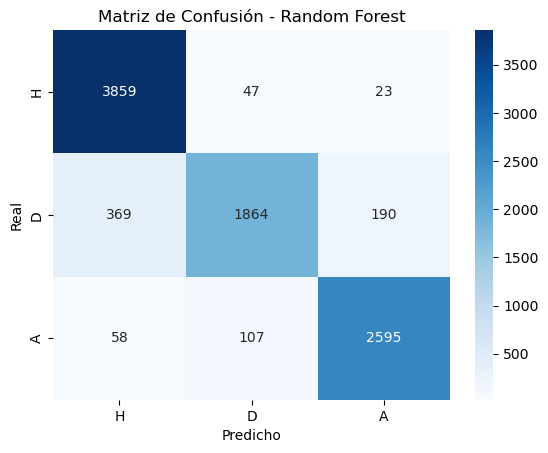

In [51]:
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1, max_depth=15)
rf.fit(X_train, y_train)

# Predicciones y matriz de confusión (para evaluar)
y_pred = rf.predict(X_test)
print(classification_report(y_test, y_pred))
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred, labels=['H', 'D', 'A'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['H', 'D', 'A'], yticklabels=['H', 'D', 'A'])
plt.title('Matriz de Confusión - Random Forest')
plt.xlabel('Predicho')
plt.ylabel('Real')
plt.show()

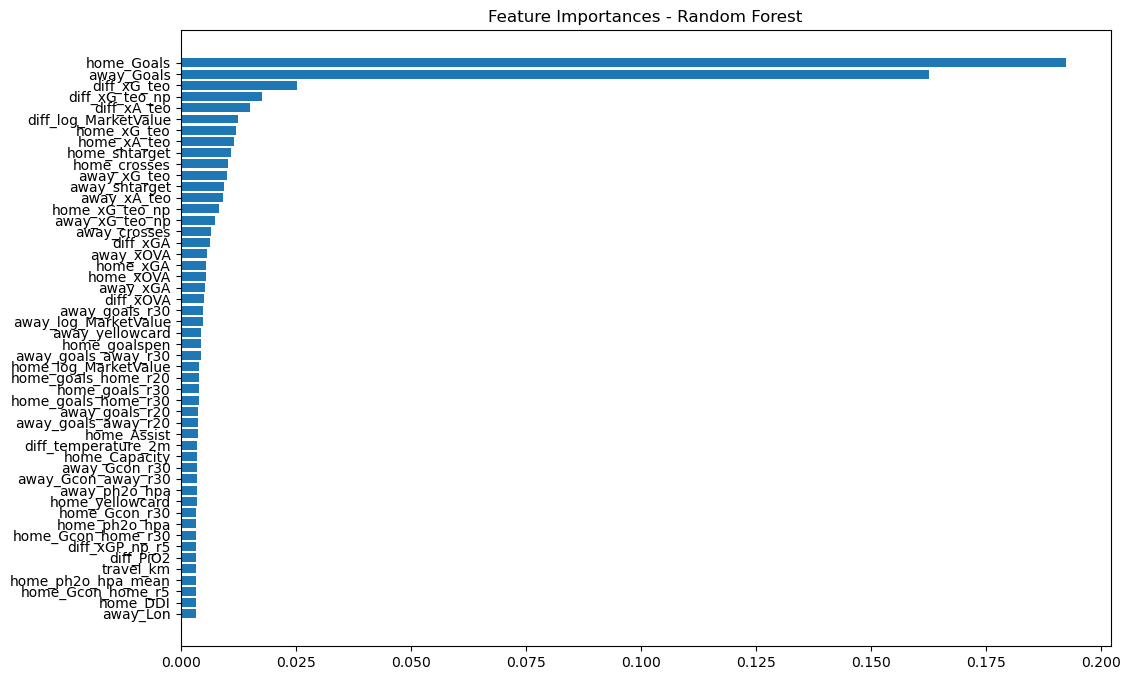

                            feature  importance
194                      home_Goals    0.192521
195                      away_Goals    0.162580
161                     diff_xG_teo    0.025216
162                  diff_xG_teo_np    0.017738
165                     diff_xA_teo    0.015141
190            diff_log_MarketValue    0.012576
15                      home_xG_teo    0.012074
19                      home_xA_teo    0.011611
3                     home_shtarget    0.011030
9                      home_crosses    0.010250
83                      away_xG_teo    0.010055
49                    away_shtarget    0.009442
87                      away_xA_teo    0.009157
16                   home_xG_teo_np    0.008273
84                   away_xG_teo_np    0.007568
55                     away_crosses    0.006652
167                        diff_xGA    0.006463
142                       away_xOVA    0.005700
20                         home_xGA    0.005543
141                       home_xOVA    0

In [52]:
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

# Mostrar top 30
plt.figure(figsize=(12, 8))
plt.title('Feature Importances - Random Forest')
plt.barh(range(50), importances[indices[:50]], align='center')
plt.yticks(range(50), [feature_cols[i] for i in indices[:50]])
plt.gca().invert_yaxis()
plt.show()

# Guardar en DataFrame
feat_imp = pd.DataFrame({'feature': feature_cols, 'importance': importances}).sort_values('importance', ascending=False)
print(feat_imp.head(60))

In [53]:
# Build a feature-only DataFrame using _r5, diff_*, macro, and selected static fields
if "df" not in locals():
    df = matches_final_copy.copy()

# Exclude specific columns explicitly
# exclude_cols = {"home_Assist", "home_OccRat", "home_Capacity"}
exclude_cols = {}

# MarketValue (and its logs/diffs) should be excluded entirely
marketvalue_keys = ["log_MarketValue", "diff_log_MarketValue"]

# Static / allowed non-rolling, non-diff fields
macro_bases = ["Inflation", "IED", "Population", "Gini", "log_PIB", "log_GastoPublico", "log_Deuda"]
macro_cols = [c for c in df.columns if any(b in c for b in macro_bases)]
static_cols = [c for c in df.columns if c in {"travel_km", "diff_Height", "home_Assist", "home_OccRat"}]

# Rolling and diff features
rolling_cols = [c for c in df.columns if c.endswith("_r5")]
diff_cols = [c for c in df.columns if c.startswith("diff_")]

selected_cols = sorted(set(rolling_cols + diff_cols + macro_cols + static_cols))
selected_cols = [c for c in selected_cols if c not in exclude_cols]
selected_cols = [c for c in selected_cols if not any(k in c for k in marketvalue_keys)]
selected_cols = [c for c in selected_cols if not ("x" in c and not c.endswith("_r5"))]
selected_cols = [c for c in selected_cols if np.issubdtype(df[c].dtype, np.number)]

df_filtered = df[selected_cols].copy()
print("Selected columns:", len(selected_cols))
print(selected_cols[:80])
print("df_filtered shape:", df_filtered.shape)

Selected columns: 84
['away_DDI_r5', 'away_Eff_xG_r5', 'away_Gcon_away_r5', 'away_Gcon_np_r5', 'away_Gcon_r5', 'away_Gini', 'away_IED', 'away_Inflation', 'away_Population', 'away_TDA_r5', 'away_attpen_r5', 'away_goals_away_r5', 'away_goals_r5', 'away_goalspen_r5', 'away_log_Deuda', 'away_log_GastoPublico', 'away_log_PIB', 'away_shtarget_r5', 'away_xA_teo_r5', 'away_xGA_r5', 'away_xGP_np_r5', 'away_xGP_r5', 'away_xG_teo_np_r5', 'away_xG_teo_r5', 'away_xOVA_r5', 'diff_DDI', 'diff_DDI_r5', 'diff_Deuda', 'diff_Eff_xG_r5', 'diff_Foreign', 'diff_GastoPublico', 'diff_Gcon_np_r5', 'diff_Gcon_r5', 'diff_Gini', 'diff_Height', 'diff_IED', 'diff_Inflation', 'diff_MarketValue', 'diff_NetSpending', 'diff_PIB', 'diff_PiO2', 'diff_TDA', 'diff_TDA_r5', 'diff_log_Deuda', 'diff_log_GastoPublico', 'diff_log_PIB', 'diff_relative_humidity_2m', 'diff_surface_pressure', 'diff_temperature_2m', 'diff_xA_teo_r5', 'diff_xGA_r5', 'diff_xGP_np_r5', 'diff_xGP_r5', 'diff_xG_teo_np_r5', 'diff_xG_teo_r5', 'diff_xOVA_r5

Train size: 29044, Test size: 9112
              precision    recall  f1-score   support

           A       0.48      0.38      0.43      2760
           D       0.35      0.03      0.05      2423
           H       0.49      0.84      0.62      3929

    accuracy                           0.49      9112
   macro avg       0.44      0.42      0.37      9112
weighted avg       0.45      0.49      0.41      9112

Accuracy: 0.4879


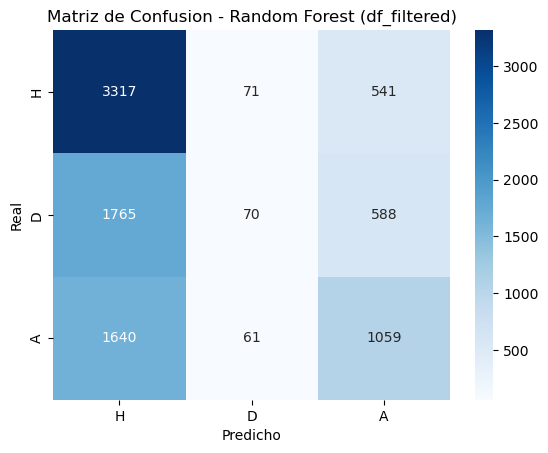

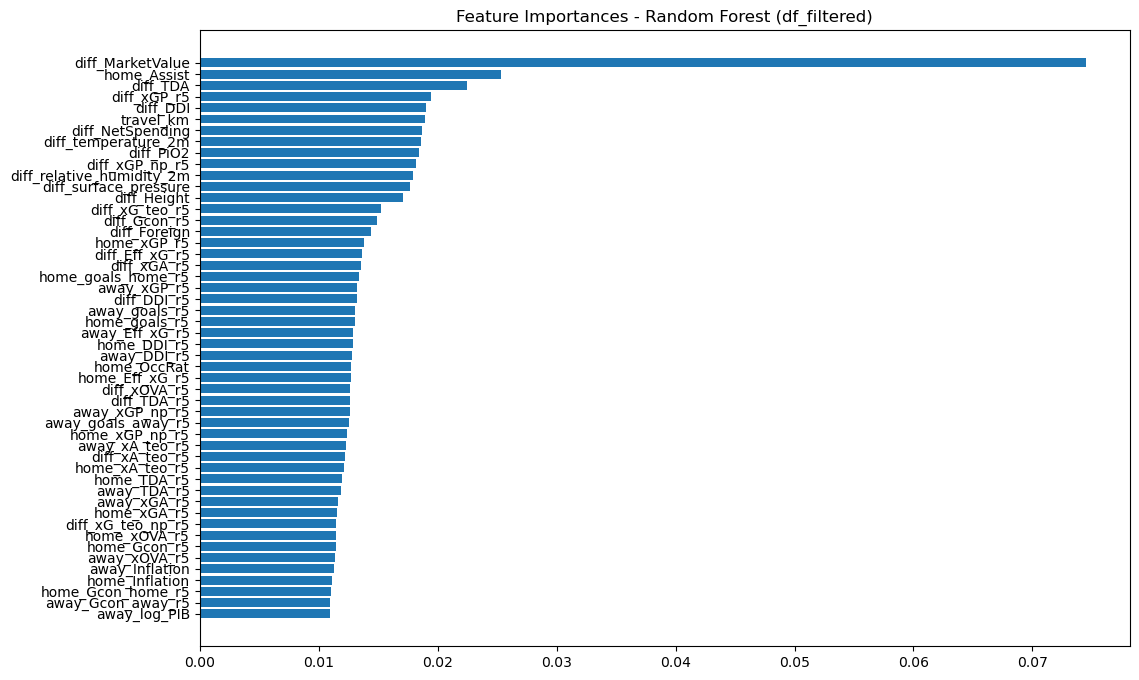

                      feature  importance
37           diff_MarketValue    0.074470
56                home_Assist    0.025316
41                   diff_TDA    0.022446
52                diff_xGP_r5    0.019398
25                   diff_DDI    0.019039
83                  travel_km    0.018895
38           diff_NetSpending    0.018647
48        diff_temperature_2m    0.018628
40                  diff_PiO2    0.018412
51             diff_xGP_np_r5    0.018155
46  diff_relative_humidity_2m    0.017955
47      diff_surface_pressure    0.017690
34                diff_Height    0.017050
54             diff_xG_teo_r5    0.015260
32               diff_Gcon_r5    0.014932
29               diff_Foreign    0.014376
79                home_xGP_r5    0.013808
28             diff_Eff_xG_r5    0.013665
50                diff_xGA_r5    0.013573
69         home_goals_home_r5    0.013402
21                away_xGP_r5    0.013223
26                diff_DDI_r5    0.013194
12              away_goals_r5    0

In [54]:
# Train/test split, RandomForest, and feature importances using df_filtered
if "df" not in locals():
    df = matches_final_copy.copy()

def get_result(row):
    if row["home_goals"] > row["away_goals"]:
        return "H"
    if row["home_goals"] == row["away_goals"]:
        return "D"
    return "A"

df_model = df_filtered.copy()
df_model["target"] = df.apply(get_result, axis=1)
df_model["year_from_id"] = df.get("year_from_id")
df_model["match_date_from_id"] = df.get("match_date_from_id")

df_model = df_model.sort_values("match_date_from_id")
train_df = df_model[df_model["year_from_id"] <= 2023]
test_df = df_model[df_model["year_from_id"] >= 2024]

X_train = train_df.drop(columns=["target", "year_from_id", "match_date_from_id"], errors="ignore")
y_train = train_df["target"]
X_test = test_df.drop(columns=["target", "year_from_id", "match_date_from_id"], errors="ignore")
y_test = test_df["target"]

print(f"Train size: {len(X_train)}, Test size: {len(X_test)}")

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1, max_depth=15)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
print(classification_report(y_test, y_pred))
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

cm = confusion_matrix(y_test, y_pred, labels=["H", "D", "A"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["H", "D", "A"], yticklabels=["H", "D", "A"])
plt.title("Matriz de Confusion - Random Forest (df_filtered)")
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.show()

importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 8))
plt.title("Feature Importances - Random Forest (df_filtered)")
plt.barh(range(50), importances[indices[:50]], align="center")
plt.yticks(range(50), [X_train.columns[i] for i in indices[:50]])
plt.gca().invert_yaxis()
plt.show()

feat_imp_filtered = pd.DataFrame({"feature": X_train.columns, "importance": importances}).sort_values("importance", ascending=False)
print(feat_imp_filtered.head(60))

In [55]:
print(feat_imp_filtered.head(80))

              feature  importance
37   diff_MarketValue    0.074470
56        home_Assist    0.025316
41           diff_TDA    0.022446
52        diff_xGP_r5    0.019398
25           diff_DDI    0.019039
..                ...         ...
30  diff_GastoPublico    0.001259
27         diff_Deuda    0.001244
39           diff_PIB    0.001243
36     diff_Inflation    0.001072
43     diff_log_Deuda    0.001029

[80 rows x 2 columns]


In [56]:
# Prepare data, features, split, and scaler for Glicko-2 advantage model
import numpy as np
from sklearn.preprocessing import StandardScaler
import joblib

if "df" not in locals():
    df = matches_final_copy.copy()

# Ensure diff_Foreign exists
if "diff_Foreign" not in df.columns:
    if "home_Foreign" in df.columns and "away_Foreign" in df.columns:
        df["diff_Foreign"] = pd.to_numeric(df["home_Foreign"], errors="coerce") - pd.to_numeric(df["away_Foreign"], errors="coerce")
    else:
        raise KeyError("Missing home_Foreign or away_Foreign to build diff_Foreign")

# Ensure year_from_id exists
if "year_from_id" not in df.columns:
    if "match_id_new" in df.columns:
        mid = df["match_id_new"].astype(str)
        df["year_from_id"] = pd.to_numeric(mid.str.slice(0, 4), errors="coerce")
    else:
        raise KeyError("Missing year_from_id or match_id_new for split")

# Build outcome label
def outcome_label(row):
    if row["home_goals"] > row["away_goals"]:
        return "H"
    if row["home_goals"] == row["away_goals"]:
        return "D"
    return "A"

df["outcome"] = df.apply(outcome_label, axis=1)

feature_cols = [
    "diff_MarketValue",
    "travel_km",
    "diff_NetSpending",
    "diff_temperature_2m",
    "diff_PiO2",
    "diff_xG_teo_r5",
    "diff_xA_teo_r5",
    "diff_DDI_r5",
    "home_Assist",
    "diff_Foreign",
]

missing_features = [c for c in feature_cols if c not in df.columns]
if missing_features:
    raise KeyError(f"Missing feature columns: {missing_features}")

# Train/test split
train_df = df[(df["year_from_id"] >= 2017) & (df["year_from_id"] <= 2023)].copy()
test_df = df[(df["year_from_id"] >= 2024) & (df["year_from_id"] <= 2025)].copy()

# Team-based fallback imputation for rolling and attendance-style columns

def fit_team_mean(frame, value_col, team_col):
    numeric_values = pd.to_numeric(frame[value_col], errors="coerce")
    temp = frame[[team_col]].copy()
    temp["_value"] = numeric_values
    team_means = temp.groupby(team_col)["_value"].mean()
    global_mean = numeric_values.mean()
    return team_means, global_mean


def apply_team_mean(frame, value_col, team_col, team_means, global_mean):
    frame[value_col] = pd.to_numeric(frame[value_col], errors="coerce")
    frame[value_col] = frame[value_col].fillna(frame[team_col].map(team_means)).fillna(global_mean)


# 1) Fill side rolling columns by team means
side_r5_cols = [c for c in df.columns if c.endswith("_r5") and (c.startswith("home_") or c.startswith("away_"))]
for col in side_r5_cols:
    team_col = "home_team" if col.startswith("home_") else "away_team"
    if team_col in train_df.columns:
        team_means, global_mean = fit_team_mean(train_df, col, team_col)
        apply_team_mean(train_df, col, team_col, team_means, global_mean)
        apply_team_mean(test_df, col, team_col, team_means, global_mean)

# 2) Rebuild diff rolling columns from the filled side rolling columns when possible
diff_r5_pairs = {
    "diff_xG_teo_r5": ("home_xG_teo_r5", "away_xG_teo_r5"),
    "diff_xA_teo_r5": ("home_xA_teo_r5", "away_xA_teo_r5"),
    "diff_DDI_r5": ("home_DDI_r5", "away_DDI_r5"),
}
for diff_col, (home_col, away_col) in diff_r5_pairs.items():
    if home_col in train_df.columns and away_col in train_df.columns:
        train_df[diff_col] = pd.to_numeric(train_df[home_col], errors="coerce") - pd.to_numeric(train_df[away_col], errors="coerce")
        test_df[diff_col] = pd.to_numeric(test_df[home_col], errors="coerce") - pd.to_numeric(test_df[away_col], errors="coerce")
    if diff_col in train_df.columns:
        train_values = pd.to_numeric(train_df[diff_col], errors="coerce")
        diff_global_mean = train_values.mean()
        train_df[diff_col] = train_values.fillna(diff_global_mean)
        test_df[diff_col] = pd.to_numeric(test_df[diff_col], errors="coerce").fillna(diff_global_mean)

# 3) Fill Assist and OccRat by team average, with global fallback only if a team has no history
for col in ["home_Assist", "home_OccRat", "away_OccRat"]:
    if col in train_df.columns:
        team_col = "home_team" if col.startswith("home_") else "away_team"
        if team_col in train_df.columns:
            team_means, global_mean = fit_team_mean(train_df, col, team_col)
            apply_team_mean(train_df, col, team_col, team_means, global_mean)
            apply_team_mean(test_df, col, team_col, team_means, global_mean)

X_train = train_df[feature_cols].apply(pd.to_numeric, errors="coerce")
X_test = test_df[feature_cols].apply(pd.to_numeric, errors="coerce")
y_train = train_df["outcome"].values
y_test = test_df["outcome"].values

# Final safety net for any remaining missing values
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print("df shape:", df.shape)
print("Valores únicos de year_from_id:", sorted(df['year_from_id'].dropna().unique()))
print("Cantidad de filas con año entre 2017 y 2023:", df[(df["year_from_id"] >= 2017) & (df["year_from_id"] <= 2023)].shape[0])
print("Cantidad de filas con año entre 2024 y 2025:", df[(df["year_from_id"] >= 2024) & (df["year_from_id"] <= 2025)].shape[0])

# Fit scaler on train only
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

joblib.dump({"scaler": scaler, "features": feature_cols, "medians": train_medians.to_dict()}, "g2av1416_scaler.pkl")
print("Scaler saved to g2av1416_scaler.pkl")
print("Train size:", X_train_std.shape, "Test size:", X_test_std.shape)

C:\Users\ruben\AppData\Local\Temp\ipykernel_10748\1239999060.py:32: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["outcome"] = df.apply(outcome_label, axis=1)


df shape: (38156, 228)
Valores únicos de year_from_id: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Cantidad de filas con año entre 2017 y 2023: 29044
Cantidad de filas con año entre 2024 y 2025: 9112
Scaler saved to g2av1416_scaler.pkl
Train size: (29044, 10) Test size: (9112, 10)


In [57]:
# Optimize betas with Glicko-2 log loss and evaluate vs baseline
from math import log, pi
from scipy.optimize import minimize

# Glicko-2 constants
BASE_MU = 1500.0
BASE_RD = 200.0
DRAW_CORRECTION = -0.2
Q = log(10) / 400
G_CONSTANT = 1.5 / (pi ** 2)

# Optional per-match draw probability (fallback to constant)
if "skellam_draw_probability" in df.columns:
    draw_train = train_df["skellam_draw_probability"].fillna(0.33).to_numpy()
    draw_test = test_df["skellam_draw_probability"].fillna(0.33).to_numpy()
else:
    draw_train = np.full(len(train_df), 0.33)
    draw_test = np.full(len(test_df), 0.33)

# Ratings (fallback to constant if columns missing)
home_mu_col = "home_mu" if "home_mu" in df.columns else None
away_mu_col = "away_mu" if "away_mu" in df.columns else None
home_rd_col = "home_rd" if "home_rd" in df.columns else None
away_rd_col = "away_rd" if "away_rd" in df.columns else None

home_mu_train = train_df[home_mu_col].to_numpy() if home_mu_col else np.full(len(train_df), BASE_MU)
away_mu_train = train_df[away_mu_col].to_numpy() if away_mu_col else np.full(len(train_df), BASE_MU)
home_rd_train = train_df[home_rd_col].to_numpy() if home_rd_col else np.full(len(train_df), BASE_RD)
away_rd_train = train_df[away_rd_col].to_numpy() if away_rd_col else np.full(len(train_df), BASE_RD)
home_mu_test = test_df[home_mu_col].to_numpy() if home_mu_col else np.full(len(test_df), BASE_MU)
away_mu_test = test_df[away_mu_col].to_numpy() if away_mu_col else np.full(len(test_df), BASE_MU)
home_rd_test = test_df[home_rd_col].to_numpy() if home_rd_col else np.full(len(test_df), BASE_RD)
away_rd_test = test_df[away_rd_col].to_numpy() if away_rd_col else np.full(len(test_df), BASE_RD)

def glicko_probs(advantage, mu_home, mu_away, rd_home, rd_away, draw_prob):
    mu = ((mu_home + advantage - BASE_MU) * Q)
    mu_opp = ((mu_away - advantage - BASE_MU) * Q)
    phi = rd_home * Q
    phi_opp = rd_away * Q
    g = 1.0 / np.sqrt(1.0 + G_CONSTANT * (phi ** 2 + phi_opp ** 2))
    delta_mu = g * (mu - mu_opp)
    delta_mu = np.clip(delta_mu, -50.0, 50.0)
    draw_coef = 1.0 + np.exp(DRAW_CORRECTION + draw_prob)
    exp_delta = np.exp(delta_mu)
    p_home = 1.0 / (1.0 + draw_coef / exp_delta)
    p_away = 1.0 / (1.0 + draw_coef * exp_delta)
    p_draw = 1.0 - p_home - p_away
    eps = 1e-12
    p_home = np.clip(p_home, eps, 1.0 - eps)
    p_away = np.clip(p_away, eps, 1.0 - eps)
    p_draw = np.clip(p_draw, eps, 1.0 - eps)
    return p_home, p_draw, p_away

def glicko_logloss(beta, X, outcomes, mu_home, mu_away, rd_home, rd_away, draw_prob):
    advantage = beta[0] + X.dot(beta[1:])
    p_home, p_draw, p_away = glicko_probs(advantage, mu_home, mu_away, rd_home, rd_away, draw_prob)
    loss = np.where(outcomes == "H", -np.log(p_home),
                    np.where(outcomes == "D", -np.log(p_draw), -np.log(p_away)))
    return float(np.mean(loss))

# Remove rows with any non-finite values
def filter_finite(X, outcomes, mu_home, mu_away, rd_home, rd_away, draw_prob):
    mask = np.isfinite(X).all(axis=1)
    mask &= np.isfinite(mu_home) & np.isfinite(mu_away)
    mask &= np.isfinite(rd_home) & np.isfinite(rd_away)
    mask &= np.isfinite(draw_prob)
    return X[mask], outcomes[mask], mu_home[mask], mu_away[mask], rd_home[mask], rd_away[mask], draw_prob[mask]

X_train_f, y_train_f, home_mu_train_f, away_mu_train_f, home_rd_train_f, away_rd_train_f, draw_train_f = filter_finite(
    X_train_std, y_train, home_mu_train, away_mu_train, home_rd_train, away_rd_train, draw_train
 )
X_test_f, y_test_f, home_mu_test_f, away_mu_test_f, home_rd_test_f, away_rd_test_f, draw_test_f = filter_finite(
    X_test_std, y_test, home_mu_test, away_mu_test, home_rd_test, away_rd_test, draw_test
 )

if len(y_train_f) == 0 or len(y_test_f) == 0:
    raise ValueError("No valid rows after filtering non-finite values. Check features and draw probabilities.")

# Fit full model
beta0 = np.zeros(X_train_f.shape[1] + 1)
result = minimize(
    glicko_logloss,
    beta0,
    args=(X_train_f, y_train_f, home_mu_train_f, away_mu_train_f, home_rd_train_f, away_rd_train_f, draw_train_f),
    method="L-BFGS-B",
    options={"maxiter": 500},
)

# Baseline: constant advantage only
def baseline_loss(h):
    beta = np.zeros(X_train_f.shape[1] + 1)
    beta[0] = h[0]
    return glicko_logloss(beta, X_train_f, y_train_f, home_mu_train_f, away_mu_train_f, home_rd_train_f, away_rd_train_f, draw_train_f)

baseline_result = minimize(baseline_loss, np.array([0.0]), method="L-BFGS-B")

beta_hat = result.x
beta_base = np.zeros_like(beta_hat)
beta_base[0] = baseline_result.x[0]

train_loss = glicko_logloss(beta_hat, X_train_f, y_train_f, home_mu_train_f, away_mu_train_f, home_rd_train_f, away_rd_train_f, draw_train_f)
test_loss = glicko_logloss(beta_hat, X_test_f, y_test_f, home_mu_test_f, away_mu_test_f, home_rd_test_f, away_rd_test_f, draw_test_f)
base_train_loss = glicko_logloss(beta_base, X_train_f, y_train_f, home_mu_train_f, away_mu_train_f, home_rd_train_f, away_rd_train_f, draw_train_f)
base_test_loss = glicko_logloss(beta_base, X_test_f, y_test_f, home_mu_test_f, away_mu_test_f, home_rd_test_f, away_rd_test_f, draw_test_f)

print("Optimization success:", result.success, result.message)
print("Train log loss (model):", train_loss)
print("Test log loss (model):", test_loss)
print("Train log loss (baseline):", base_train_loss)
print("Test log loss (baseline):", base_test_loss)

# Save betas
joblib.dump({"beta": beta_hat, "features": feature_cols}, "g2av1416_betas.pkl")
print("Betas saved to g2av1416_betas.pkl")

Optimization success: True CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Train log loss (model): 1.0517520429345117
Test log loss (model): 1.0503751678820445
Train log loss (baseline): 1.0957598779059976
Test log loss (baseline): 1.095399299958038
Betas saved to g2av1416_betas.pkl


In [58]:
# Cierre: exportar datasets finales a CSV (requiere que df o matches_final_copy ya existan)
from pathlib import Path

if "matches_final_copy" in locals():
    export_df = matches_final_copy.copy()
elif "df" in locals():
    export_df = df.copy()
else:
    raise NameError("No existe matches_final_copy ni df en memoria. Ejecuta las celdas previas.")

# Drop rows by match_id_new if home/away team_id is in the banned list
#ids_drop_match = [
    #'02f8d026', '054efa67', '06d05f19', '0e72edf2', '206d90db', '20f5bd86', '28d9b675',
    #'331a33a7', '39abd503', '3d377a8c', '421387cf', '4573a712', '4eaa11d7', '54da9a57',
    #'658bf2de', '7213da33', '756c9acb', '80595417', '8b4cbfb9', '8ff9e3b3', '922493f3',
    #'99f258c2', '9f18ced7', 'a3d88bd8', 'adba8c92', 'be35aa4d', 'c1cf4fdc', 'cc6ecd46',
    #'d42d8b2f', 'd48ad4ff', 'd53c0b06', 'd59e6510', 'dc56fe14', 'e0652b02', 'e2befd26',
    #'e83b563b', 'eab4234c', 'eb8e3e81', 'ecd11ca2'
#]

ids_drop_match = [
    '02f8d026',   # Roma fem
    '06d05f19',   # Internazionale fem
    '20f5bd86',   # San Marino fem
    '28d9b675',   # Paris Fem
    '331a33a7',   # Tavagnacco fem
    '39abd503',   # Glasgow fem
    '3d377a8c',   # St Polten fem
    '54da9a57',   # Milan Fem
    '2998cfbf',   # Genoa Fem
    '19db4c32',   # Lazio fem
    '756c9acb',   # Como Women
    '80595417',   # PSGFem
    '9f18ced7',   # Pomigliano
    'adba8c92',   # Orobica
    'be35aa4d',   # Pink Bari
    'c1cf4fdc',   # Sparta Fem
    'cc6ecd46',   # Chievo fem
    'd42d8b2f',   # Fiorentia San Gimignano fem
    'c99ff6e5',   # Fiorentina fem
    '828ce826',   # Napoli Fem
    'd59e6510',   # AGSMVerona
    'e83b563b',   # Servette fem
    'eb8e3e81',   # Ternana
    'b72bc283',   # Empoli Fem
    '613577b8',   # Juventus Fem 
    'a8e83f23',   # Sassuolo Fem 
    'f7d05cb5',   # Parma Fem 
    'd35ed67b',   # Hellas Verona fem
    '58e367c3',   # Sampdoria fem
    'a8e83f23',   # Sassuolo fem
    "80595417",   # PSG Fem
    "81541844",   # Bardejov fem
    "005a8517",   # Breidaglik fem
    "0341a929",   # NSA Sofia fem
    "0417d25a",   # Rangers
    "04a17aa1",   # Czarni fem
    "07787bf7",   # Sturm Graz fem
    "092980d3",   # Apollon limassol fem
    "0a6448a7",   # Sileks fem
    "0b92bbb1",   # Myjava fem
    "0bbd83f6",   # Manchester United fem
    "0d19b2b7",   # Osijek fem
    "0d683475",   # Sporting Lisboa fem
    "0f31d5f3",   # Swansea fem
    "0f4738a8",   # Levante fem
    "10207b7a",   # Hammarby fem
    "10c6ba21",   # Universitaea Olimpija fem
    "15f49df1",   # Barcelona fem
    "167233d5",   # Zhytlobuk 2 fem
    "1aec6388",   # Celtic fem
    "1b3af73b",   # PAOK fem
    "1c934f04",   # Lanchkhuti fem
    "1da16b8f",   # Aland United fem
    "1e209cf8",   # Slovan bratislava fem
    "1e615f2b",   # Zhytlobud 1 fem
    "215d411b",   # ALG fem
    "231a3620",   # Anderlecht fem
    "236e3619",   # Red Star fem
    "23b52962",   # Glentoran fem
    "23b8ffcd",   # Konak Boluspor fem
    "261c5544",   # Standard Lieja fem
    "264d7848",   # Benfica fem
    "26a84b38",   # Anenii fem
    "28d9b675",   # Paris FC fem
    "2972399d",   # Linkopig fem
    "29ee35e0",   # Gintra Universitaea fem
    "2aa6d10a",   # Valur fem
    "2c76cc8f",   # Lokomotiv Moscow fem
    "33fce591",   # Lugano fem
    "37b835b5",   # CSKA Moscow fem
    "3997bac6",   # Dynamo Minsk fem
    "39abd503",   # Glasgow City fem
    "3c94e2df",   # Hjorring fem
    "3d377a8c",   # St Pollten fem
    "411b1108",   # Arsenal fem
    "424e506f",   # 1FC Viena fem
    "4549ef76",   # Sasa fem
    "4573a712",   # Ajax fem
    "476d5fea",   # Riga fem
    "4b23c2af",   # Brondby fem
    "4f09a762",   # Neftci fem
    "4f782ba7",   # Shelbourne fem
    "50fbb58d",   # Stjarnan fem
    "51ec22be",   # Bayern fem
    "52e4e8e8",   # Linfield fem
    "54582b93",   # Real Madrid tacon
    "571393d8",   # Alashkert fem
    "58ff3cd4",   # KI KLasvik fem
    "5a12b71d",   # Galatasaray fem
    "5ad3e6fc",   # Gornik fem
    "621928ce",   # Gieksa Katowice fem
    "646b9825",   # Martve fem
    "6962939c",   # Spartak Subotica fem
    "69dee2b0",   # Girondis bordeaux fem
    "6d12ffd1",   # KA fem
    "6e3e89b0",   # Cardiff city fem
    "6f6ee141",   # Kazygurt fem
    "7660add0",   # Samegrelo fem
    "768fae36",   # FC Minsk fem
    "7a1000e8",   # Norok fem
    "7ae0d809",   # Honka fem
    "7b538d76",   # Parnu fem
    "7ba81fac",   # Birkirkara fem
    "7f2012ad",   # Olympique Lyon fem
    "814f26cd",   # SFK 2000 fem
    "8266975e",   # Zurich fem
    "82a7cabd",   # Zvezda Perm fem
    "82b25b91",   # Cliftonville fem
    "8318c196",   # Olimpija fem
    "856cc63a",   # Sporting Braga fem
    "874efae9",   # Mitrovica fem
    "87705c62",   # Hoffenheim fem
    "889b0f75",   # Kiryat Gat fem
    "89f584e1",   # Hacken BK fem
    "8b4cbfb9",   # Slavia Praga fem
    "8cf14206",   # Rosenborg BK fem
    "8e9d9e5f",   # Tomiriz Turan fem
    "8ea63662",   # UKSSMS Lodz fem
    "92a6e903",   # Avaldsnes fem
    "931cb21e",   # Ramat HaSharon fem
    "9522e7b4",   # PSV Fem
    "969118cb",   # Bettembourg fem
    "97b7c0e8",   # Eintracht Frankfurt fem
    "9a505508",   # Tbilisi Nike fem
    "9bb79f59",   # Ljuboten fem
    "9ce68f8a",   # Manchester City Women
    "9d12423d",   # Hajvalia fem
    "9ec14616",   # Kristianstad fem
    "9f44dae3",   # Women Chertanovo
    "a1393014",   # Wolfsburg fem
    "a2c4c17a",   # Rosengard fem
    "a5e92def",   # Pitea fem
    "a6a4e67d",   # Chelsea women
    "a873ed48",   # Barcelona fem Cyprus
    "a88780ed",   # Kolos Kovalika fem
    "ae156985",   # KR Reyjkavik fem
    "ae395858",   # Nordsjaelland fem
    "aee32dcc",   # Flora Tallinn fem 
    "b00041f6",   # HB Koge fem
    "b16eac73",   # Pearmount united fem
    "b56c2667",   # Atletico Madrid fem
    "b6199a89",   # Besiktas fem
    "b6f8790a",   # Farul Constanza fem
    "b80262ea",   # Pormuje fem
    "bd5e1428",   # KI Klasvik fem
    "beda3b78",   # Isatov fem
    "c07cf5b5",   # Hibernian fem
    "c1c51bdf",   # Valerenga fem
    "c1cf4fdc",   # Sparta Praga fem
    "c21f25d3",   # Real Sociedad fem
    "c306c432",   # HJK fem
    "c6bd5ba1",   # Com Hajvalia fem
    "c7efe450",   # Lokomotiv Stara Zagora fem
    "c843f52a",   # Fomget fem
    "ca6492f2",   # Kvinner fem
    "d2e7fc56",   # Pyunik Yerevan fem
    "d6a485e1",   # Virtus fem
    "d8deaf72",   # Villaznia fem
    "d9a75109",   # KuPS fem
    "da27edc2",   # ZNK Splir fem
    "df57dd52",   # Pogon Szczecin fem
    "dfe62afe",   # Racing Union fem
    "e04b1b89",   # Twente fem
    "e065a5a4",   # Breznica fem
    "e83b563b",   # Servette fem
    "ea339fbc",   # Brann fem
    "ef289882",   # 1FC Slovacko fem
    "f0dbdec6",   # Rigas FSK fem
    "f1e85b1e",   # Kukesi fem
    "f1f7051d",   # Hayasa fem
    "f30d7206",   # Vantaa fem
    "f7dfd35b",   # Kryvas fem
    "f820669e",   # Okzhetpes fem
    "f8adab89",   # Medyk fem
    "fd1a6b48",   # MTK Hungaria
    "fd573be7",   # Ferencvaros fem
    "feb66a71",   # Ryazan fem
    "411b1108",   # Arsenal ladies
    "b56c2667",   # Atletico madrid fem
    "15f49df1",   # Barcelona fem
    "51ec22be",   # Bayern fem
    "69dee2b0",   # Bordeaux fem
    "a6a4e67d",   # Chelsea fem
    "97b7c0e8",   # Eintracht Frankfurt fem
    "87705c62",   # Hoffenheim fem
    "0f4738a8",   # Levante fem
    "7f2012ad",   # Olympique Lyonnes
    "9ce68f8a",   # Manchester City women
    "54582b93",   # Real Madrid tacon
    "c21f25d3",   # Real Sociedad fem
    "a1393014",   # Wolfsburg fem
]

#removed_extra = 0
#if "match_id_new" in export_df.columns:
    #pattern = "|".join(ids_drop_match)
    #mask_match = export_df["match_id_new"].astype(str).str.contains(pattern, na=False)
    #removed_extra = int(mask_match.sum())
    #export_df = export_df[~mask_match].copy()
    #print("Filas eliminadas por match_id_new:", removed_extra)

# Filtro robusto por equipo femenino (usando IDs)
mask_home = export_df["home_team_id"].isin(ids_drop_match)
mask_away = export_df["away_team_id"].isin(ids_drop_match)
mask_drop = mask_home | mask_away

removed_extra = int(mask_drop.sum())
export_df = export_df[~mask_drop].copy()
print("Filas eliminadas por equipo femenino (team_id):", removed_extra)

# Garantizar home_OccRat en todos los exports
if "home_OccRat" not in export_df.columns and "home_Assist" in export_df.columns and "home_Capacity" in export_df.columns:
    export_df["home_OccRat"] = pd.to_numeric(export_df["home_Assist"], errors="coerce") / pd.to_numeric(export_df["home_Capacity"], errors="coerce")

# Garantizar columnas de goles explicitas
if "home_Goals" not in export_df.columns and "home_goals" in export_df.columns:
    export_df["home_Goals"] = export_df["home_goals"]
if "away_Goals" not in export_df.columns and "away_goals" in export_df.columns:
    export_df["away_Goals"] = export_df["away_goals"]

metadata_cols = [
    "match_id_new",
    "match_date_from_id",
    "Competition",
    "year_from_id",
    "month_from_id",
    "home_team_id",
    "away_team_id",
    "home_team",
    "away_team",
]

goal_cols = ["home_goals", "away_goals"]
feature_cols_model = [
    "diff_MarketValue",
    "travel_km",
    "diff_NetSpending",
    "diff_temperature_2m",
    "diff_PiO2",
    "diff_xG_teo_r5",
    "diff_xA_teo_r5",
    "diff_DDI_r5",
    "home_Assist",
    "diff_Foreign",
    "home_OccRat",
    "home_Goals",
    "away_Goals",
]

feature_cols_lite = [
    c for c in feature_cols_model
    if c not in {"diff_xG_teo_r5", "diff_xA_teo_r5", "diff_DDI_r5"}
]

# Dataset 1: completo
complete_df = export_df.copy()

# Dataset 2: modelo completo (metadata + goals + features de celda 52)
full_model_cols = [c for c in metadata_cols + goal_cols + feature_cols_model if c in export_df.columns]
full_model_df = export_df[full_model_cols].copy()

# Dataset 3: modelo lite (sin las 3 features deportivas rolling)
lite_model_cols = [c for c in metadata_cols + goal_cols + feature_cols_lite if c in export_df.columns]
lite_model_df = export_df[lite_model_cols].copy()

output_dir = Path(r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos")
complete_path = output_dir / "matches_final_complete.csv"
full_model_path = output_dir / "matches_final_model_full.csv"
lite_model_path = output_dir / "matches_final_model_lite.csv"

complete_df.to_csv(complete_path, index=False, encoding="utf-8-sig")
full_model_df.to_csv(full_model_path, index=False, encoding="utf-8-sig")
lite_model_df.to_csv(lite_model_path, index=False, encoding="utf-8-sig")

print("Exportado dataset completo:", complete_path)
print("Shape:", complete_df.shape)
print("Exportado dataset modelo completo:", full_model_path)
print("Shape:", full_model_df.shape)
print("Exportado dataset modelo lite:", lite_model_path)
print("Shape:", lite_model_df.shape)
print("Columnas modelo completo:", list(full_model_df.columns))
print("Columnas modelo lite:", list(lite_model_df.columns))

Filas eliminadas por equipo femenino (team_id): 0
Exportado dataset completo: C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_complete.csv
Shape: (38156, 226)
Exportado dataset modelo completo: C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full.csv
Shape: (38156, 24)
Exportado dataset modelo lite: C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_lite.csv
Shape: (38156, 21)
Columnas modelo completo: ['match_id_new', 'match_date_from_id', 'Competition', 'year_from_id', 'month_from_id', 'home_team_id', 'away_team_id', 'home_team', 'away_team', 'home_goals', 'away_goals', 'diff_MarketValue', 'travel_km', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2', 'diff_xG_teo_r5', 'diff_xA_teo_r5', 'diff_DDI_r5', 'home_Assist', 'diff_Foreign', 'home_OccRat', 'home_Goals', 'away_Goals']
Columnas modelo lite: ['match_id_new', 'match_date_from_id', 'Competition', 'year_from_id', 'month_from_id', 'home

In [59]:
# Show final dataframe details before export
if "export_df" not in locals():
    export_df = matches_final_copy.copy() if "matches_final_copy" in locals() else df.copy()

print("Final df shape:", export_df.shape)
print("Columns:")
print(list(export_df.columns))
print("Head:")
print(export_df.head(10))

Final df shape: (38156, 226)
Columns:
['match_date_from_id', 'match_id_new', 'Competition', 'home_team_id', 'home_team', 'home_goals', 'home_assists', 'home_goalspen', 'home_attpen', 'home_shots', 'home_shtarget', 'home_yellowcard', 'home_redcard', 'home_fouls', 'home_foulsd', 'home_offside', 'home_crosses', 'home_tacklesw', 'home_interceptions', 'home_owngoals', 'home_penkickgen', 'home_penkickcon', 'home_xG_teo', 'home_xG_teo_np', 'home_TDA', 'home_DDI', 'home_xA_teo', 'home_xGA', 'home_temperature_2m_mean', 'home_relative_humidity_2m_mean', 'home_surface_pressure_mean', 'home_ph2o_hpa_mean', 'home_elevation_mean', 'home_PiO2_mean', 'home_temperature_2m', 'home_relative_humidity_2m', 'home_surface_pressure', 'home_ph2o_hpa', 'home_elevation', 'home_PiO2', 'home_Lat', 'home_Lon', 'home_Capacity', 'home_Height', 'home_Assist', 'home_Country', 'home_OccRat', 'home_Players', 'home_Foreign', 'home_MarketValue', 'home_Income', 'home_Expenses', 'home_PIB', 'home_Inflation', 'home_IED', 'hom

In [60]:
# Drop rows where home_Goals or away_Goals are missing
if "export_df" not in locals():
    export_df = matches_final_copy.copy() if "matches_final_copy" in locals() else df.copy()

# Ensure explicit goals columns exist for the check
if "home_Goals" not in export_df.columns and "home_goals" in export_df.columns:
    export_df["home_Goals"] = export_df["home_goals"]
if "away_Goals" not in export_df.columns and "away_goals" in export_df.columns:
    export_df["away_Goals"] = export_df["away_goals"]

missing_goals_mask = export_df["home_Goals"].isna() | export_df["away_Goals"].isna()
removed_rows = int(missing_goals_mask.sum())
export_df = export_df.loc[~missing_goals_mask].copy()

print("Rows dropped due to missing home_Goals or away_Goals:", removed_rows)
print("Remaining rows:", len(export_df))

Rows dropped due to missing home_Goals or away_Goals: 491
Remaining rows: 37665


In [61]:
# Missing by team/year/month for selected diff_* columns
if "export_df" not in locals():
    export_df = matches_final_copy.copy() if "matches_final_copy" in locals() else df.copy()

required_cols = [
    "diff_MarketValue",
    "diff_NetSpending",
    "diff_temperature_2m",
    "diff_PiO2",
    "home_team",
    "away_team",
    "match_id_new",
]
missing_required = [c for c in required_cols if c not in export_df.columns]
if missing_required:
    raise KeyError(f"Missing required columns: {missing_required}")

# Extract year/month from match_id_new (YYYYMMDD_hometeamid_awayteamid)
match_id_str = export_df["match_id_new"].astype(str)
date_part = match_id_str.str.split("_").str[0]
year_from_id = pd.to_numeric(date_part.str.slice(0, 4), errors="coerce")
month_from_id = pd.to_numeric(date_part.str.slice(4, 6), errors="coerce")

missing_mask = export_df[[
    "diff_MarketValue",
    "diff_NetSpending",
    "diff_temperature_2m",
    "diff_PiO2",
]].isna()

missing_rows = export_df.loc[missing_mask.any(axis=1), ["home_team", "away_team"]].copy()
missing_rows["year_from_id"] = year_from_id.loc[missing_rows.index]
missing_rows["month_from_id"] = month_from_id.loc[missing_rows.index]
missing_rows["diff_MarketValue"] = missing_mask.loc[missing_rows.index, "diff_MarketValue"]
missing_rows["diff_NetSpending"] = missing_mask.loc[missing_rows.index, "diff_NetSpending"]
missing_rows["diff_temperature_2m"] = missing_mask.loc[missing_rows.index, "diff_temperature_2m"]
missing_rows["diff_PiO2"] = missing_mask.loc[missing_rows.index, "diff_PiO2"]

missing_summary = (
    missing_rows.groupby(["home_team", "away_team", "year_from_id", "month_from_id"])[
        ["diff_MarketValue", "diff_NetSpending", "diff_temperature_2m", "diff_PiO2"]
    ]
    .sum()
    .reset_index()
    .sort_values(["home_team", "away_team", "year_from_id", "month_from_id"])
)

print("Missing counts by home/away team and year/month:")
print(missing_summary.head(200))

# Export missing_summary to CSV
output_dir = Path(r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos")
missing_summary_path = output_dir / "missing_diff_by_team_year_month.csv"
missing_summary.to_csv(missing_summary_path, index=False, encoding="utf-8-sig")
print("Saved:", missing_summary_path)

Missing counts by home/away team and year/month:
    home_team      away_team  year_from_id  month_from_id  diff_MarketValue  \
0         AEK     Levadiakos          2019              1                 1   
1         AEL     Levadiakos          2019              3                 1   
2         AEL      Panionios          2020              7                 1   
3         AEL         Xanthi          2020              7                 1   
4        Abha       AlAdalah          2020              2                 0   
..        ...            ...           ...            ...               ...   
195   AlWehda           Abha          2022              9                 0   
196   AlWehda           Abha          2023              9                 0   
197    Alaves          Celta          2019              2                 0   
198  Aldosivi  ArgentinosJrs          2025              9                 1   
199  Aldosivi       Belgrano          2025              8                 1   

  

In [62]:
# Fill missing diffs: MarketValue/NetSpending -> 0; Temperature/PiO2 -> from open_meteo datasets
if "export_df" not in locals():
    export_df = matches_final_copy.copy() if "matches_final_copy" in locals() else df.copy()

for col in ["diff_MarketValue", "diff_NetSpending"]:
    if col in export_df.columns:
        export_df[col] = pd.to_numeric(export_df[col], errors="coerce").fillna(0)

# Ensure year/month from match_id_new
match_id_str = export_df["match_id_new"].astype(str)
date_part = match_id_str.str.split("_").str[0]
export_df["year_from_id"] = pd.to_numeric(date_part.str.slice(0, 4), errors="coerce")
export_df["month_from_id"] = pd.to_numeric(date_part.str.slice(4, 6), errors="coerce")

# Prepare climate lookups
home_hist = open_meteo_historical[["Team", "year", "month", "temperature_2m", "PiO2"]].copy()
away_monthly = open_meteo_monthly[["Team", "month", "temperature_2m", "PiO2"]].copy()

home_hist = home_hist.rename(columns={
    "Team": "home_team",
    "year": "year_from_id",
    "month": "month_from_id",
    "temperature_2m": "home_temperature_2m_src",
    "PiO2": "home_PiO2_src",
})

away_monthly = away_monthly.rename(columns={
    "Team": "away_team",
    "month": "month_from_id",
    "temperature_2m": "away_temperature_2m_src",
    "PiO2": "away_PiO2_src",
})

# Only process rows missing either diff_temperature_2m or diff_PiO2
needs_climate = export_df[["diff_temperature_2m", "diff_PiO2"]].isna().any(axis=1)

if needs_climate.any():
    climate_df = export_df.loc[needs_climate, [
        "home_team",
        "away_team",
        "year_from_id",
        "month_from_id",
        "diff_temperature_2m",
        "diff_PiO2",
    ]].copy()
    climate_df["row_index"] = climate_df.index

    climate_df = climate_df.merge(
        home_hist,
        on=["home_team", "year_from_id", "month_from_id"],
        how="left",
    )
    climate_df = climate_df.merge(
        away_monthly,
        on=["away_team", "month_from_id"],
        how="left",
    )

    # Compute diffs with max(0, home - away)
    temp_diff = climate_df["home_temperature_2m_src"] - climate_df["away_temperature_2m_src"]
    pio2_diff = climate_df["home_PiO2_src"] - climate_df["away_PiO2_src"]

    climate_df["diff_temperature_2m"] = climate_df["diff_temperature_2m"].fillna(temp_diff.clip(lower=0))
    climate_df["diff_PiO2"] = climate_df["diff_PiO2"].fillna(pio2_diff.clip(lower=0))

    export_df.loc[climate_df["row_index"], "diff_temperature_2m"] = climate_df["diff_temperature_2m"].values
    export_df.loc[climate_df["row_index"], "diff_PiO2"] = climate_df["diff_PiO2"].values

    print("Filled climate diffs:", int(needs_climate.sum()))
else:
    print("No missing climate diffs to fill.")

# Keep matches_final_copy in sync if it exists
if "matches_final_copy" in locals():
    matches_final_copy["diff_MarketValue"] = export_df["diff_MarketValue"]
    matches_final_copy["diff_NetSpending"] = export_df["diff_NetSpending"]
    matches_final_copy["diff_temperature_2m"] = export_df["diff_temperature_2m"]
    matches_final_copy["diff_PiO2"] = export_df["diff_PiO2"]

Filled climate diffs: 1097


In [63]:
# Missing counts per column (excluding *_r5)
if "export_df" not in locals():
    export_df = matches_final_copy.copy() if "matches_final_copy" in locals() else df.copy()

non_r5_cols = [c for c in export_df.columns if not c.endswith("_r5")]
missing_counts = export_df[non_r5_cols].isna().sum().sort_values(ascending=False)

print("Missing counts per column (non-r5):")
print(missing_counts[missing_counts > 0])

Missing counts per column (non-r5):
home_penkickgen        32396
home_penkickcon        32396
away_penkickcon        32396
away_penkickgen        32396
home_OccRat            14952
                       ...  
home_Gcon_home_r30       203
diff_PiO2                174
diff_temperature_2m      174
away_owngoals             38
home_owngoals             38
Length: 154, dtype: int64


In [64]:
# Report missing values in feature_cols_model excluding r5 columns
if "export_df" not in locals():
    raise NameError("export_df no existe. Ejecuta la celda anterior de exportacion.")
if "feature_cols_model" not in locals():
    raise NameError("feature_cols_model no existe. Ejecuta la celda anterior de exportacion.")

# Fill remaining small-sample diffs with 0
for col in ["diff_temperature_2m", "diff_PiO2", "diff_Foreign"]:
    if col in export_df.columns:
        export_df[col] = pd.to_numeric(export_df[col], errors="coerce").fillna(0)

missing_check_cols = [c for c in feature_cols_model if not c.endswith("r5") and c in export_df.columns]
missing_mask = export_df[missing_check_cols].isna()
missing_counts = missing_mask.sum().sort_values(ascending=False)

print("Total filas:", len(export_df))
print("Columnas revisadas:", len(missing_check_cols))
print("Missing por columna (top 20):")
print(missing_counts.head(20))

rows_with_missing = missing_mask.any(axis=1)
print("Filas con al menos un missing:", int(rows_with_missing.sum()))

missing_rows = export_df.loc[rows_with_missing, ["match_id_new", "home_team", "away_team"] + missing_check_cols].copy()
missing_rows["missing_cols"] = missing_mask.loc[rows_with_missing].apply(
    lambda r: ",".join(r.index[r].tolist()), axis=1
)

print("Sample filas con missing (primeras 30):")
print(missing_rows.head(30))

output_dir = Path(r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos")
missing_path = output_dir / "missing_feature_cols_model_no_r5.csv"
missing_rows.to_csv(missing_path, index=False, encoding="utf-8-sig")
print("Reporte guardado:", missing_path)

Total filas: 37665
Columnas revisadas: 10
Missing por columna (top 20):
home_OccRat            14952
travel_km                943
diff_MarketValue           0
diff_NetSpending           0
diff_PiO2                  0
diff_temperature_2m        0
home_Assist                0
diff_Foreign               0
home_Goals                 0
away_Goals                 0
dtype: int64
Filas con al menos un missing: 15055
Sample filas con missing (primeras 30):
                    match_id_new           home_team           away_team  \
195   20170826_a4570206_950a95f2    DefensaYJusticia  GimnasiaYEsgrimaLP   
200   20170826_ceda2145_11b6dba8     TalleresCordoba               Lanus   
232   20170828_df734df9_4bee7ba3       EstudiantesLP             Arsenal   
274   20170909_df734df9_a4570206       EstudiantesLP    DefensaYJusticia   
289   20170910_ac9a09b4_ceda2145           GodoyCruz     TalleresCordoba   
300   20170911_5adc7e67_950a95f2        UnionSantaFe  GimnasiaYEsgrimaLP   
317   20170915_2

In [65]:
# Fill missing home_OccRat using teams_stad_df Capacity
if "export_df" not in locals():
    export_df = matches_final_copy.copy() if "matches_final_copy" in locals() else df.copy()

if "teams_stad_df" not in locals():
    teams_stad_path = r"C:\Users\ruben\Desktop\TEG\EstadiumsDB.csv"
    teams_stad_df = pd.read_csv(teams_stad_path)

if "Team" not in teams_stad_df.columns or "Capacity" not in teams_stad_df.columns:
    raise KeyError("teams_stad_df must include Team and Capacity columns")

# Normalize team names to align
team_series = teams_stad_df["Team"].astype(str).str.strip()
if "name_fix" in locals():
    team_series = team_series.replace(name_fix)
team_series = team_series.replace({"\u2013": "-", "\u2014": "-"}, regex=True)
teams_stad_df["Team_norm"] = team_series

capacity_map = (
    teams_stad_df[["Team_norm", "Capacity"]]
    .dropna(subset=["Team_norm"])
    .drop_duplicates("Team_norm")
    .set_index("Team_norm")["Capacity"]
)

if "home_OccRat" in export_df.columns and "home_Assist" in export_df.columns:
    missing_mask = export_df["home_OccRat"].isna()
    if "home_team" not in export_df.columns:
        raise KeyError("home_team no existe en export_df")

    capacity_vals = export_df.loc[missing_mask, "home_team"].map(capacity_map)
    assist_vals = pd.to_numeric(export_df.loc[missing_mask, "home_Assist"], errors="coerce")
    export_df.loc[missing_mask, "home_OccRat"] = assist_vals / pd.to_numeric(capacity_vals, errors="coerce")

    print("Filled home_OccRat rows:", int(missing_mask.sum()))
else:
    raise KeyError("home_OccRat or home_Assist missing in export_df")

# Keep matches_final_copy in sync if it exists
if "matches_final_copy" in locals():
    matches_final_copy["home_OccRat"] = export_df["home_OccRat"]

Filled home_OccRat rows: 14952


In [66]:
# Export final cleaned datasets (always from matches_final_copy)
from pathlib import Path

if "matches_final_copy" not in locals():
    raise NameError("matches_final_copy no existe. Ejecuta las celdas de limpieza antes de exportar.")

# Force export from the cleaned dataframe
export_df = matches_final_copy.copy()

# Drop rows by match_id_new if home/away team_id is in the banned list
#ids_drop_match = [
    #'02f8d026', '054efa67', '06d05f19', '0e72edf2', '206d90db', '20f5bd86', '28d9b675',
    #'331a33a7', '39abd503', '3d377a8c', '421387cf', '4573a712', '4eaa11d7', '54da9a57',
    #'658bf2de', '7213da33', '756c9acb', '80595417', '8b4cbfb9', '8ff9e3b3', '922493f3',
    #'99f258c2', '9f18ced7', 'a3d88bd8', 'adba8c92', 'be35aa4d', 'c1cf4fdc', 'cc6ecd46',
    #'d42d8b2f', 'd48ad4ff', 'd53c0b06', 'd59e6510', 'dc56fe14', 'e0652b02', 'e2befd26',
    #'e83b563b', 'eab4234c', 'eb8e3e81', 'ecd11ca2'
#]

ids_drop_match = [
    '02f8d026' # Roma Fem
    #'054efa67' # Bayern Masc, 
    '06d05f19', # Internazionale fem, 
    #'0e72edf2', # Hellas Masc
    #'206d90db',  # Barcelona masc
    '20f5bd86', # San Marino ita femm
    '28d9b675', # Paris FC Fem
    '331a33a7', # Tavagnacco ita fem
    '39abd503', # Glasgow City Fem
    '3d377a8c', # St. Polten fem
    #'421387cf', # Fiorentina masc
    '4573a712', # Ajax fem
    #'4eaa11d7', # Wolfsburg masc
    '54da9a57', # Milan fem
    #'658bf2de', # Genoa masc
    #'7213da33', # Lazio masc
    '756c9acb', # Como Fem
    '80595417', # PSG Fem
    '8b4cbfb9', # Slavia fem
    #'8ff9e3b3', # Sampdoria masc
    #'922493f3', # Atalanta Masc
    '99f258c2', # Vorska Poltlava
    '9f18ced7', # Calcio Pomigliano (fem)
    #'a3d88bd8', # Empoli masc
    'adba8c92', # Orobica Calcio
    'be35aa4d', # Pink Bari
    'c1cf4fdc', # Sparta Praga
    'cc6ecd46', # Chievo Verona fem
    'd42d8b2f', # Fiorentina fem
    #'d48ad4ff', # Napoli masc
    #'d53c0b06', # Lyon masc
    'd59e6510', # AGSM Verona
    #'dc56fe14', # Milan masc
    #'e0652b02', # Juventus masc
    #'e2befd26', # Sassuolo masc
    'e83b563b', # Servette fem
    #'eab4234c', # Cagliari masc
    'eb8e3e81', # Ternana fem
    'ecd11ca2' # Galatasaray masc
    'd42d8b2f',   # Fiorentia San Gimignano fem
]

#removed_extra = 0
#if "match_id_new" in export_df.columns:
    #pattern = "|".join(ids_drop_match)
    #mask_match = export_df["match_id_new"].astype(str).str.contains(pattern, na=False)
    #removed_extra = int(mask_match.sum())
    #export_df = export_df[~mask_match].copy()
    #print("Filas eliminadas por match_id_new:", removed_extra)

# Filtro robusto por equipo femenino (usando IDs)
mask_home = export_df["home_team_id"].isin(ids_drop_match)
mask_away = export_df["away_team_id"].isin(ids_drop_match)
mask_drop = mask_home | mask_away

removed_extra = int(mask_drop.sum())
export_df = export_df[~mask_drop].copy()
print("Filas eliminadas por equipo femenino (team_id):", removed_extra)

# Garantizar home_OccRat en todos los exports
if "home_OccRat" not in export_df.columns and "home_Assist" in export_df.columns and "home_Capacity" in export_df.columns:
    export_df["home_OccRat"] = pd.to_numeric(export_df["home_Assist"], errors="coerce") / pd.to_numeric(export_df["home_Capacity"], errors="coerce")

# Garantizar columnas de goles explicitas
if "home_Goals" not in export_df.columns and "home_goals" in export_df.columns:
    export_df["home_Goals"] = export_df["home_goals"]
if "away_Goals" not in export_df.columns and "away_goals" in export_df.columns:
    export_df["away_Goals"] = export_df["away_goals"]

metadata_cols = [
    "match_id_new",
    "match_date_from_id",
    "Competition",
    "year_from_id",
    "month_from_id",
    "home_team_id",
    "away_team_id",
    "home_team",
    "away_team",
]

goal_cols = ["home_goals", "away_goals"]
feature_cols_model = [
    "diff_MarketValue",
    "travel_km",
    "diff_NetSpending",
    "diff_temperature_2m",
    "diff_PiO2",
    "diff_xG_teo_r5",
    "diff_xA_teo_r5",
    "diff_DDI_r5",
    "home_Assist",
    "diff_Foreign",
    "home_OccRat",
    "home_Goals",
    "away_Goals",
    "travel_km"
]

feature_cols_lite = [
    c for c in feature_cols_model
    if c not in {"diff_xG_teo_r5", "diff_xA_teo_r5", "diff_DDI_r5"}
]

# Dataset 1: completo
complete_df = export_df.copy()

# Dataset 2: modelo completo (metadata + goals + features de celda 54)
full_model_cols = [c for c in metadata_cols + goal_cols + feature_cols_model if c in export_df.columns]
full_model_df = export_df[full_model_cols].copy()

# Dataset 3: modelo lite (sin las 3 features deportivas rolling)
lite_model_cols = [c for c in metadata_cols + goal_cols + feature_cols_lite if c in export_df.columns]
lite_model_df = export_df[lite_model_cols].copy()

output_dir = Path(r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos")
complete_path = output_dir / "matches_final_complete.csv"
full_model_path = output_dir / "matches_final_model_full.csv"
lite_model_path = output_dir / "matches_final_model_lite.csv"

complete_df.to_csv(complete_path, index=False, encoding="utf-8-sig")
full_model_df.to_csv(full_model_path, index=False, encoding="utf-8-sig")
lite_model_df.to_csv(lite_model_path, index=False, encoding="utf-8-sig")

print("Exportado dataset completo:", complete_path)
print("Shape:", complete_df.shape)
print("Exportado dataset modelo completo:", full_model_path)
print("Shape:", full_model_df.shape)
print("Exportado dataset modelo lite:", lite_model_path)
print("Shape:", lite_model_df.shape)
print("Columnas modelo completo:", list(full_model_df.columns))
print("Columnas modelo lite:", list(lite_model_df.columns))

Filas eliminadas por equipo femenino (team_id): 0
Exportado dataset completo: C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_complete.csv
Shape: (38156, 226)
Exportado dataset modelo completo: C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full.csv
Shape: (38156, 25)
Exportado dataset modelo lite: C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_lite.csv
Shape: (38156, 22)
Columnas modelo completo: ['match_id_new', 'match_date_from_id', 'Competition', 'year_from_id', 'month_from_id', 'home_team_id', 'away_team_id', 'home_team', 'away_team', 'home_goals', 'away_goals', 'diff_MarketValue', 'travel_km', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2', 'diff_xG_teo_r5', 'diff_xA_teo_r5', 'diff_DDI_r5', 'home_Assist', 'diff_Foreign', 'home_OccRat', 'home_Goals', 'away_Goals', 'travel_km']
Columnas modelo lite: ['match_id_new', 'match_date_from_id', 'Competition', 'year_from_id', 'month_fr

In [67]:
# Reload the 3 exported CSVs
from pathlib import Path

output_dir = Path(r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos")

complete_path = output_dir / "matches_final_complete.csv"
full_model_path = output_dir / "matches_final_model_full.csv"
lite_model_path = output_dir / "matches_final_model_lite.csv"

complete_df_csv = pd.read_csv(complete_path)
full_model_df_csv = pd.read_csv(full_model_path)
lite_model_df_csv = pd.read_csv(lite_model_path)

print("Reloaded complete:", complete_df_csv.shape)
print("Reloaded model full:", full_model_df_csv.shape)
print("Reloaded model lite:", lite_model_df_csv.shape)

Reloaded complete: (38156, 226)
Reloaded model full: (38156, 25)
Reloaded model lite: (38156, 22)


In [68]:
# Fill r5 columns in the reloaded CSVs with their column means
if "complete_df_csv" not in locals() or "full_model_df_csv" not in locals():
    raise NameError("complete_df_csv/full_model_df_csv no existen. Ejecuta la celda anterior de recarga.")

r5_cols_complete = [c for c in complete_df_csv.columns if c.endswith("_r5")]
r5_cols_full = [c for c in full_model_df_csv.columns if c.endswith("_r5")]

for col in r5_cols_complete:
    col_mean = pd.to_numeric(complete_df_csv[col], errors="coerce").mean()
    complete_df_csv[col] = pd.to_numeric(complete_df_csv[col], errors="coerce").fillna(col_mean)

for col in r5_cols_full:
    col_mean = pd.to_numeric(full_model_df_csv[col], errors="coerce").mean()
    full_model_df_csv[col] = pd.to_numeric(full_model_df_csv[col], errors="coerce").fillna(col_mean)

print("r5 cols filled (complete):", len(r5_cols_complete))
print("r5 cols filled (full):", len(r5_cols_full))

r5 cols filled (complete): 48
r5 cols filled (full): 3


In [69]:
# First match_id_new per Competition where Crosses is not NaN
if "complete_df_csv" not in locals() or "full_model_df_csv" not in locals():
    raise NameError("complete_df_csv/full_model_df_csv no existen. Ejecuta las celdas anteriores.")

def first_match_by_comp(df, label):
    if "Competition" not in df.columns:
        raise KeyError(f"{label}: falta columna Competition")
    if "Crosses" not in df.columns:
        print(f"{label}: no tiene columna Crosses")
        return
    if "match_id_new" not in df.columns:
        raise KeyError(f"{label}: falta columna match_id_new")

    mask = df["Crosses"].notna()
    first_ids = df.loc[mask].groupby("Competition")["match_id_new"].first()

    print(f"{label} - outputs:", len(first_ids))
    print(first_ids)

first_match_by_comp(complete_df_csv, "complete_df_csv")
first_match_by_comp(full_model_df_csv, "full_model_df_csv")

complete_df_csv: no tiene columna Crosses
full_model_df_csv: no tiene columna Crosses


In [70]:
# First match_id_new per Competition where home_Crosses is not NaN (complete_df_csv only)
if "complete_df_csv" not in locals():
    raise NameError("complete_df_csv no existe. Ejecuta la celda de recarga.")

if "Competition" not in complete_df_csv.columns:
    raise KeyError("complete_df_csv: falta columna Competition")
if "home_crosses" not in complete_df_csv.columns:
    raise KeyError("complete_df_csv: falta columna home_Crosses")
if "match_id_new" not in complete_df_csv.columns:
    raise KeyError("complete_df_csv: falta columna match_id_new")

mask = complete_df_csv["home_crosses"].notna()
first_ids = complete_df_csv.loc[mask].groupby("Competition")["match_id_new"].first()

print("Outputs:", len(first_ids))
print(first_ids)

Outputs: 23
Competition
Brasileirao                 20180415_1f68d780_ece66b78
Bundesliga                  20170818_054efa67_c7a9f859
CONCACAFChampionsCup        20240214_d9e1bd51_ab41cb90
CONCACAFChampionsLeague     20200218_fd7dad55_81d817a3
ChampionsLeague             20170815_033ea6b8_822bd0ba
CopaLibertadores            20180227_8e20e13d_03ff5eeb
CopaSudamericana            20180213_bcdc5828_2d84bb17
EuropaConferenceLeague      20231005_5a5e7874_f0ac8ee6
EuropaLeague                20170817_f3a5726c_2b390eca
FIFAClubWorldCup            20191217_639950ae_972e2539
FutVe                       20240202_2583cf18_0f8ef17f
J1League                    20180223_b363e21f_66f38ee7
KLeague1                    20180301_05c86972_a69df35e
LaLiga                      20170818_7c6f2c78_8d6fd021
LigaMX                      20170804_8e3492b3_03b65ba9
LigaProfesionalArgentina    20210716_5adc7e67_795ca75e
Ligue1                      20170804_fd6114db_3f8c4b5f
MajorLeagueSoccer           20180303_0d88

In [71]:
# Diagnose missing Competition in home_Crosses lookup
if "complete_df_csv" not in locals():
    raise NameError("complete_df_csv no existe. Ejecuta la celda de recarga.")

if "Competition" not in complete_df_csv.columns:
    raise KeyError("complete_df_csv: falta columna Competition")
if "home_crosses" not in complete_df_csv.columns:
    raise KeyError("complete_df_csv: falta columna home_crosses")

comp_all = set(complete_df_csv["Competition"].dropna().unique())
comp_with_crosses = set(complete_df_csv.loc[complete_df_csv["home_crosses"].notna(), "Competition"].unique())
missing_comp = sorted(comp_all - comp_with_crosses)

print("Competitions total:", len(comp_all))
print("Competitions with non-NaN home_Crosses:", len(comp_with_crosses))
print("Competitions missing home_Crosses:", missing_comp)

# PersianGulfProLeague check
mask_persian = complete_df_csv["Competition"] == "PersianGulfProLeague"
print("PersianGulfProLeague rows:", int(mask_persian.sum()))
print("PersianGulfProLeague non-NaN home_Crosses:", int(complete_df_csv.loc[mask_persian, "home_crosses"].notna().sum()))

Competitions total: 24
Competitions with non-NaN home_Crosses: 23
Competitions missing home_Crosses: ['PersianGulfProLeague']
PersianGulfProLeague rows: 1909
PersianGulfProLeague non-NaN home_Crosses: 0


In [72]:
# Build team_id sets by Competition from complete_df_csv
if "complete_df_csv" not in locals():
    raise NameError("complete_df_csv no existe. Ejecuta la celda de recarga.")

required_cols = ["Competition", "home_team_id", "away_team_id"]
missing_cols = [c for c in required_cols if c not in complete_df_csv.columns]
if missing_cols:
    raise KeyError(f"Faltan columnas en complete_df_csv: {missing_cols}")

competitions = [
    "Brasileirao",
    "Bundesliga",
    "J1League",
    "KLeague1",
    "LaLiga",
    "LigaMX",
    "LigaProfesionalArgentina",
    "Ligue1",
    "MajorLeagueSoccer",
    "PremierLeague",
    "SaudiProLeague",
    "SerieA",
    "SuperLeagueGreece",
    "SuperligaArgentina",
    "FutVe",
    "PersianGulfProLeague",
]

team_ids_by_comp = {}
for comp in competitions:
    comp_df = complete_df_csv.loc[complete_df_csv["Competition"] == comp, ["home_team_id", "away_team_id"]]
    ids = pd.concat([comp_df["home_team_id"], comp_df["away_team_id"]], ignore_index=True)
    ids = ids.dropna().astype(str)
    team_ids_by_comp[comp] = set(ids.tolist())

for comp, ids in team_ids_by_comp.items():
    print(comp, "team_ids:", len(ids))

Brasileirao team_ids: 31
Bundesliga team_ids: 29
J1League team_ids: 28
KLeague1 team_ids: 18
LaLiga team_ids: 29
LigaMX team_ids: 21
LigaProfesionalArgentina team_ids: 33
Ligue1 team_ids: 29
MajorLeagueSoccer team_ids: 30
PremierLeague team_ids: 31
SaudiProLeague team_ids: 26
SerieA team_ids: 26
SuperLeagueGreece team_ids: 23
SuperligaArgentina team_ids: 31
FutVe team_ids: 27
PersianGulfProLeague team_ids: 30


In [73]:
# Create full/lite working copies from complete_df_csv
if "complete_df_csv" not in locals():
    raise NameError("complete_df_csv no existe. Ejecuta la celda de recarga.")

complete_df_csv_full = complete_df_csv.copy()
complete_df_csv_lite = complete_df_csv.copy()

print("complete_df_csv_full shape:", complete_df_csv_full.shape)
print("complete_df_csv_lite shape:", complete_df_csv_lite.shape)

complete_df_csv_full shape: (38156, 226)
complete_df_csv_lite shape: (38156, 226)


In [74]:
# Full: apply staged drops based on calendar rules and team_id exclusions
if "complete_df_csv_full" not in locals():
    raise NameError("complete_df_csv_full no existe. Ejecuta la celda anterior.")
if "team_ids_by_comp" not in locals():
    raise NameError("team_ids_by_comp no existe. Ejecuta la celda de team_id sets.")

required_cols = ["Competition", "year_from_id", "month_from_id", "home_team_id", "away_team_id"]
missing_cols = [c for c in required_cols if c not in complete_df_csv_full.columns]
if missing_cols:
    raise KeyError(f"Faltan columnas en complete_df_csv_full: {missing_cols}")

# Ensure numeric year/month for comparisons
complete_df_csv_full["year_from_id"] = pd.to_numeric(complete_df_csv_full["year_from_id"], errors="coerce")
complete_df_csv_full["month_from_id"] = pd.to_numeric(complete_df_csv_full["month_from_id"], errors="coerce")

calendar_europe = [
    "Bundesliga",
    "ChampionsLeague",
    "EuropaLeague",
    "LaLiga",
    "LigaMX",
    "Ligue1",
    "PremierLeague",
    "SaudiProLeague",
    "SerieA",
    "SuperLeagueGreece",
    "SuperligaArgentina",
]

mask_year_lt_2019 = complete_df_csv_full["year_from_id"] < 2019
mask_euro_2019_month_le_6 = (
    complete_df_csv_full["Competition"].isin(calendar_europe)
    & (complete_df_csv_full["year_from_id"] == 2019)
    & (complete_df_csv_full["month_from_id"] <= 6)
)
mask_ecl_early = (
    (complete_df_csv_full["Competition"] == "EuropaConferenceLeague")
    & (complete_df_csv_full["year_from_id"] < 2024)
    & (complete_df_csv_full["month_from_id"] <= 6)
)
mask_euro_2025_post = (
    complete_df_csv_full["Competition"].isin(calendar_europe + ["EuropaConferenceLeague"])
    & (complete_df_csv_full["year_from_id"] == 2025)
    & (complete_df_csv_full["month_from_id"] > 6)
)

futve_ids = team_ids_by_comp.get("FutVe", set())
if not futve_ids:
    futve_ids = team_ids_by_comp.get("LigaFutVe", set())

persian_ids = team_ids_by_comp.get("PersianGulfProLeague", set())

team_ids_drop = set(map(str, futve_ids)) | set(map(str, persian_ids))

home_ids = complete_df_csv_full["home_team_id"].astype(str)
away_ids = complete_df_csv_full["away_team_id"].astype(str)
mask_team_ids = home_ids.isin(team_ids_drop) | away_ids.isin(team_ids_drop)

drop_mask = mask_year_lt_2019 | mask_euro_2019_month_le_6 | mask_ecl_early | mask_euro_2025_post | mask_team_ids

print("Rows before drops:", len(complete_df_csv_full))
print("Drop year<2019:", int(mask_year_lt_2019.sum()))
print("Drop euro 2019 month<=6:", int(mask_euro_2019_month_le_6.sum()))
print("Drop ECL early:", int(mask_ecl_early.sum()))
print("Drop euro 2025 post-6:", int(mask_euro_2025_post.sum()))
print("Drop FutVe/Persian team_ids:", int(mask_team_ids.sum()))

complete_df_csv_full = complete_df_csv_full.loc[~drop_mask].copy()
print("Rows after drops:", len(complete_df_csv_full))

Rows before drops: 38156
Drop year<2019: 5738
Drop euro 2019 month<=6: 1333
Drop ECL early: 7
Drop euro 2025 post-6: 26
Drop FutVe/Persian team_ids: 4513
Rows after drops: 27236


In [75]:
# Lite: apply staged drops based on calendar rules
if "complete_df_csv_lite" not in locals():
    raise NameError("complete_df_csv_lite no existe. Ejecuta la celda de copias.")

required_cols = ["Competition", "year_from_id", "month_from_id"]
missing_cols = [c for c in required_cols if c not in complete_df_csv_lite.columns]
if missing_cols:
    raise KeyError(f"Faltan columnas en complete_df_csv_lite: {missing_cols}")

# Ensure numeric year/month for comparisons
complete_df_csv_lite["year_from_id"] = pd.to_numeric(complete_df_csv_lite["year_from_id"], errors="coerce")
complete_df_csv_lite["month_from_id"] = pd.to_numeric(complete_df_csv_lite["month_from_id"], errors="coerce")

calendar_europe_lite = [
    "Bundesliga",
    "ChampionsLeague",
    "EuropaLeague",
    "LaLiga",
    "LigaMX",
    "Ligue1",
    "PremierLeague",
    "SaudiProLeague",
    "SerieA",
    "SuperLeagueGreece",
    "SuperligaArgentina",
    "PersianGulfProLeague"
]

mask_euro_2017_month_le_6 = (
    complete_df_csv_lite["Competition"].isin(calendar_europe_lite)
    & (complete_df_csv_lite["year_from_id"] == 2017)
    & (complete_df_csv_lite["month_from_id"] <= 6)
)

mask_2025_post = (
    complete_df_csv_lite["Competition"].isin(calendar_europe_lite)
    & (complete_df_csv_lite["year_from_id"] == 2025)
    & (complete_df_csv_lite["month_from_id"] > 6)
)

mask_drop_2017 = (
    complete_df_csv_lite["Competition"].isin([
        "Brasileirao",
        "J1League",
        "KLeague1",
        "MajorLeagueSoccer",
        "FutVe",
    ])
    & (complete_df_csv_lite["year_from_id"] == 2017)
)

lite_drop_mask = mask_euro_2017_month_le_6 | mask_2025_post | mask_drop_2017

print("Rows before drops:", len(complete_df_csv_lite))
print("Drop euro 2017 month<=6:", int(mask_euro_2017_month_le_6.sum()))
print("Drop 2025 post-6 (incl PersianGulfProLeague):", int(mask_2025_post.sum()))
print("Drop 2017 Brasileirao/J1/KLeague/MLS/FutVe:", int(mask_drop_2017.sum()))

complete_df_csv_lite = complete_df_csv_lite.loc[~lite_drop_mask].copy()
print("Rows after drops:", len(complete_df_csv_lite))

Rows before drops: 38156
Drop euro 2017 month<=6: 0
Drop 2025 post-6 (incl PersianGulfProLeague): 26
Drop 2017 Brasileirao/J1/KLeague/MLS/FutVe: 0
Rows after drops: 38130


In [76]:
# Fill missing _r5 values with column means, then compute diff_*_r5 = home_*_r5 - away_*_r5
if "complete_df_csv_full" not in locals():
    raise NameError("complete_df_csv_full no existe. Ejecuta las celdas anteriores.")

r5_cols = [c for c in complete_df_csv_full.columns if c.endswith("_r5")]
for col in r5_cols:
    col_mean = pd.to_numeric(complete_df_csv_full[col], errors="coerce").mean()
    complete_df_csv_full[col] = pd.to_numeric(complete_df_csv_full[col], errors="coerce").fillna(col_mean)

# Compute diff_*_r5 from home_*_r5 and away_*_r5 when both exist
r5_base_cols = [c[len("home_"):-len("_r5")] for c in complete_df_csv_full.columns if c.startswith("home_") and c.endswith("_r5")]
updated = 0
for base in r5_base_cols:
    home_col = f"home_{base}_r5"
    away_col = f"away_{base}_r5"
    diff_col = f"diff_{base}_r5"
    if home_col in complete_df_csv_full.columns and away_col in complete_df_csv_full.columns and diff_col in complete_df_csv_full.columns:
        complete_df_csv_full[diff_col] = pd.to_numeric(complete_df_csv_full[home_col], errors="coerce") - pd.to_numeric(complete_df_csv_full[away_col], errors="coerce")
        updated += 1

print("Filled _r5 columns:", len(r5_cols))
print("Updated diff_*_r5 columns:", updated)

Filled _r5 columns: 48
Updated diff_*_r5 columns: 12


In [77]:
# Ruta del archivo (usa pathlib para compatibilidad Windows)
ruta_csv = Path("C:/Users/ruben/Desktop/TEG/PartidosExtra.csv")

# Cargar el CSV, manteniendo las celdas vacías como NaN
df_manual = pd.read_csv(ruta_csv, dtype=str, keep_default_na=True, na_values=['', ' '])

# Mostrar info básica
print(f"Filas cargadas: {len(df_manual)}")
print(f"Columnas: {list(df_manual.columns)}")
print("\nPrimeras 3 filas:")
print(df_manual.head(3))

# Verificar que las columnas obligatorias existan
columnas_requeridas = ['match_date_from_id', 'Competition', 'home_team', 'away_team', 'home_goals', 'away_goals']
for col in columnas_requeridas:
    if col not in df_manual.columns:
        print(f"⚠️ Falta la columna: {col}")
    else:
        print(f"✅ Columna '{col}' presente.")

Filas cargadas: 180
Columnas: ['match_id_new', 'match_date_from_id', 'Competition', 'year_from_id', 'month_from_id', 'home_team_id', 'away_team_id', 'home_team', 'away_team', 'home_goals', 'away_goals', 'diff_MarketValue', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2', 'home_Assist', 'diff_Foreign', 'home_OccRat', 'home_Goals', 'away_Goals']

Primeras 3 filas:
  match_id_new match_date_from_id              Competition year_from_id  \
0          NaN           11/02/18  AFCChampionsLeagueElite         2018   
1          NaN           12/02/18  AFCChampionsLeagueElite         2018   
2          NaN           14/02/18  AFCChampionsLeagueElite         2018   

  month_from_id home_team_id away_team_id       home_team      away_team  \
0             2          NaN          NaN     TractorSazi         AlAhli   
1             2          NaN          NaN  JeonbukHyundai  KashiwaReysol   
2             2          NaN          NaN         JejuUtd    CerezoOsaka   

  home_goals away_goal

In [78]:
# Crear un diccionario único de equipo -> home_team_id
mapa_home = complete_df_csv_lite[['home_team', 'home_team_id']].drop_duplicates(subset='home_team')

# Mapear home_team_id
df_manual = df_manual.merge(
    mapa_home,
    left_on='home_team',
    right_on='home_team',
    how='left'
)
# Nota: la columna 'home_team_id' del merge se llamará 'home_team_id_y'
# Pero como la original está vacía, podemos sobrescribirla

# Si ya existía una columna 'home_team_id' vacía, pandas creará 'home_team_id_x' y 'home_team_id_y'
# Verificar si eso pasó
if 'home_team_id_x' in df_manual.columns:
    df_manual['home_team_id'] = df_manual['home_team_id_y']
    df_manual.drop(['home_team_id_x', 'home_team_id_y'], axis=1, inplace=True)
else:
    df_manual['home_team_id'] = df_manual['home_team_id_y']
    df_manual.drop('home_team_id_y', axis=1, inplace=True)

# Repetir para away_team
mapa_away = complete_df_csv_lite[['away_team', 'away_team_id']].drop_duplicates(subset='away_team')

df_manual = df_manual.merge(
    mapa_away,
    left_on='away_team',
    right_on='away_team',
    how='left'
)

if 'away_team_id_x' in df_manual.columns:
    df_manual['away_team_id'] = df_manual['away_team_id_y']
    df_manual.drop(['away_team_id_x', 'away_team_id_y'], axis=1, inplace=True)
else:
    df_manual['away_team_id'] = df_manual['away_team_id_y']
    df_manual.drop('away_team_id_y', axis=1, inplace=True)

# Contar NaN
print(f"NaN en home_team_id después del mapeo: {df_manual['home_team_id'].isna().sum()}")
print(f"NaN en away_team_id después del mapeo: {df_manual['away_team_id'].isna().sum()}")

# Mostrar equipos no encontrados (si hay)
if df_manual['home_team_id'].isna().sum() > 0:
    missing_home = df_manual[df_manual['home_team_id'].isna()]['home_team'].unique()
    print(f"Equipos locales NO encontrados: {list(missing_home)}")
if df_manual['away_team_id'].isna().sum() > 0:
    missing_away = df_manual[df_manual['away_team_id'].isna()]['away_team'].unique()
    print(f"Equipos visitantes NO encontrados: {list(missing_away)}")

NaN en home_team_id después del mapeo: 0
NaN en away_team_id después del mapeo: 0


In [79]:
# Extraer el día desde match_date_from_id (formato DD/MM/AA)
def extraer_dia(fecha_str):
    if pd.isna(fecha_str):
        return None
    partes = fecha_str.split('/')
    if len(partes) == 3:
        return partes[0]  # DD
    return None

df_manual['day_from_id'] = df_manual['match_date_from_id'].apply(extraer_dia)

# Convertir a string con 2 dígitos (por si acaso)
df_manual['day_from_id'] = df_manual['day_from_id'].astype(str).str.zfill(2)

# Convertir year y month a string con formato adecuado
df_manual['year_str'] = df_manual['year_from_id'].astype(int).astype(str)
df_manual['month_str'] = df_manual['month_from_id'].astype(int).astype(str).str.zfill(2)

# Generar match_id_new
df_manual['match_id_new'] = (
    df_manual['year_str'] + 
    df_manual['month_str'] + 
    df_manual['day_from_id'] + 
    '_' + 
    df_manual['home_team_id'].astype(str) + 
    '_' + 
    df_manual['away_team_id'].astype(str)
)

# Verificar resultados
print("Primeros 5 match_id_new generados:")
print(df_manual[['match_date_from_id', 'year_from_id', 'month_from_id', 'day_from_id', 'home_team_id', 'away_team_id', 'match_id_new']].head(5))

# Verificar que no haya NaN
print(f"\nNaN en match_id_new: {df_manual['match_id_new'].isna().sum()}")

Primeros 5 match_id_new generados:
  match_date_from_id year_from_id month_from_id day_from_id home_team_id  \
0           11/02/18         2018             2          11     0230c3aa   
1           12/02/18         2018             2          12     ae23a242   
2           14/02/18         2018             2          14     e1e9c597   
3           20/02/18         2018             2          20     fe550dbf   
4           20/02/18         2018             2          20     4372a20b   

  away_team_id                match_id_new  
0     cb45d9cb  20180211_0230c3aa_cb45d9cb  
1     aed4d20f  20180212_ae23a242_aed4d20f  
2     bd03cdde  20180214_e1e9c597_bd03cdde  
3     972e2539  20180220_fe550dbf_972e2539  
4     858d58b2  20180220_4372a20b_858d58b2  

NaN en match_id_new: 0


In [80]:
print('Columnas de teams_stad_df: ', teams_stad_df.columns.tolist())
print('Columnas de open_meteo_historical: ', open_meteo_historical.columns.tolist())
print('Columnas de open_meteo_monthly: ', open_meteo_monthly.columns.tolist())
print('Columnas de teams_econ_df: ', teams_econ_df.columns.tolist())

Columnas de teams_stad_df:  ['Country', 'Team', 'id', 'Lat', 'Lon', 'Capacity', 'Height', 'Assist_1718', 'Assist_1819', 'Assist_1920', 'Assist_2021', 'Assist_2122', 'Assist_2223', 'Assist_2324', 'Assist_2425', 'Team_norm']
Columnas de open_meteo_historical:  ['year', 'month', 'date', 'temperature_2m', 'relative_humidity_2m', 'surface_pressure', 'ph2o_hpa', 'elevation', 'Country', 'Team', 'PiO2']
Columnas de open_meteo_monthly:  ['date', 'month', 'temperature_2m', 'relative_humidity_2m', 'surface_pressure', 'ph2o_hpa', 'elevation', 'Country', 'Team', 'PiO2']
Columnas de teams_econ_df:  ['Country', 'Year', 'Semester', 'Team', 'Players', 'Foreign', 'MarketValue', 'Expenses', 'Income']


In [81]:
# Asegurar tipos de datos
df_manual['year_from_id'] = df_manual['year_from_id'].astype(int)
df_manual['month_from_id'] = df_manual['month_from_id'].astype(int)

# Crear columna semester: 1 si mes entre 1 y 6, 2 si entre 7 y 12
df_manual['semester'] = df_manual['month_from_id'].apply(lambda m: 1 if m <= 6 else 2)

# Crear año de dos dígitos para la columna Assist (últimos dos dígitos)
df_manual['year_short'] = df_manual['year_from_id'] % 100

# Verificar que no haya valores nulos en las columnas clave
print("NaN en year_from_id:", df_manual['year_from_id'].isna().sum())
print("NaN en month_from_id:", df_manual['month_from_id'].isna().sum())
print("NaN en semester:", df_manual['semester'].isna().sum())
print("Columnas de df_manual: ", df_manual.columns.tolist())

NaN en year_from_id: 0
NaN en month_from_id: 0
NaN en semester: 0
Columnas de df_manual:  ['match_id_new', 'match_date_from_id', 'Competition', 'year_from_id', 'month_from_id', 'home_team', 'away_team', 'home_goals', 'away_goals', 'diff_MarketValue', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2', 'home_Assist', 'diff_Foreign', 'home_OccRat', 'home_Goals', 'away_Goals', 'home_team_id', 'away_team_id', 'day_from_id', 'year_str', 'month_str', 'semester', 'year_short']


In [82]:
# 1.1 Asegurar que semester está presente (ya lo tienes)
# df_manual ya tiene 'semester' según tu print

# 1.2 Construir diccionario desde teams_econ_df
econ_dict = {}
for _, row in teams_econ_df.iterrows():
    team = row['Team']
    year = row['Year']
    semester = row['Semester']
    key = (team, year, semester)
    econ_dict[key] = {
        'mv': row['MarketValue'],
        'inc': row['Income'],
        'exp': row['Expenses'],
        'for': row['Foreign']
    }

# 1.3 Función para obtener valores
def get_econ(team, year, semester):
    key = (team, year, semester)
    if key in econ_dict:
        return econ_dict[key]
    return {'mv': None, 'inc': None, 'exp': None, 'for': None}

# 1.4 Crear listas para cada columna
home_mv = []
home_inc = []
home_exp = []
home_for = []
away_mv = []
away_inc = []
away_exp = []
away_for = []

for idx, row in df_manual.iterrows():
    home = get_econ(row['home_team'], row['year_from_id'], row['semester'])
    away = get_econ(row['away_team'], row['year_from_id'], row['semester'])
    home_mv.append(home['mv'])
    home_inc.append(home['inc'])
    home_exp.append(home['exp'])
    home_for.append(home['for'])
    away_mv.append(away['mv'])
    away_inc.append(away['inc'])
    away_exp.append(away['exp'])
    away_for.append(away['for'])

# 1.5 Asignar las columnas
df_manual['home_MarketValue'] = home_mv
df_manual['home_Income'] = home_inc
df_manual['home_Expenses'] = home_exp
df_manual['home_Foreign'] = home_for
df_manual['away_MarketValue'] = away_mv
df_manual['away_Income'] = away_inc
df_manual['away_Expenses'] = away_exp
df_manual['away_Foreign'] = away_for

# 1.6 Convertir a numérico (forzando que sean Series)
for col in ['home_MarketValue', 'home_Income', 'home_Expenses', 'home_Foreign',
            'away_MarketValue', 'away_Income', 'away_Expenses', 'away_Foreign']:
    # Si por alguna razón es DataFrame, extraemos la primera columna
    if hasattr(df_manual[col], 'ndim') and df_manual[col].ndim > 1:
        df_manual[col] = df_manual[col].iloc[:, 0]
    df_manual[col] = pd.to_numeric(df_manual[col], errors='coerce')

# 1.7 Calcular diff_MarketValue, diff_NetSpending, diff_Foreign
df_manual['diff_MarketValue'] = df_manual['home_MarketValue'] - df_manual['away_MarketValue']
df_manual['diff_NetSpending'] = (df_manual['home_Income'] - df_manual['home_Expenses']) - (df_manual['away_Income'] - df_manual['away_Expenses'])
df_manual['diff_Foreign'] = df_manual['home_Foreign'] - df_manual['away_Foreign']

# 1.8 Eliminar columnas temporales (las que empiezan con home_/away_ y no son diff)
temp_cols = ['home_MarketValue', 'home_Income', 'home_Expenses', 'home_Foreign',
             'away_MarketValue', 'away_Income', 'away_Expenses', 'away_Foreign']
df_manual.drop(columns=temp_cols, inplace=True, errors='ignore')

# 1.9 Verificar
print("✅ Paso 1 completado")
print(f"   NaN en diff_MarketValue: {df_manual['diff_MarketValue'].isna().sum()}")
print(f"   NaN en diff_NetSpending: {df_manual['diff_NetSpending'].isna().sum()}")
print(f"   NaN en diff_Foreign:     {df_manual['diff_Foreign'].isna().sum()}")

# Rellenar solo las tres columnas de diferencias económicas
df_manual['diff_MarketValue'] = df_manual['diff_MarketValue'].fillna(0)
df_manual['diff_NetSpending'] = df_manual['diff_NetSpending'].fillna(0)
df_manual['diff_Foreign'] = df_manual['diff_Foreign'].fillna(0)

print("✅ NaN rellenados en diff_MarketValue, diff_NetSpending, diff_Foreign")
print(f"   diff_MarketValue NaN restantes: {df_manual['diff_MarketValue'].isna().sum()}")
print(f"   diff_NetSpending NaN restantes: {df_manual['diff_NetSpending'].isna().sum()}")
print(f"   diff_Foreign NaN restantes: {df_manual['diff_Foreign'].isna().sum()}")

✅ Paso 1 completado
   NaN en diff_MarketValue: 1
   NaN en diff_NetSpending: 1
   NaN en diff_Foreign:     10
✅ NaN rellenados en diff_MarketValue, diff_NetSpending, diff_Foreign
   diff_MarketValue NaN restantes: 0
   diff_NetSpending NaN restantes: 0
   diff_Foreign NaN restantes: 0


In [83]:
# 2.1 Diccionario histórico (año+mes)
hist_dict = {}
for _, row in open_meteo_historical.iterrows():
    key = (row['Team'], row['year'], row['month'])
    hist_dict[key] = {'temp': row['temperature_2m'], 'pio2': row['PiO2']}

# 2.2 Diccionario mensual (sin año)
monthly_dict = {}
for _, row in open_meteo_monthly.iterrows():
    key = (row['Team'], row['month'])
    monthly_dict[key] = {'temp': row['temperature_2m'], 'pio2': row['PiO2']}

def get_climate(team, year, month):
    key = (team, year, month)
    if key in hist_dict:
        return hist_dict[key]
    key2 = (team, month)
    if key2 in monthly_dict:
        return monthly_dict[key2]
    return {'temp': None, 'pio2': None}

# Crear listas
home_temp, home_pio2, away_temp, away_pio2 = [], [], [], []
for _, row in df_manual.iterrows():
    h = get_climate(row['home_team'], row['year_from_id'], row['month_from_id'])
    a = get_climate(row['away_team'], row['year_from_id'], row['month_from_id'])
    home_temp.append(h['temp'])
    home_pio2.append(h['pio2'])
    away_temp.append(a['temp'])
    away_pio2.append(a['pio2'])

df_manual['home_temp'] = home_temp
df_manual['home_pio2'] = home_pio2
df_manual['away_temp'] = away_temp
df_manual['away_pio2'] = away_pio2

# Convertir a numérico
for col in ['home_temp', 'home_pio2', 'away_temp', 'away_pio2']:
    df_manual[col] = pd.to_numeric(df_manual[col], errors='coerce')

# Calcular diferencias (pueden quedar NaN)
df_manual['diff_temperature_2m'] = df_manual['home_temp'] - df_manual['away_temp']
df_manual['diff_PiO2'] = df_manual['home_pio2'] - df_manual['away_pio2']

# Eliminar temporales
df_manual.drop(columns=['home_temp', 'home_pio2', 'away_temp', 'away_pio2'], inplace=True)

print("✅ Paso 2 completado (sin rellenar NaN)")
print(f"   NaN en diff_temperature_2m: {df_manual['diff_temperature_2m'].isna().sum()}")
print(f"   NaN en diff_PiO2: {df_manual['diff_PiO2'].isna().sum()}")

✅ Paso 2 completado (sin rellenar NaN)
   NaN en diff_temperature_2m: 0
   NaN en diff_PiO2: 0


In [84]:
# Mapeo de año a columna Assist
assist_map = {
    2018: 'Assist_1718', 2019: 'Assist_1819', 2020: 'Assist_1920',
    2021: 'Assist_2021', 2022: 'Assist_2122', 2023: 'Assist_2223',
    2024: 'Assist_2324', 2025: 'Assist_2425'
}

# Diccionario Capacity
capacity_dict = teams_stad_df.set_index('Team')['Capacity'].to_dict()

# Diccionario Assist
assist_dict = {}
for _, row in teams_stad_df.iterrows():
    team = row['Team']
    for year, col in assist_map.items():
        if col in row:
            assist_dict[(team, year)] = row[col]

def get_assist_capacity(team, year):
    assist = assist_dict.get((team, year), None)
    capacity = capacity_dict.get(team, None)
    return assist, capacity

home_assist = []
home_capacity = []
for _, row in df_manual.iterrows():
    a, c = get_assist_capacity(row['home_team'], row['year_from_id'])
    home_assist.append(a)
    home_capacity.append(c)

df_manual['home_Assist_temp'] = home_assist
df_manual['home_Capacity_temp'] = home_capacity

# Convertir a numérico
df_manual['home_Assist_temp'] = pd.to_numeric(df_manual['home_Assist_temp'], errors='coerce')
df_manual['home_Capacity_temp'] = pd.to_numeric(df_manual['home_Capacity_temp'], errors='coerce')

df_manual['home_Assist'] = df_manual['home_Assist_temp']
df_manual['home_OccRat'] = df_manual['home_Assist_temp'] / df_manual['home_Capacity_temp']

# Eliminar temporales
df_manual.drop(columns=['home_Assist_temp', 'home_Capacity_temp'], inplace=True)

print("✅ Paso 3 completado (sin rellenar NaN)")
print(f"   NaN en home_Assist: {df_manual['home_Assist'].isna().sum()}")
print(f"   NaN en home_OccRat: {df_manual['home_OccRat'].isna().sum()}")

✅ Paso 3 completado (sin rellenar NaN)
   NaN en home_Assist: 1
   NaN en home_OccRat: 1


In [85]:
# Filtrar filas donde home_Assist es NaN
nan_assist = df_manual[df_manual['home_Assist'].isna()]
print("Partido(s) con home_Assist NaN:")
print(nan_assist[['match_id_new', 'match_date_from_id', 'Competition', 'home_team', 'away_team', 'year_from_id', 'home_Assist', 'home_OccRat']])

Partido(s) con home_Assist NaN:
                   match_id_new match_date_from_id              Competition  \
127  20230220_d6bfd124_aa3eb1d3           20/02/23  AFCChampionsLeagueElite   

     home_team away_team  year_from_id  home_Assist  home_OccRat  
127  AlFaisaly    Foolad          2023          NaN          NaN  


In [86]:
# 1. Identificar el índice del partido (supongamos que es el único con NaN)
idx = df_manual[df_manual['home_Assist'].isna()].index[0]

# 2. Obtener el equipo local y el año
home_team = df_manual.loc[idx, 'home_team']
year = df_manual.loc[idx, 'year_from_id']

# 3. Buscar la capacidad del estadio para ese equipo en teams_stad_df
# Nota: la capacidad no depende del año, es fija por equipo
capacity = teams_stad_df[teams_stad_df['Team'] == home_team]['Capacity'].values[0]

# 4. Asignar home_Assist manualmente
df_manual.loc[idx, 'home_Assist'] = 4251

# 5. Calcular home_OccRat
df_manual.loc[idx, 'home_OccRat'] = 4251 / capacity

print(f"Actualizado partido {df_manual.loc[idx, 'match_id_new']}: home_Assist = {4251}, Capacity = {capacity}, home_OccRat = {4251/capacity:.4f}")

Actualizado partido 20230220_d6bfd124_aa3eb1d3: home_Assist = 4251, Capacity = 7000.0, home_OccRat = 0.6073


In [87]:
# 1. Mostrar columnas de df_manual
print("Columnas de df_manual:", df_manual.columns.tolist())

# 2. Verificar valores nulos en columnas clave
clave = ['match_id_new', 'home_team_id', 'away_team_id', 'home_goals', 'away_goals',
         'diff_MarketValue', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2',
         'home_Assist', 'diff_Foreign', 'home_OccRat']
for col in clave:
    nulos = df_manual[col].isna().sum()
    print(f"{col}: {nulos} nulos")

Columnas de df_manual: ['match_id_new', 'match_date_from_id', 'Competition', 'year_from_id', 'month_from_id', 'home_team', 'away_team', 'home_goals', 'away_goals', 'diff_MarketValue', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2', 'home_Assist', 'diff_Foreign', 'home_OccRat', 'home_Goals', 'away_Goals', 'home_team_id', 'away_team_id', 'day_from_id', 'year_str', 'month_str', 'semester', 'year_short']
match_id_new: 0 nulos
home_team_id: 0 nulos
away_team_id: 0 nulos
home_goals: 0 nulos
away_goals: 0 nulos
diff_MarketValue: 0 nulos
diff_NetSpending: 0 nulos
diff_temperature_2m: 0 nulos
diff_PiO2: 0 nulos
home_Assist: 0 nulos
diff_Foreign: 0 nulos
home_OccRat: 0 nulos


In [88]:
import pandas as pd
from pathlib import Path

# 1. Validar que los DataFrames de origen existan en el entorno local
for df_name in ["complete_df_csv", "complete_df_csv_full", "complete_df_csv_lite"]:
    if df_name not in locals():
        raise NameError(f"El DataFrame '{df_name}' no existe. Asegúrate de que esté cargado en memoria.")

# 1.5. Definimos columnas nuevas que se crearon mucho despues

# Columnas de goles rolling después del drop de las que no tienen sentido físico
# (32 columnas: 16 del equipo local, 16 del equipo visitante)
goal_rolling_cols_clean = [
    # Totales del local (sin distinguir condición)
    "home_goals_r5", "home_Gcon_r5",
    "home_goals_r10", "home_Gcon_r10",
    "home_goals_r20", "home_Gcon_r20",
    "home_goals_r30", "home_Gcon_r30",
    # Condición real del local: como juega en casa, sus promedios en casa
    "home_goals_home_r5", "home_Gcon_home_r5",
    "home_goals_home_r10", "home_Gcon_home_r10",
    "home_goals_home_r20", "home_Gcon_home_r20",
    "home_goals_home_r30", "home_Gcon_home_r30",
    # Totales del visitante (sin distinguir condición)
    "away_goals_r5", "away_Gcon_r5",
    "away_goals_r10", "away_Gcon_r10",
    "away_goals_r20", "away_Gcon_r20",
    "away_goals_r30", "away_Gcon_r30",
    # Condición real del visitante: como juega fuera, sus promedios fuera
    "away_goals_away_r5", "away_Gcon_away_r5",
    "away_goals_away_r10", "away_Gcon_away_r10",
    "away_goals_away_r20", "away_Gcon_away_r20",
    "away_goals_away_r30", "away_Gcon_away_r30",
]
# 2. Definir las columnas requeridas
metadata_cols = [
    "match_id_new", "match_date_from_id", "Competition", "year_from_id",
    "month_from_id", "home_team_id", "away_team_id", "home_team", "away_team",
]

goal_cols = ["home_goals", "away_goals"]

feature_cols_model = [
    "diff_MarketValue", "travel_km", "diff_NetSpending", "diff_temperature_2m",
    "diff_PiO2", "diff_xG_teo_r5", "diff_xA_teo_r5", "diff_DDI_r5",
    "home_Assist", "diff_Foreign", "home_OccRat", "home_Goals", "away_Goals",
] + goal_rolling_cols_clean  # <-- Añadimos las nuevas columnas de goles rolling

feature_cols_lite = [
    c for c in feature_cols_model
    if c not in {"diff_xG_teo_r5", "diff_xA_teo_r5", "diff_DDI_r5"}
]

# Construir las listas finales para cada modelo
full_model_cols = metadata_cols + goal_cols + feature_cols_model
lite_model_cols = metadata_cols + goal_cols + feature_cols_lite

# 3. Filtrar y crear las copias definitivas
# El completo mantiene todo lo que trae complete_df_csv
df_definitivo_completo = complete_df_csv.copy()

# Filtramos Full y Lite asegurando que solo traigan las columnas si existen
cols_full_presentes = [c for c in full_model_cols if c in complete_df_csv_full.columns]
df_definitivo_full = complete_df_csv_full[cols_full_presentes].copy()

cols_lite_presentes = [c for c in lite_model_cols if c in complete_df_csv_lite.columns]
df_definitivo_lite = complete_df_csv_lite[cols_lite_presentes].copy()

# 4. Configurar la ruta de salida y los nuevos nombres
output_dir = Path(r"C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos")
output_dir.mkdir(parents=True, exist_ok=True) # Garantiza que la carpeta exista

# Nuevos nombres para diferenciarlos de las iteraciones anteriores
path_definitivo_completo = output_dir / "matches_definitive_complete.csv"
path_definitivo_full = output_dir / "matches_definitive_model_full.csv"
path_definitivo_lite = output_dir / "matches_definitive_model_lite.csv"

# 5. Exportar los DataFrames
df_definitivo_completo.to_csv(path_definitivo_completo, index=False, encoding="utf-8-sig")
df_definitivo_full.to_csv(path_definitivo_full, index=False, encoding="utf-8-sig")
df_definitivo_lite.to_csv(path_definitivo_lite, index=False, encoding="utf-8-sig")

# 6. Reporte por consola
print("=== Exportación de Datasets Definitivos Finalizada ===")
print(f"Completo -> {path_definitivo_completo.name} | Shape: {df_definitivo_completo.shape}")
print(f"Full     -> {path_definitivo_full.name} | Shape: {df_definitivo_full.shape}")
print(f"Lite     -> {path_definitivo_lite.name} | Shape: {df_definitivo_lite.shape}")
print("-" * 50)
print("Columnas Modelo Full:", list(df_definitivo_full.columns))
print("Columnas Modelo Lite:", list(df_definitivo_lite.columns))

=== Exportación de Datasets Definitivos Finalizada ===
Completo -> matches_definitive_complete.csv | Shape: (38156, 226)
Full     -> matches_definitive_model_full.csv | Shape: (27236, 56)
Lite     -> matches_definitive_model_lite.csv | Shape: (38130, 53)
--------------------------------------------------
Columnas Modelo Full: ['match_id_new', 'match_date_from_id', 'Competition', 'year_from_id', 'month_from_id', 'home_team_id', 'away_team_id', 'home_team', 'away_team', 'home_goals', 'away_goals', 'diff_MarketValue', 'travel_km', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2', 'diff_xG_teo_r5', 'diff_xA_teo_r5', 'diff_DDI_r5', 'home_Assist', 'diff_Foreign', 'home_OccRat', 'home_Goals', 'away_Goals', 'home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10', 'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30', 'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10', 'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_ho

In [89]:
# Columnas proxy a eliminar
proxy_cols = ['day_from_id', 'year_str', 'month_str', 'semester', 'year_short']
# También eliminamos las columnas con mayúscula (home_Goals, away_Goals) si existen
cols_to_drop = proxy_cols # + ['home_Goals', 'away_Goals']
df_manual.drop(columns=[col for col in cols_to_drop if col in df_manual.columns], inplace=True)

print("Columnas restantes en df_manual después de limpieza:")
print(df_manual.columns.tolist())

Columnas restantes en df_manual después de limpieza:
['match_id_new', 'match_date_from_id', 'Competition', 'year_from_id', 'month_from_id', 'home_team', 'away_team', 'home_goals', 'away_goals', 'diff_MarketValue', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2', 'home_Assist', 'diff_Foreign', 'home_OccRat', 'home_Goals', 'away_Goals', 'home_team_id', 'away_team_id']


In [90]:
# Ruta del archivo original
ruta_original = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_definitive_model_lite.csv'

# Cargar solo la primera fila para obtener los nombres de columnas (rápido)
original_dummy = pd.read_csv(ruta_original, nrows=0)
columnas_original = original_dummy.columns.tolist()

print(f"El dataset original tiene {len(columnas_original)} columnas.")
print("Columnas:", columnas_original[:])

El dataset original tiene 53 columnas.
Columnas: ['match_id_new', 'match_date_from_id', 'Competition', 'year_from_id', 'month_from_id', 'home_team_id', 'away_team_id', 'home_team', 'away_team', 'home_goals', 'away_goals', 'diff_MarketValue', 'travel_km', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2', 'home_Assist', 'diff_Foreign', 'home_OccRat', 'home_Goals', 'away_Goals', 'home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10', 'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30', 'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10', 'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_home_r30', 'home_Gcon_home_r30', 'away_goals_r5', 'away_Gcon_r5', 'away_goals_r10', 'away_Gcon_r10', 'away_goals_r20', 'away_Gcon_r20', 'away_goals_r30', 'away_Gcon_r30', 'away_goals_away_r5', 'away_Gcon_away_r5', 'away_goals_away_r10', 'away_Gcon_away_r10', 'away_goals_away_r20', 'away_Gcon_away_r20', 'away_goals_away_r30', 'away

In [91]:
# Seleccionar solo las columnas que existen tanto en df_manual como en el original
columnas_comunes = [col for col in columnas_original if col in df_manual.columns]
print(f"Columnas comunes: {len(columnas_comunes)}")

# Reordenar df_manual según el orden original
df_manual_alineado = df_manual[columnas_comunes].copy()

# Opcional: verificar que no falten columnas críticas
critical = ['match_id_new', 'home_team_id', 'away_team_id', 'home_goals', 'away_goals']
for col in critical:
    if col not in df_manual_alineado.columns:
        print(f"ADVERTENCIA: columna {col} no está en df_manual_alineado")

print("Columnas finales en df_manual_alineado:", df_manual_alineado.columns.tolist())

Columnas comunes: 20
Columnas finales en df_manual_alineado: ['match_id_new', 'match_date_from_id', 'Competition', 'year_from_id', 'month_from_id', 'home_team_id', 'away_team_id', 'home_team', 'away_team', 'home_goals', 'away_goals', 'diff_MarketValue', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2', 'home_Assist', 'diff_Foreign', 'home_OccRat', 'home_Goals', 'away_Goals']


In [92]:
# Cargar el dataset original completo (si no lo tienes ya cargado)
#ruta_original = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_lite.csv'
ruta_original = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_definitive_model_lite.csv'
df_original = pd.read_csv(ruta_original)

# Verificar que las columnas coinciden
print("Columnas original:", df_original.columns.tolist())
print("Columnas a añadir:", df_manual_alineado.columns.tolist())

# Concatenar verticalmente
df_completo = pd.concat([df_original, df_manual_alineado], ignore_index=True)

print(f"\nShape final: {df_completo.shape}")
print(f"Filas originales: {len(df_original)}")
print(f"Filas añadidas: {len(df_manual_alineado)}")

Columnas original: ['match_id_new', 'match_date_from_id', 'Competition', 'year_from_id', 'month_from_id', 'home_team_id', 'away_team_id', 'home_team', 'away_team', 'home_goals', 'away_goals', 'diff_MarketValue', 'travel_km', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2', 'home_Assist', 'diff_Foreign', 'home_OccRat', 'home_Goals', 'away_Goals', 'home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10', 'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30', 'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10', 'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_home_r30', 'home_Gcon_home_r30', 'away_goals_r5', 'away_Gcon_r5', 'away_goals_r10', 'away_Gcon_r10', 'away_goals_r20', 'away_Gcon_r20', 'away_goals_r30', 'away_Gcon_r30', 'away_goals_away_r5', 'away_Gcon_away_r5', 'away_goals_away_r10', 'away_Gcon_away_r10', 'away_goals_away_r20', 'away_Gcon_away_r20', 'away_goals_away_r30', 'away_Gcon_away_r30']
Columnas a añ

In [93]:
# Mostrar las últimas 3 filas (deberían ser los nuevos partidos)
print(df_completo.tail(3))

# Verificar que no haya nulos en columnas clave
clave = ['match_id_new', 'home_team_id', 'away_team_id', 'home_goals', 'away_goals']
for col in clave:
    print(f"{col}: {df_completo[col].isna().sum()} nulos")

                     match_id_new match_date_from_id              Competition  \
38307  20250429_972e2539_cb45d9cb           29/04/25  AFCChampionsLeagueElite   
38308  20250430_6baef27f_858d58b2           30/04/25  AFCChampionsLeagueElite   
38309  20250503_cb45d9cb_858d58b2           03/05/25  AFCChampionsLeagueElite   

       year_from_id  month_from_id home_team_id away_team_id home_team  \
38307          2025              4     972e2539     cb45d9cb   AlHilal   
38308          2025              4     6baef27f     858d58b2   AlNassr   
38309          2025              5     cb45d9cb     858d58b2    AlAhli   

              away_team home_goals  ... away_goals_r30  away_Gcon_r30  \
38307            AlAhli          1  ...            NaN            NaN   
38308  KawasakiFrontale          2  ...            NaN            NaN   
38309  KawasakiFrontale          2  ...            NaN            NaN   

       away_goals_away_r5  away_Gcon_away_r5  away_goals_away_r10  \
38307           

In [94]:
# Ordenar el dataframe completo por match_id_new (ascendente)
df_completo = df_completo.sort_values(by='match_id_new', ascending=True).reset_index(drop=True)

print("Dataset ordenado por match_id_new")
print(df_completo[['match_id_new']].head(3))
print("...")
print(df_completo[['match_id_new']].tail(3))

Dataset ordenado por match_id_new
                 match_id_new
0  20170803_0230c3aa_95f42e44
1  20170803_6b849eeb_9fc3b195
2  20170803_aa3eb1d3_76d09801
...
                     match_id_new
38307  20251207_ece66b78_d5ae3703
38308  20251208_950a95f2_df734df9
38309  20251213_8e20e13d_df734df9


In [95]:
ruta_full = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_definitive_model_full.csv'
df_completo_full = pd.read_csv(ruta_full)

print(f"Shape del dataset full: {df_completo_full.shape}")
print("Columnas:", df_completo_full.columns.tolist())

Shape del dataset full: (27236, 56)
Columnas: ['match_id_new', 'match_date_from_id', 'Competition', 'year_from_id', 'month_from_id', 'home_team_id', 'away_team_id', 'home_team', 'away_team', 'home_goals', 'away_goals', 'diff_MarketValue', 'travel_km', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2', 'diff_xG_teo_r5', 'diff_xA_teo_r5', 'diff_DDI_r5', 'home_Assist', 'diff_Foreign', 'home_OccRat', 'home_Goals', 'away_Goals', 'home_goals_r5', 'home_Gcon_r5', 'home_goals_r10', 'home_Gcon_r10', 'home_goals_r20', 'home_Gcon_r20', 'home_goals_r30', 'home_Gcon_r30', 'home_goals_home_r5', 'home_Gcon_home_r5', 'home_goals_home_r10', 'home_Gcon_home_r10', 'home_goals_home_r20', 'home_Gcon_home_r20', 'home_goals_home_r30', 'home_Gcon_home_r30', 'away_goals_r5', 'away_Gcon_r5', 'away_goals_r10', 'away_Gcon_r10', 'away_goals_r20', 'away_Gcon_r20', 'away_goals_r30', 'away_Gcon_r30', 'away_goals_away_r5', 'away_Gcon_away_r5', 'away_goals_away_r10', 'away_Gcon_away_r10', 'away_goals_away_r20', 'a

In [96]:
print("=== NaN en df_completo (concatenado) ===")
nan_count_concat = df_completo.isna().sum()
print(nan_count_concat[nan_count_concat > 0])  # solo columnas con NaN
print(f"\nTotal de NaN en df_completo: {df_completo.isna().sum().sum()}")

print("\n=== NaN en df_completo_full (original) ===")
nan_count_full = df_completo_full.isna().sum()
print(nan_count_full[nan_count_full > 0])
print(f"\nTotal de NaN en df_completo_full: {df_completo_full.isna().sum().sum()}")

=== NaN en df_completo (concatenado) ===
home_goals              491
away_goals              491
diff_MarketValue        491
travel_km              1123
diff_NetSpending        491
diff_temperature_2m     665
diff_PiO2               665
diff_Foreign           2784
home_OccRat             637
home_Goals              491
away_Goals              491
home_goals_r5           180
home_Gcon_r5            180
home_goals_r10          577
home_Gcon_r10           577
home_goals_r20          468
home_Gcon_r20           468
home_goals_r30          384
home_Gcon_r30           384
home_goals_home_r5      180
home_Gcon_home_r5       180
home_goals_home_r10     577
home_Gcon_home_r10      577
home_goals_home_r20     468
home_Gcon_home_r20      468
home_goals_home_r30     384
home_Gcon_home_r30      384
away_goals_r5           180
away_Gcon_r5            180
away_goals_r10          601
away_Gcon_r10           601
away_goals_r20          490
away_Gcon_r20           490
away_goals_r30          400
away_Gc

In [97]:
# Guardar cantidad original
len_original = len(df_completo)

# Eliminar filas con NaN en home_Goals o away_Goals
df_completo_clean = df_completo.dropna(subset=['home_Goals', 'away_Goals'])

print(f"Filas originales: {len_original}")
print(f"Filas después de drop: {len(df_completo_clean)}")
print(f"Filas eliminadas: {len_original - len(df_completo_clean)}")

# También limpiar el full
df_completo_full_clean = df_completo_full.dropna(subset=['home_Goals', 'away_Goals'])
print(f"\nFull original: {len(df_completo_full)}")
print(f"Full después de drop: {len(df_completo_full_clean)}")
print(f"Full eliminadas: {len(df_completo_full) - len(df_completo_full_clean)}")

# Verificar NaN después de la limpieza
print("\n=== NaN en df_completo_clean (después de drop) ===")
nan_count_clean = df_completo_clean.isna().sum()
print(nan_count_clean[nan_count_clean > 0])
print(f"\nTotal de NaN restantes: {df_completo_clean.isna().sum().sum()}")

print("\n=== NaN en df_completo_full_clean ===")
nan_count_full_clean = df_completo_full_clean.isna().sum()
print(nan_count_full_clean[nan_count_full_clean > 0])
print(f"Total NaN en full limpio: {df_completo_full_clean.isna().sum().sum()}")

Filas originales: 38310
Filas después de drop: 37819
Filas eliminadas: 491

Full original: 27236
Full después de drop: 27067
Full eliminadas: 169

=== NaN en df_completo_clean (después de drop) ===
travel_km              1123
diff_temperature_2m     174
diff_PiO2               174
diff_Foreign           2693
home_OccRat             146
home_goals_r5           180
home_Gcon_r5            180
home_goals_r10          397
home_Gcon_r10           397
home_goals_r20          388
home_Gcon_r20           388
home_goals_r30          383
home_Gcon_r30           383
home_goals_home_r5      180
home_Gcon_home_r5       180
home_goals_home_r10     397
home_Gcon_home_r10      397
home_goals_home_r20     388
home_Gcon_home_r20      388
home_goals_home_r30     383
home_Gcon_home_r30      383
away_goals_r5           180
away_Gcon_r5            180
away_goals_r10          416
away_Gcon_r10           416
away_goals_r20          406
away_Gcon_r20           406
away_goals_r30          399
away_Gcon_r30     

In [98]:
# 1. Para df_completo_clean
df_completo_clean['diff_temperature_2m'] = df_completo_clean['diff_temperature_2m'].fillna(0)
df_completo_clean['diff_PiO2'] = df_completo_clean['diff_PiO2'].fillna(0)
df_completo_clean['diff_Foreign'] = df_completo_clean['diff_Foreign'].fillna(0)

print("✅ df_completo_clean: NaN imputados con 0 en diff_temperature_2m, diff_PiO2, diff_Foreign")
print(f"   NaN restantes: {df_completo_clean.isna().sum().sum()}")

# 2. Para df_completo_full_clean
df_completo_full_clean['diff_temperature_2m'] = df_completo_full_clean['diff_temperature_2m'].fillna(0)
df_completo_full_clean['diff_PiO2'] = df_completo_full_clean['diff_PiO2'].fillna(0)
df_completo_full_clean['diff_Foreign'] = df_completo_full_clean['diff_Foreign'].fillna(0)

# 3. Imputar columnas xG, xA, DDI con la media total
#for col in ['diff_xG_teo_r5', 'diff_xA_teo_r5', 'diff_DDI_r5']:
    #media = df_completo_full_clean[col].fillna(0)
    #df_completo_full_clean[col] = df_completo_full_clean[col].fillna(media)
    #print(f"   Media de {col}: {media:.6f}")

# 3. Imputar columnas xG, xA, DDI con 0
for col in ['diff_xG_teo_r5', 'diff_xA_teo_r5', 'diff_DDI_r5']:
    df_completo_full_clean[col] = df_completo_full_clean[col].fillna(0)
    print(f"   Columna {col} rellenada con 0")

print("✅ df_completo_full_clean: imputaciones completadas")
print(f"   NaN restantes en full: {df_completo_full_clean.isna().sum().sum()}")

✅ df_completo_clean: NaN imputados con 0 en diff_temperature_2m, diff_PiO2, diff_Foreign
   NaN restantes: 12265
   Columna diff_xG_teo_r5 rellenada con 0
   Columna diff_xA_teo_r5 rellenada con 0
   Columna diff_DDI_r5 rellenada con 0
✅ df_completo_full_clean: imputaciones completadas
   NaN restantes en full: 2243


C:\Users\ruben\AppData\Local\Temp\ipykernel_10748\3971825620.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_completo_clean['diff_temperature_2m'] = df_completo_clean['diff_temperature_2m'].fillna(0)
C:\Users\ruben\AppData\Local\Temp\ipykernel_10748\3971825620.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_completo_clean['diff_PiO2'] = df_completo_clean['diff_PiO2'].fillna(0)
C:\Users\ruben\AppData\Local\Temp\ipykernel_10748\3971825620.py:4: SettingWithCopyWarning: 
A value is trying to be se

In [99]:
# 1. Calcular el promedio de home_OccRat por equipo (ignorando NaN)
team_occ_avg = df_completo_clean.groupby('home_team')['home_OccRat'].mean()
print("Promedio de ocupación por equipo (primeros 10):")
print(team_occ_avg.head(10))

# 2. Función para imputar usando el promedio del equipo
def impute_occ_rat(df, team_avg):
    df_clean = df.copy()  # trabajar sobre copia para evitar warnings
    for idx, row in df_clean.iterrows():
        if pd.isna(row['home_OccRat']):
            team = row['home_team']
            if team in team_avg:
                df_clean.loc[idx, 'home_OccRat'] = team_avg[team]
            else:
                # Si el equipo no tiene promedio, usar la mediana global
                df_clean.loc[idx, 'home_OccRat'] = df_clean['home_OccRat'].median()
    return df_clean

# 3. Aplicar a ambos DataFrames
df_completo_clean = impute_occ_rat(df_completo_clean, team_occ_avg)
df_completo_full_clean = impute_occ_rat(df_completo_full_clean, team_occ_avg)

print(f"\nNaN restantes en home_OccRat (concat): {df_completo_clean['home_OccRat'].isna().sum()}")
print(f"NaN restantes en home_OccRat (full): {df_completo_full_clean['home_OccRat'].isna().sum()}")

Promedio de ocupación por equipo (primeros 10):
home_team
AEK             0.483740
AEL             0.143673
Abha            0.136382
AcPtoCabello    0.348840
Ajaccio         0.557556
AlAdalah        0.381564
AlAhli          0.247177
AlAin           0.000000
AlBatin         0.420639
AlEttifaq       0.317555
Name: home_OccRat, dtype: float64

NaN restantes en home_OccRat (concat): 146
NaN restantes en home_OccRat (full): 120


In [100]:
# 1. Calcular el promedio por equipo
team_occ_avg = df_completo_clean.groupby('home_team')['home_OccRat'].mean()

# 2. Calcular la mediana global (sobre los valores no nulos originales)
global_median = df_completo_clean['home_OccRat'].median()
print(f"Mediana global de home_OccRat: {global_median}")

# 3. Crear un diccionario de mapeo (team -> avg) y reemplazar NaN
# Usamos fillna con map, pero primero convertimos los NaN a un valor temporal
occ_map = team_occ_avg.to_dict()
df_completo_clean['home_OccRat'] = df_completo_clean['home_OccRat'].fillna(
    df_completo_clean['home_team'].map(occ_map)
)
# Los que sigan NaN se rellenan con la mediana global
df_completo_clean['home_OccRat'] = df_completo_clean['home_OccRat'].fillna(global_median)

# Repetir para full
df_completo_full_clean['home_OccRat'] = df_completo_full_clean['home_OccRat'].fillna(
    df_completo_full_clean['home_team'].map(occ_map)
)
df_completo_full_clean['home_OccRat'] = df_completo_full_clean['home_OccRat'].fillna(global_median)

print(f"NaN restantes en concat: {df_completo_clean['home_OccRat'].isna().sum()}")
print(f"NaN restantes en full: {df_completo_full_clean['home_OccRat'].isna().sum()}")

Mediana global de home_OccRat: 0.5652911392405063
NaN restantes en concat: 0
NaN restantes en full: 0


In [101]:
# =============================================================================
# DEBUG: EQUIPOS CON DATOS FALTANTES EN travel_km
# =============================================================================

# Verificamos ambos dataframes finales antes de la exportación
for label, df_chk in [("df_completo_full_clean", df_completo_full_clean), 
                      ("df_completo_clean", df_completo_clean)]:
    if 'travel_km' not in df_chk.columns:
        print(f"⚠️ {label}: no tiene columna travel_km\n")
        continue
    
    mask_nan = df_chk['travel_km'].isna()
    n_nan = mask_nan.sum()
    print(f"🔍 {label}: {n_nan} partidos con travel_km NaN ({n_nan/len(df_chk)*100:.2f}%)")
    
    if n_nan > 0:
        home_teams = df_chk.loc[mask_nan, 'home_team'].tolist()
        away_teams = df_chk.loc[mask_nan, 'away_team'].tolist()
        teams_with_nan = sorted(set(home_teams + away_teams))
        
        print(f"   Total equipos únicos afectados: {len(teams_with_nan)}")
        print(f"   Lista: {teams_with_nan}\n")
        
        # Frecuencia para análisis rápido
        from collections import Counter
        freq = Counter(home_teams + away_teams)
        print("   Top equipos con más faltantes:")
        for equipo, count in freq.most_common(10):
            print(f"      {equipo}: {count} partidos")
    print("-")

🔍 df_completo_full_clean: 751 partidos con travel_km NaN (2.77%)
   Total equipos únicos afectados: 59
   Lista: ['Aldosivi', 'AmericaMG', 'ArgentinosJrs', 'Arsenal', 'AtlParanaense', 'AtlTucuman', 'AtleticoGO', 'AtleticoMG', 'Avai', 'Bahia', 'Banfield', 'BarracasCentral', 'Belgrano', 'BocaJuniors', 'Botafogo', 'Bragantino', 'Ceara', 'CentralCordobaSdE', 'Chapecoense', 'Colon', 'Corinthians', 'Coritiba', 'Cruzeiro', 'Cuiaba', 'DefensaYJusticia', 'DepRiestra', 'EstudiantesLP', 'Flamengo', 'Fluminense', 'Fortaleza', 'GimnasiaYEsgrimaLP', 'GodoyCruz', 'Goias', 'Gremio', 'Huracan', 'IndependienteAvellaneda', 'IndependienteRivadavia', 'InstitutoCordoba', 'InterPA', 'Juventude', 'Lanus', 'NewellsOldBoys', 'Palmeiras', 'Patronato', 'Platense', 'RacingAvellaneda', 'RiverPlate', 'RosarioCentral', 'SanLorenzo', 'SanMartinSanJuan', 'SantosBR', 'SaoPaulo', 'SarmientoJunin', 'SportRecife', 'TalleresCordoba', 'TigreBA', 'UnionSantaFe', 'VascoDaGama', 'VelezSarsfield']

   Top equipos con más faltant

In [102]:
# =============================================================================
# FIX: IMPUTACIÓN DE travel_km USANDO DISTANCIA GEODÉSICA (LAT/LON)
# =============================================================================
import pandas as pd
import numpy as np
from math import radians, sin, cos, sqrt, atan2

# -------------------------------------------------------------------------
# 1. Cargar base de estadios normalizada
# -------------------------------------------------------------------------
# NOTA: Si tu archivo EstadiumsDB.csv ya tiene los nombres normalizados,
# puedes reemplazar la línea de abajo por: stadiums_df = teams_stad_df.copy()
stadium_path = r"C:\Users\ruben\Desktop\TEG\EstadiumsDB_normalized.csv"
stadiums_df = pd.read_csv(stadium_path)

print("=== BASE DE ESTADIOS CARGADA ===")
print(f"Total de equipos en la DB: {len(stadiums_df)}")

# -------------------------------------------------------------------------
# 2. Diccionario de coordenadas con limpieza de nombres
# -------------------------------------------------------------------------
col_equipo = 'Team'
col_lat = 'Lat'
col_lon = 'Lon'

# Normalizar nombres igual que en el fix original
stadiums_df['team_clean'] = stadiums_df[col_equipo].astype(str).str.replace(' ', '').str.strip().str.lower()
coords_dict = stadiums_df.set_index('team_clean').apply(
    lambda row: (row[col_lat], row[col_lon]), axis=1
).to_dict()

# -------------------------------------------------------------------------
# 3. Función de imputación reutilizable
# -------------------------------------------------------------------------
def clean_team_name(name):
    if pd.isna(name):
        return None
    return str(name).replace(' ', '').strip().lower()

def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Radio de la Tierra en km
    if pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2):
        return np.nan
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2
    c = 2 * atan2(sqrt(a), sqrt(1-a))
    return R * c

def impute_travel_km(df_in, label="df"):
    df = df_in.copy()
    if 'travel_km' not in df.columns:
        print(f"⚠️ {label}: sin columna travel_km. Se devuelve sin cambios.")
        return df
    
    # Limpiar nombres
    df['home_team_clean'] = df['home_team'].apply(clean_team_name)
    df['away_team_clean'] = df['away_team'].apply(clean_team_name)
    
    # Mapear coordenadas (usamos nombres de columna distintos para no pisar home_Lat/home_Lon)
    df['home_lat_fix'] = df['home_team_clean'].map(lambda x: coords_dict.get(x, (np.nan, np.nan))[0])
    df['home_lon_fix'] = df['home_team_clean'].map(lambda x: coords_dict.get(x, (np.nan, np.nan))[1])
    df['away_lat_fix'] = df['away_team_clean'].map(lambda x: coords_dict.get(x, (np.nan, np.nan))[0])
    df['away_lon_fix'] = df['away_team_clean'].map(lambda x: coords_dict.get(x, (np.nan, np.nan))[1])
    
    # Alerta de equipos sin coordenadas
    mask_nan = df['travel_km'].isna()
    equipos_faltantes = set()
    if mask_nan.any():
        equipos_faltantes = set(df.loc[mask_nan, 'home_team_clean']) | set(df.loc[mask_nan, 'away_team_clean'])
        sin_coord = [t for t in equipos_faltantes if t not in coords_dict]
        if sin_coord:
            print(f"⚠️ {label}: equipos SIN coordenadas en la DB: {sorted(sin_coord)}")
    
    # Calcular Haversine solo donde falta travel_km
    df.loc[mask_nan, 'travel_km_imputed'] = df.loc[mask_nan].apply(
        lambda row: haversine(
            row['home_lat_fix'], row['home_lon_fix'],
            row['away_lat_fix'], row['away_lon_fix']
        ), axis=1
    )
    
    # Rellenar valores originales
    cantidad = df.loc[mask_nan, 'travel_km_imputed'].notna().sum()
    df['travel_km'] = df['travel_km'].fillna(df['travel_km_imputed'])
    
    # Limpiar columnas auxiliares
    aux_cols = ['home_team_clean', 'away_team_clean',
                'home_lat_fix', 'home_lon_fix', 'away_lat_fix', 'away_lon_fix',
                'travel_km_imputed']
    df.drop(columns=[c for c in aux_cols if c in df.columns], inplace=True, errors='ignore')
    
    nan_restantes = df['travel_km'].isna().sum()
    print(f"✅ {label}: imputados {cantidad} valores | NaN restantes: {nan_restantes}")
    return df

# -------------------------------------------------------------------------
# 4. Aplicar a ambos dataframes finales
# -------------------------------------------------------------------------
df_completo_full_clean = impute_travel_km(df_completo_full_clean, "df_completo_full_clean")
df_completo_clean = impute_travel_km(df_completo_clean, "df_completo_clean")

=== BASE DE ESTADIOS CARGADA ===
Total de equipos en la DB: 436


✅ df_completo_full_clean: imputados 751 valores | NaN restantes: 0
✅ df_completo_clean: imputados 1123 valores | NaN restantes: 0


In [103]:
competition_objective=['CopaLibertadores','CopaSudamericana']
ids_to_remove=['822bd0ba','d3fd31cc']
#df_test=df_completo_full_clean.copy()
#print(df_test.shape)
#df_test_liverpool=df_test[(df_test['home_team_id']=='822bd0ba')|(df_test['away_team_id']=='822bd0ba')].copy()
#df_test_everton=df_test[(df_test['home_team_id']=='d3fd31cc')|(df_test['away_team_id']=='d3fd31cc')].copy()
#print(df_test_liverpool['Competition'].unique())
#print(df_test_everton['Competition'].unique())
filtro_full=(df_completo_full_clean['Competition'].isin(competition_objective))&(df_completo_full_clean['home_team_id'].isin(ids_to_remove)|df_completo_full_clean['away_team_id'].isin(ids_to_remove))
filtro_clean=(df_completo_clean['Competition'].isin(competition_objective))&(df_completo_clean['home_team_id'].isin(ids_to_remove)|df_completo_clean['away_team_id'].isin(ids_to_remove))
df_completo_full_clean=df_completo_full_clean[~filtro_full].copy()
df_completo_clean=df_completo_clean[~filtro_clean].copy()
#df_test=df_test[~filtro_full].copy()
#print(df_test.shape)
#df_test_liverpool=df_test[(df_test['home_team_id']=='822bd0ba')|(df_test['away_team_id']=='822bd0ba')].copy()
#df_test_everton=df_test[(df_test['home_team_id']=='d3fd31cc')|(df_test['away_team_id']=='d3fd31cc')].copy()
#print(df_test_liverpool['Competition'].unique())
#print(df_test_everton['Competition'].unique())


In [104]:
#df_test=df_completo_full_clean.copy()
#df_test_arsenal=df_test[(df_test['home_team_id']=='4bee7ba3')|(df_test['away_team_id']=='4bee7ba3')].copy()
#print(df_test_arsenal['Competition'].unique())
# Definición de competiciones inglesas
competiciones_inglesas = ['PremierLeague', 'EuropaLeague', 'ChampionsLeague']

# El ID que comparten actualmente ambos equipos
id_compartido = '4bee7ba3'
nuevo_id_ingles = '18bb7c10'

# Actualizar el home_team_id para los partidos ingleses
mask_home = (df_completo_full_clean['home_team_id'] == id_compartido) & \
            (df_completo_full_clean['Competition'].isin(competiciones_inglesas))
df_completo_full_clean.loc[mask_home, 'home_team_id'] = nuevo_id_ingles

# Actualizar el away_team_id para los partidos ingleses
mask_away = (df_completo_full_clean['away_team_id'] == id_compartido) & \
            (df_completo_full_clean['Competition'].isin(competiciones_inglesas))
df_completo_full_clean.loc[mask_away, 'away_team_id'] = nuevo_id_ingles

# Repetimos el mismo proceso para el segundo DataFrame
mask_home_clean = (df_completo_clean['home_team_id'] == id_compartido) & \
                  (df_completo_clean['Competition'].isin(competiciones_inglesas))
df_completo_clean.loc[mask_home_clean, 'home_team_id'] = nuevo_id_ingles

mask_away_clean = (df_completo_clean['away_team_id'] == id_compartido) & \
                  (df_completo_clean['Competition'].isin(competiciones_inglesas))
df_completo_clean.loc[mask_away_clean, 'away_team_id'] = nuevo_id_ingles

In [105]:
# El ID que comparten ahora para Sarandí
id_sarandi = '4bee7ba3'

# Cambiar el nombre en el primer DataFrame
mask_name_full = df_completo_full_clean['home_team_id'] == id_sarandi
df_completo_full_clean.loc[mask_name_full, 'home_team'] = 'ArsenalSarandi'
df_completo_full_clean.loc[df_completo_full_clean['away_team_id'] == id_sarandi, 'away_team'] = 'ArsenalSarandi'

# Cambiar el nombre en el segundo DataFrame
mask_name_clean = df_completo_clean['home_team_id'] == id_sarandi
df_completo_clean.loc[mask_name_clean, 'home_team'] = 'ArsenalSarandi'
df_completo_clean.loc[df_completo_clean['away_team_id'] == id_sarandi, 'away_team'] = 'ArsenalSarandi'

In [106]:
# El ID que comparten ahora para Sarandí
id_sarandi = '4bee7ba3'

# Reestablecer travel_km en el primer DataFrame
mask_travel_home = df_completo_full_clean['home_team_id'] == id_sarandi
df_completo_full_clean.loc[mask_travel_home, 'travel_km'] = float('nan')

mask_travel_away = df_completo_full_clean['away_team_id'] == id_sarandi
df_completo_full_clean.loc[mask_travel_away, 'travel_km'] = float('nan')

# Reestablecer travel_km en el segundo DataFrame
mask_travel_home_nofull = df_completo_clean['home_team_id'] == id_sarandi
df_completo_clean.loc[mask_travel_home_nofull, 'travel_km'] = float('nan')

mask_travel_away_nofull = df_completo_clean['away_team_id'] == id_sarandi
df_completo_clean.loc[mask_travel_away_nofull, 'travel_km'] = float('nan')

print(df_completo_full_clean[df_completo_full_clean['home_team_id'] == id_sarandi]['travel_km'].isna().sum())
print(df_completo_full_clean[df_completo_full_clean['away_team_id'] == id_sarandi]['travel_km'].isna().sum())
print(df_completo_clean[df_completo_clean['home_team_id'] == id_sarandi]['travel_km'].isna().sum())
print(df_completo_clean[df_completo_clean['away_team_id'] == id_sarandi]['travel_km'].isna().sum())

52
52
65
66


In [107]:
# =============================================================================
# DEBUG: EQUIPOS CON DATOS FALTANTES EN travel_km
# =============================================================================

# Verificamos ambos dataframes finales antes de la exportación
for label, df_chk in [("df_completo_full_clean", df_completo_full_clean), 
                      ("df_completo_clean", df_completo_clean)]:
    if 'travel_km' not in df_chk.columns:
        print(f"⚠️ {label}: no tiene columna travel_km\n")
        continue
    
    mask_nan = df_chk['travel_km'].isna()
    n_nan = mask_nan.sum()
    print(f"🔍 {label}: {n_nan} partidos con travel_km NaN ({n_nan/len(df_chk)*100:.2f}%)")
    
    if n_nan > 0:
        home_teams = df_chk.loc[mask_nan, 'home_team'].tolist()
        away_teams = df_chk.loc[mask_nan, 'away_team'].tolist()
        teams_with_nan = sorted(set(home_teams + away_teams))
        
        print(f"   Total equipos únicos afectados: {len(teams_with_nan)}")
        print(f"   Lista: {teams_with_nan}\n")
        
        # Frecuencia para análisis rápido
        from collections import Counter
        freq = Counter(home_teams + away_teams)
        print("   Top equipos con más faltantes:")
        for equipo, count in freq.most_common(10):
            print(f"      {equipo}: {count} partidos")
    print("-")

🔍 df_completo_full_clean: 104 partidos con travel_km NaN (0.38%)
   Total equipos únicos afectados: 31
   Lista: ['Aldosivi', 'ArgentinosJrs', 'ArsenalSarandi', 'AtlTucuman', 'Banfield', 'BarracasCentral', 'Belgrano', 'BocaJuniors', 'Ceara', 'CentralCordobaSdE', 'Colon', 'DefensaYJusticia', 'EstudiantesLP', 'GimnasiaYEsgrimaLP', 'GodoyCruz', 'Huracan', 'IndependienteAvellaneda', 'InstitutoCordoba', 'Lanus', 'NewellsOldBoys', 'Patronato', 'Platense', 'RacingAvellaneda', 'RiverPlate', 'RosarioCentral', 'SanLorenzo', 'SarmientoJunin', 'TalleresCordoba', 'TigreBA', 'UnionSantaFe', 'VelezSarsfield']

   Top equipos con más faltantes:
      ArsenalSarandi: 104 partidos
      GodoyCruz: 4 partidos
      DefensaYJusticia: 4 partidos
      AtlTucuman: 4 partidos
      RacingAvellaneda: 4 partidos
      ArgentinosJrs: 4 partidos
      BocaJuniors: 4 partidos
      GimnasiaYEsgrimaLP: 4 partidos
      Huracan: 4 partidos
      IndependienteAvellaneda: 4 partidos
-
🔍 df_completo_clean: 131 partido

In [108]:
# =============================================================================
# FIX: IMPUTACIÓN DE travel_km USANDO DISTANCIA GEODÉSICA (LAT/LON)
# =============================================================================
import pandas as pd
import numpy as np
from math import radians, sin, cos, sqrt, atan2

# -------------------------------------------------------------------------
# 1. Cargar base de estadios normalizada
# -------------------------------------------------------------------------
# NOTA: Si tu archivo EstadiumsDB.csv ya tiene los nombres normalizados,
# puedes reemplazar la línea de abajo por: stadiums_df = teams_stad_df.copy()
stadium_path = r"C:\Users\ruben\Desktop\TEG\EstadiumsDB_normalized.csv"
stadiums_df = pd.read_csv(stadium_path)

print("=== BASE DE ESTADIOS CARGADA ===")
print(f"Total de equipos en la DB: {len(stadiums_df)}")

# -------------------------------------------------------------------------
# 2. Diccionario de coordenadas con limpieza de nombres
# -------------------------------------------------------------------------
col_equipo = 'Team'
col_lat = 'Lat'
col_lon = 'Lon'

# Normalizar nombres igual que en el fix original
stadiums_df['team_clean'] = stadiums_df[col_equipo].astype(str).str.replace(' ', '').str.strip().str.lower()
coords_dict = stadiums_df.set_index('team_clean').apply(
    lambda row: (row[col_lat], row[col_lon]), axis=1
).to_dict()

# -------------------------------------------------------------------------
# 3. Función de imputación reutilizable
# -------------------------------------------------------------------------
def clean_team_name(name):
    if pd.isna(name):
        return None
    return str(name).replace(' ', '').strip().lower()

def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Radio de la Tierra en km
    if pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2):
        return np.nan
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2
    c = 2 * atan2(sqrt(a), sqrt(1-a))
    return R * c

def impute_travel_km(df_in, label="df"):
    df = df_in.copy()
    if 'travel_km' not in df.columns:
        print(f"⚠️ {label}: sin columna travel_km. Se devuelve sin cambios.")
        return df
    
    # Limpiar nombres
    df['home_team_clean'] = df['home_team'].apply(clean_team_name)
    df['away_team_clean'] = df['away_team'].apply(clean_team_name)
    
    # Mapear coordenadas (usamos nombres de columna distintos para no pisar home_Lat/home_Lon)
    df['home_lat_fix'] = df['home_team_clean'].map(lambda x: coords_dict.get(x, (np.nan, np.nan))[0])
    df['home_lon_fix'] = df['home_team_clean'].map(lambda x: coords_dict.get(x, (np.nan, np.nan))[1])
    df['away_lat_fix'] = df['away_team_clean'].map(lambda x: coords_dict.get(x, (np.nan, np.nan))[0])
    df['away_lon_fix'] = df['away_team_clean'].map(lambda x: coords_dict.get(x, (np.nan, np.nan))[1])
    
    # Alerta de equipos sin coordenadas
    mask_nan = df['travel_km'].isna()
    equipos_faltantes = set()
    if mask_nan.any():
        equipos_faltantes = set(df.loc[mask_nan, 'home_team_clean']) | set(df.loc[mask_nan, 'away_team_clean'])
        sin_coord = [t for t in equipos_faltantes if t not in coords_dict]
        if sin_coord:
            print(f"⚠️ {label}: equipos SIN coordenadas en la DB: {sorted(sin_coord)}")
    
    # Calcular Haversine solo donde falta travel_km
    df.loc[mask_nan, 'travel_km_imputed'] = df.loc[mask_nan].apply(
        lambda row: haversine(
            row['home_lat_fix'], row['home_lon_fix'],
            row['away_lat_fix'], row['away_lon_fix']
        ), axis=1
    )
    
    # Rellenar valores originales
    cantidad = df.loc[mask_nan, 'travel_km_imputed'].notna().sum()
    df['travel_km'] = df['travel_km'].fillna(df['travel_km_imputed'])
    
    # Limpiar columnas auxiliares
    aux_cols = ['home_team_clean', 'away_team_clean',
                'home_lat_fix', 'home_lon_fix', 'away_lat_fix', 'away_lon_fix',
                'travel_km_imputed']
    df.drop(columns=[c for c in aux_cols if c in df.columns], inplace=True, errors='ignore')
    
    nan_restantes = df['travel_km'].isna().sum()
    print(f"✅ {label}: imputados {cantidad} valores | NaN restantes: {nan_restantes}")
    return df

# -------------------------------------------------------------------------
# 4. Aplicar a ambos dataframes finales
# -------------------------------------------------------------------------
df_completo_full_clean = impute_travel_km(df_completo_full_clean, "df_completo_full_clean")
df_completo_clean = impute_travel_km(df_completo_clean, "df_completo_clean")

=== BASE DE ESTADIOS CARGADA ===
Total de equipos en la DB: 436
✅ df_completo_full_clean: imputados 104 valores | NaN restantes: 0
✅ df_completo_clean: imputados 131 valores | NaN restantes: 0


In [109]:
# Guardar dataset sin escalado (opcional)
#df_completo_full_clean['Competition']=df_completo_full_clean['Competition'].str.replace('CONCACAFChampionsCup','CONCACAFChampionsLeague',regex=False)
#df_completo_clean['Competition']=df_completo_full_clean['Competition'].str.replace('CONCACAFChampionsCup','CONCACAFChampionsLeague',regex=False)
#df_completo_full_clean['Competition']=df_completo_full_clean['Competition'].str.replace('LigapProfesionalArgentina','LigaArgentina',regex=False)
#df_completo_clean['Competition']=df_completo_full_clean['Competition'].str.replace('LigapProfesionalArgentina','LigaArgentina',regex=False)
#df_completo_full_clean['Competition']=df_completo_full_clean['Competition'].str.replace('SuperligaArgentina','LigaArgentina',regex=False)
#df_completo_clean['Competition']=df_completo_full_clean['Competition'].str.replace('SuperligaArgentina','LigaArgentina',regex=False)
ruta_no_scaled1 = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full2.csv'
df_completo_full_clean.to_csv(ruta_no_scaled1, index=False)
print(f"Dataset sin escalado guardado en: {ruta_no_scaled1}")
ruta_no_scaled2 = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean2.csv'
df_completo_clean.to_csv(ruta_no_scaled2, index=False)
print(f"Dataset sin escalado guardado en: {ruta_no_scaled2}")

Dataset sin escalado guardado en: C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full2.csv
Dataset sin escalado guardado en: C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean2.csv


In [110]:
from sklearn.preprocessing import StandardScaler

# Seleccionar el DataFrame a usar (elige uno)
df1 = df_completo_full_clean   # o df_completo_clean
df2 = df_completo_clean

# Lista de features (todas las columnas numéricas que queremos usar en la ventaja)
feature_cols1 = [
    'diff_MarketValue', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2',
    'diff_Foreign', 'home_Assist', 'home_OccRat'
]
# Si usas el full, añade también:
feature_cols2 = [
    'diff_MarketValue', 'diff_NetSpending', 'diff_temperature_2m', 'diff_PiO2',
    'diff_Foreign', 'home_Assist', 'home_OccRat'
]
if 'diff_xG_teo_r5' in df1.columns:
    feature_cols1 += ['diff_xG_teo_r5', 'diff_xA_teo_r5', 'diff_DDI_r5']

# Verificar que no hay NaN
print("NaN en features (full):", df1[feature_cols1].isna().sum().sum())
print("NaN en features (lite):", df2[feature_cols2].isna().sum().sum())

# Escalar
scaler = StandardScaler()
df_scaled1 = df1.copy()
df_scaled1[feature_cols1] = scaler.fit_transform(df1[feature_cols1])
df_scaled2 = df2.copy()
df_scaled2[feature_cols2] = scaler.fit_transform(df2[feature_cols2])

print("Medias después de escalar (deberían ser ~0):")
print(df_scaled1[feature_cols1].mean())
print("\nDesviaciones después de escalar (deberían ser ~1):")
print(df_scaled1[feature_cols1].std())
print("\nMedias después de escalar (deberían ser ~0):")
print(df_scaled2[feature_cols2].mean())
print("\nDesviaciones después de escalar (deberían ser ~1):")
print(df_scaled2[feature_cols2].std())

import joblib

# Guardar scaler para usarlo después en nuevas predicciones
joblib.dump(scaler, 'scaler_features.pkl')

# Guardar dataset escalado (opcional)
ruta_scaled1 = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_full_scaled.csv'
df_scaled1.to_csv(ruta_scaled1, index=False)
print(f"Dataset escalado guardado en: {ruta_scaled1}")
ruta_scaled2 = r'C:\Users\ruben\Documents\Universidad\TEG\Codigos\AplanarDatos\matches_final_model_clean_scaled.csv'
df_scaled2.to_csv(ruta_scaled2, index=False)
print(f"Dataset escalado guardado en: {ruta_scaled2}")

NaN en features (full): 0
NaN en features (lite): 0
Medias después de escalar (deberían ser ~0):
diff_MarketValue       6.037789e-18
diff_NetSpending       4.593970e-19
diff_temperature_2m    6.694070e-18
diff_PiO2              1.273186e-17
diff_Foreign           5.250251e-18
home_Assist            9.450452e-17
home_OccRat           -9.450452e-18
diff_xG_teo_r5         5.775276e-18
diff_xA_teo_r5        -6.628442e-18
diff_DDI_r5            2.362613e-17
dtype: float64

Desviaciones después de escalar (deberían ser ~1):
diff_MarketValue       1.000018
diff_NetSpending       1.000018
diff_temperature_2m    1.000018
diff_PiO2              1.000018
diff_Foreign           1.000018
home_Assist            1.000018
home_OccRat            1.000018
diff_xG_teo_r5         1.000018
diff_xA_teo_r5         1.000018
diff_DDI_r5            1.000018
dtype: float64

Medias después de escalar (deberían ser ~0):
diff_MarketValue       7.233374e-18
diff_NetSpending      -1.070915e-17
diff_temperature_2m    